# 0. Installations & Global Setup

In [ ]:
# 0.1 Install Dependencies
!pip install -q scikit-posthocs keras-flops imagehash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 13.3 MB/s eta 0:00:00


In [ ]:
# 0.2 Global Setup & Imports
import os
import cv2
import time
import shutil
import random
import imagehash
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers
import tensorflow.keras.backend as K
from tensorflow.keras.applications import DenseNet121, MobileNetV2
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, accuracy_score
from scipy.stats import shapiro, f_oneway, kruskal
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import scikit_posthocs as sp
from tqdm.notebook import tqdm
from google.colab import drive
from PIL import Image

In [ ]:

try:
    from keras_flops import get_flops
except Exception as e:
    print(f"Warning: keras_flops unavailable ({e}). FLOPs will be reported as 0.")
    get_flops = None

# 0.3 Constants & Paths
DRIVE_ZIP_PATH = "/content/drive/MyDrive/Thesis/Dataset/mendeley_raw_data.zip"
LOCAL_SOURCE_DIR = "/content/mendeley_raw_data/Laptop Components Image Dataset to Classify Different Components/Raw Data/Raw Data"
BASE_OUTPUT_DIR = "/content/structured_ewaste_pipeline"
CHECKPOINT_DIR = "/content/drive/MyDrive/Thesis/Model_Checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

DIR_TO_CLASS = {
    "5. Motherboard": "Motherboard",
    "1. Battery": "Battery",
    "8. RAM": "RAM",
    "11. WifiCard": "WiFi Card",
    "20. CPUFan": "CPU Fan"
}
TARGET_CLASSES = list(DIR_TO_CLASS.values())
SPLITS = ["train", "val", "test"]

# Hyperparameters
# Sharpness scoring is done on a per-class OBJECT CROP, not the raw frame,
# because full-frame Laplacian variance is dominated by empty background for
# small/off-center components (confirmed empirically -- see project log).
# Crop logic mirrors Appendix B (Dataset Deduplication & Crop Visualization).
BLUR_THRESHOLD_DEFAULT = 100
BLUR_THRESHOLD_OVERRIDES = {
    # Battery casings are smooth/low-texture even when perfectly in focus,
    # so Laplacian variance never reaches the global threshold even on sharp
    # images. Empirically calibrated: >=50 keeps 125/140 images with a
    # visually confirmed sharp/blurry boundary at that value (see project log
    # / Chapter 3 Section 3.7 for the visual-inspection rationale).
    "Battery": 50,
}
CROP_FRACTIONS = {
    "5. Motherboard": (0.70, 0.70),
    "1. Battery":     (0.55, 0.55),
    "8. RAM":         (0.30, 0.30),
    "20. CPUFan":     (0.45, 0.45),
}
DETECTION_BASED_CLASSES = {"11. WifiCard"}
DETECTION_FALLBACK_CROP_FRACTION = (0.35, 0.35)
SATURATION_THRESHOLD = 35
DETECTION_MARGIN_MULTIPLIER = 1.5

MIN_CLASS_SIZE = 120
VAL_TEST_SIZE = 0.20
RANDOM_STATE = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16

# 1. Environment Setup & Data Ingestion
## This cell connects to Drive and handles the high-speed local transfer.

In [ ]:
# Mount Google Drive
drive.mount('/content/drive')

# Copy and extract dataset locally for faster I/O
!cp "{DRIVE_ZIP_PATH}" /content/
!unzip -q /content/mendeley_raw_data.zip -d /content/mendeley_raw_data

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 2. Data Cleaning & Stratified Partitioning (ETL)
## This cell filters blurry images and executes the 80/10/10 stratified split across all 5 classes.

In [ ]:
def center_crop(image_bgr, width_fraction, height_fraction):
    h, w = image_bgr.shape[:2]
    crop_w = max(1, int(w * width_fraction))
    crop_h = max(1, int(h * height_fraction))
    x0 = (w - crop_w) // 2
    y0 = (h - crop_h) // 2
    return image_bgr[y0:y0 + crop_h, x0:x0 + crop_w]

def detect_object_bbox_by_saturation(image_bgr):
    h_img, w_img = image_bgr.shape[:2]
    total_area = h_img * w_img
    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
    saturation = hsv[:, :, 1]
    _, mask = cv2.threshold(saturation, SATURATION_THRESHOLD, 255, cv2.THRESH_BINARY)
    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None
    largest = max(contours, key=cv2.contourArea)
    area_fraction = cv2.contourArea(largest) / total_area
    if area_fraction < 0.0005 or area_fraction > 0.90:
        return None
    return cv2.boundingRect(largest)

def crop_via_saturation_detection(image_bgr, fallback_fraction):
    h_img, w_img = image_bgr.shape[:2]
    bbox = detect_object_bbox_by_saturation(image_bgr)
    if bbox is None:
        return center_crop(image_bgr, *fallback_fraction)
    x, y, w, h = bbox
    margin_x, margin_y = int(w * DETECTION_MARGIN_MULTIPLIER), int(h * DETECTION_MARGIN_MULTIPLIER)
    x0, y0 = max(0, x - margin_x), max(0, y - margin_y)
    x1, y1 = min(w_img, x + w + margin_x), min(h_img, y + h + margin_y)
    return image_bgr[y0:y1, x0:x1]

def crop_for_sharpness_check(image_bgr, dir_name):
    """Object-region crop used ONLY to score sharpness -- the full original
    image (uncropped) is still what gets copied into the train/val/test
    split. This mirrors Appendix B's per-class crop strategy."""
    if dir_name in DETECTION_BASED_CLASSES:
        return crop_via_saturation_detection(image_bgr, DETECTION_FALLBACK_CROP_FRACTION)
    width_fraction, height_fraction = CROP_FRACTIONS.get(dir_name, (0.5, 0.5))
    return center_crop(image_bgr, width_fraction, height_fraction)

def calculate_laplacian_variance(image_path, dir_name):
    image = cv2.imread(image_path)
    if image is None:
        return 0.0, False
    cropped = crop_for_sharpness_check(image, dir_name)
    gray = cv2.cvtColor(cropped, cv2.COLOR_BGR2GRAY)
    return cv2.Laplacian(gray, cv2.CV_64F).var(), True

def build_directory_structure():
    for split in SPLITS:
        for dir_name, component in DIR_TO_CLASS.items():
            os.makedirs(os.path.join(BASE_OUTPUT_DIR, split, component), exist_ok=True)

def process_and_split_dataset():
    dataset_records = []
    rejected_blurry = 0
    rejected_unreadable = 0

    for dir_name, component in DIR_TO_CLASS.items():
        component_dir = os.path.join(LOCAL_SOURCE_DIR, dir_name)
        if not os.path.exists(component_dir):
            continue

        threshold = BLUR_THRESHOLD_OVERRIDES.get(component, BLUR_THRESHOLD_DEFAULT)
        filenames = [f for f in os.listdir(component_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

        for filename in tqdm(filenames, desc=f"{component} (threshold={threshold})"):
            file_path = os.path.join(component_dir, filename)
            blur_variance, read_ok = calculate_laplacian_variance(file_path, dir_name)

            if not read_ok:
                rejected_unreadable += 1
                continue

            if blur_variance >= threshold:
                dataset_records.append({"file_path": file_path, "label": component})
            else:
                rejected_blurry += 1

    print(f"Rejected (blurry): {rejected_blurry} | Rejected (unreadable): {rejected_unreadable}")

    df = pd.DataFrame(dataset_records)
    if df.empty:
        return None

    class_counts = df['label'].value_counts()
    for component, count in class_counts.items():
        if count < MIN_CLASS_SIZE:
            raise ValueError(f"Class '{component}' has only {count} valid images, falling below the required floor of {MIN_CLASS_SIZE}.")

    train_df, temp_df = train_test_split(df, test_size=VAL_TEST_SIZE, stratify=df['label'], random_state=RANDOM_STATE)
    val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=RANDOM_STATE)

    partitions = [("train", train_df), ("val", val_df), ("test", test_df)]

    for split_name, partition_df in partitions:
        for _, row in tqdm(partition_df.iterrows(), total=len(partition_df), desc=split_name):
            src = row['file_path']
            dest = os.path.join(BASE_OUTPUT_DIR, split_name, row['label'], os.path.basename(src))
            # FUTURE RECOMMENDATION IMPLEMENTATION:
            # Physically crop the image to remove the background desk before saving it.
            # This forces the CNN to learn the object, solving Environmental Overfitting.
            img_bgr = cv2.imread(src)
            # Map the clean label back to the original directory name to get the right crop fractions
            class_to_dir = {v: k for k, v in DIR_TO_CLASS.items()}
            dir_name = class_to_dir[row['label']]
            cropped_img = crop_for_sharpness_check(img_bgr, dir_name)
            cv2.imwrite(dest, img_bgr)

    return df

build_directory_structure()
df = process_and_split_dataset()




Motherboard (threshold=100):   0%|          | 0/140 [00:00<?, ?it/s]

Battery (threshold=50):   0%|          | 0/140 [00:00<?, ?it/s]

RAM (threshold=100):   0%|          | 0/140 [00:00<?, ?it/s]

WiFi Card (threshold=100):   0%|          | 0/140 [00:00<?, ?it/s]

CPU Fan (threshold=100):   0%|          | 0/140 [00:00<?, ?it/s]

Rejected (blurry): 57 | Rejected (unreadable): 0


train:   0%|          | 0/514 [00:00<?, ?it/s]

val:   0%|          | 0/64 [00:00<?, ?it/s]

test:   0%|          | 0/65 [00:00<?, ?it/s]

In [ ]:
import os
from itertools import combinations
from PIL import Image
import imagehash
import pandas as pd

# ---- CONFIG ----
SPLIT_DIRS = {
    "train": os.path.join(BASE_OUTPUT_DIR, "train"),
    "val":   os.path.join(BASE_OUTPUT_DIR, "val"),
    "test":  os.path.join(BASE_OUTPUT_DIR, "test"),
}
HASH_FUNC = imagehash.phash        # try imagehash.average_hash too if you want a second opinion
HASH_DISTANCE_THRESHOLD = 5        # lower = stricter "near-duplicate" definition (0 = identical)

def hash_split_images(split_dirs):
    """Hash every image in every split, keyed by class, and record split/class/path."""
    records = []
    for split_name, split_path in split_dirs.items():
        if not os.path.exists(split_path):
            print(f"⚠️ Missing split dir: {split_path}")
            continue
        for class_name in sorted(os.listdir(split_path)):
            class_dir = os.path.join(split_path, class_name)
            if not os.path.isdir(class_dir):
                continue
            for fname in sorted(os.listdir(class_dir)):
                fpath = os.path.join(class_dir, fname)
                try:
                    h = HASH_FUNC(Image.open(fpath).convert("RGB"))
                    records.append({
                        "split": split_name,
                        "class": class_name,
                        "filename": fname,
                        "path": fpath,
                        "hash": h,
                    })
                except Exception as e:
                    print(f"Error hashing {fpath}: {e}")
    return records

def find_similar_pairs(records, threshold, cross_split_only=True):
    """Pairwise-compare hashes. cross_split_only=True checks leakage between
    splits; set False to also catch near-duplicate frames sitting inside the
    same split (which doesn't leak, but signals redundant/burst images)."""
    matches = []
    for r1, r2 in combinations(records, 2):
        if cross_split_only and r1["split"] == r2["split"]:
            continue
        if r1["class"] != r2["class"]:
            continue  # only meaningful to compare within the same labeled class
        distance = r1["hash"] - r2["hash"]
        if distance <= threshold:
            matches.append({
                "distance": distance,
                "class": r1["class"],
                "split_1": r1["split"], "file_1": r1["filename"],
                "split_2": r2["split"], "file_2": r2["filename"],
                "path_1": r1["path"], "path_2": r2["path"],
            })
    return sorted(matches, key=lambda m: m["distance"])

print("Hashing images in train/val/test...")
records = hash_split_images(SPLIT_DIRS)
print(f"Hashed {len(records)} images total.\n")

matches = find_similar_pairs(records, HASH_DISTANCE_THRESHOLD, cross_split_only=True)

if not matches:
    print(f"✅ No cross-split matches found at distance <= {HASH_DISTANCE_THRESHOLD}.")
else:
    print(f"⚠️ Found {len(matches)} cross-split near-duplicate pairs (possible leakage):\n")
    matches_df = pd.DataFrame(matches)
    display(matches_df.head(20))
    matches_df.to_csv("cross_split_leakage_report.csv", index=False)
    print("\nFull report saved to cross_split_leakage_report.csv")

    # Quick per-split-pair breakdown
    pair_counts = matches_df.apply(lambda r: tuple(sorted([r.split_1, r.split_2])), axis=1).value_counts()
    print("\nBreakdown by split pair:")
    print(pair_counts)

Hashing images in train/val/test...
Hashed 643 images total.

⚠️ Found 76 cross-split near-duplicate pairs (possible leakage):



,distance,class,split_1,file_1,split_2,file_2,path_1,path_2
0,0,Battery,train,battery (53).jpg,val,battery (55).jpg,/content/structured_ewaste_pipeline/train/Batt...,/content/structured_ewaste_pipeline/val/Batter...
1,0,WiFi Card,train,wifi_card (2).jpg,test,wifi_card (5).jpg,/content/structured_ewaste_pipeline/train/WiFi...,/content/structured_ewaste_pipeline/test/WiFi ...
2,0,WiFi Card,train,wifi_card (38).jpg,test,wifi_card (5).jpg,/content/structured_ewaste_pipeline/train/WiFi...,/content/structured_ewaste_pipeline/test/WiFi ...
3,2,Battery,train,battery (47).jpg,test,battery (43).jpg,/content/structured_ewaste_pipeline/train/Batt...,/content/structured_ewaste_pipeline/test/Batte...
4,2,WiFi Card,train,wifi_card (123).jpg,test,wifi_card (36).jpg,/content/structured_ewaste_pipeline/train/WiFi...,/content/structured_ewaste_pipeline/test/WiFi ...
5,2,WiFi Card,train,wifi_card (13).jpg,test,wifi_card (14).jpg,/content/structured_ewaste_pipeline/train/WiFi...,/content/structured_ewaste_pipeline/test/WiFi ...
6,2,WiFi Card,train,wifi_card (130).jpg,test,wifi_card (14).jpg,/content/structured_ewaste_pipeline/train/WiFi...,/content/structured_ewaste_pipeline/test/WiFi ...
7,2,WiFi Card,train,wifi_card (2).jpg,val,wifi_card (137).jpg,/content/structured_ewaste_pipeline/train/WiFi...,/content/structured_ewaste_pipeline/val/WiFi C...
8,2,WiFi Card,train,wifi_card (2).jpg,test,wifi_card (36).jpg,/content/structured_ewaste_pipeline/train/WiFi...,/content/structured_ewaste_pipeline/test/WiFi ...
9,2,WiFi Card,train,wifi_card (38).jpg,val,wifi_card (137).jpg,/content/structured_ewaste_pipeline/train/WiFi...,/content/structured_ewaste_pipeline/val/WiFi C...



Full report saved to cross_split_leakage_report.csv

Breakdown by split pair:
(train, val)     39
(test, train)    32
(test, val)       5
Name: count, dtype: int64


Showing 6 matches across 1 page(s)...



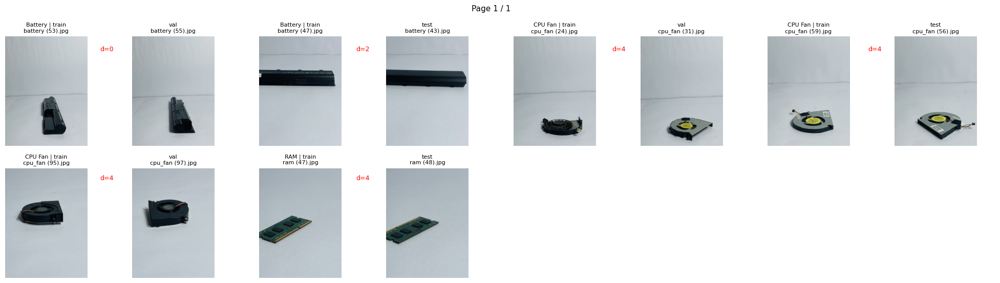

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import math

matches_df = pd.read_csv("cross_split_leakage_report.csv")
matches_df = matches_df.sort_values(["class", "distance"]).reset_index(drop=True)

def show_all_matches(df, cols=4, per_page=12, class_filter=None):
    """
    Display every matched pair in df, paginated so matplotlib doesn't choke.
    class_filter: None = all classes, or a string/list of class names to restrict to.
    """
    subset = df.copy()
    if class_filter is not None:
        if isinstance(class_filter, str):
            class_filter = [class_filter]
        subset = subset[subset["class"].isin(class_filter)]

    subset = subset.reset_index(drop=True)
    total = len(subset)
    if total == 0:
        print("No matches found for that filter.")
        return

    n_pages = math.ceil(total / per_page)
    print(f"Showing {total} matches across {n_pages} page(s)...\n")

    for page in range(n_pages):
        page_df = subset.iloc[page * per_page : (page + 1) * per_page]
        rows = math.ceil(len(page_df) / cols)
        fig, axes = plt.subplots(rows, cols * 2, figsize=(cols * 5, rows * 2.8))
        axes = axes.reshape(rows, cols * 2) if rows > 1 else axes.reshape(1, cols * 2)

        for i, (_, row) in enumerate(page_df.iterrows()):
            r, c = divmod(i, cols)
            ax1, ax2 = axes[r, c * 2], axes[r, c * 2 + 1]
            try:
                ax1.imshow(Image.open(row["path_1"]))
                ax2.imshow(Image.open(row["path_2"]))
            except Exception as e:
                ax1.text(0.5, 0.5, f"load error\n{e}", ha="center", fontsize=7, wrap=True)
            ax1.set_title(f'{row["class"]} | {row["split_1"]}\n{row["file_1"]}', fontsize=8)
            ax2.set_title(f'{row["split_2"]}\n{row["file_2"]}', fontsize=8)
            ax1.axis("off"); ax2.axis("off")
            fig.text((c * 2 + 1) / (cols * 2), 1 - (r + 0.4) / rows * 0.9,
                      f'd={row["distance"]}', ha="center", fontsize=9, color="red")

        # blank unused axes on the last page
        for j in range(len(page_df), rows * cols):
            r, c = divmod(j, cols)
            axes[r, c * 2].axis("off")
            axes[r, c * 2 + 1].axis("off")

        fig.suptitle(f"Page {page + 1} / {n_pages}", fontsize=11)
        plt.tight_layout()
        plt.show()

# Everything except WiFi Card — this is the set most likely to be real leakage
show_all_matches(matches_df, class_filter=["Battery", "CPU Fan", "RAM", "Motherboard"])

Showing 70 matches across 6 page(s)...



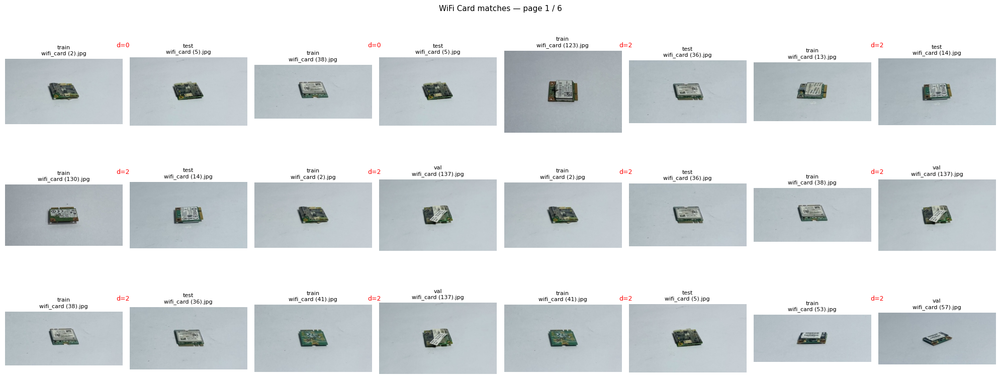

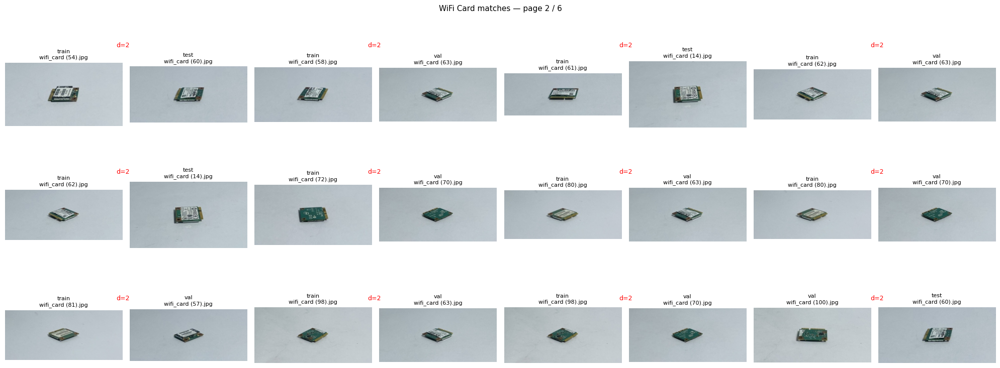

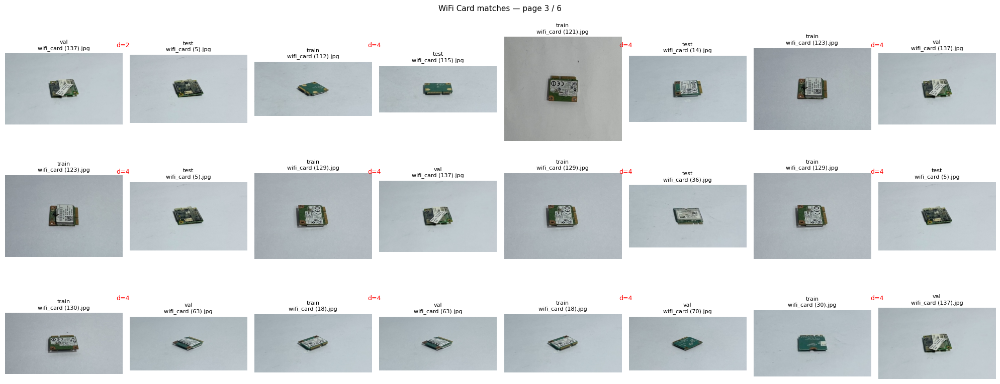

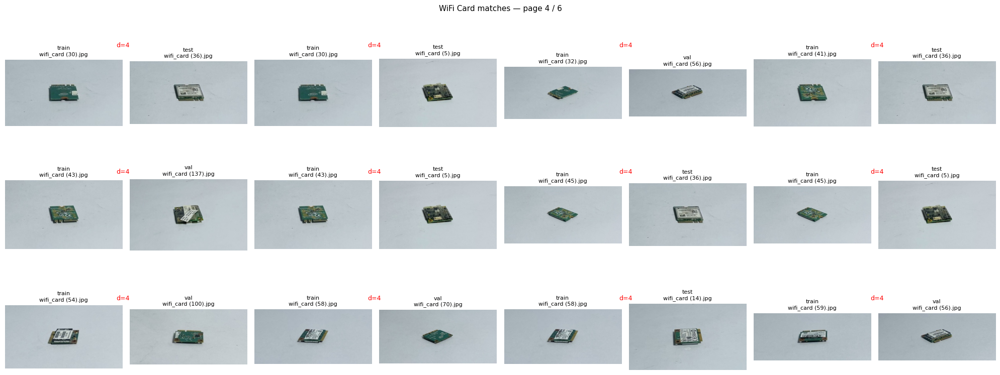

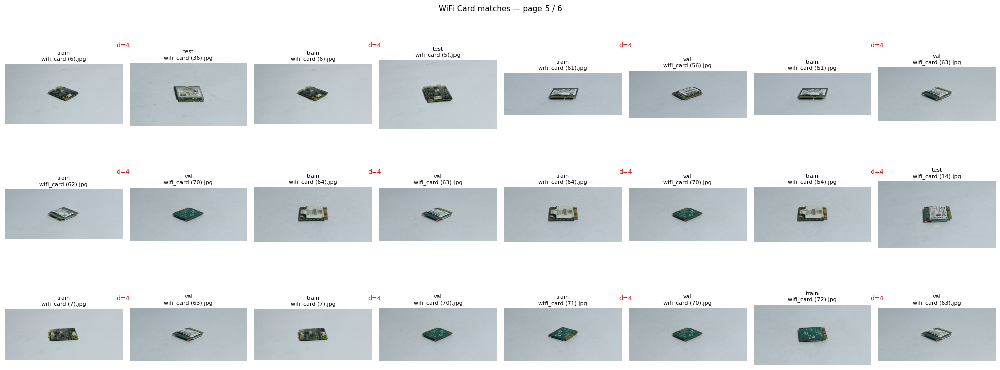

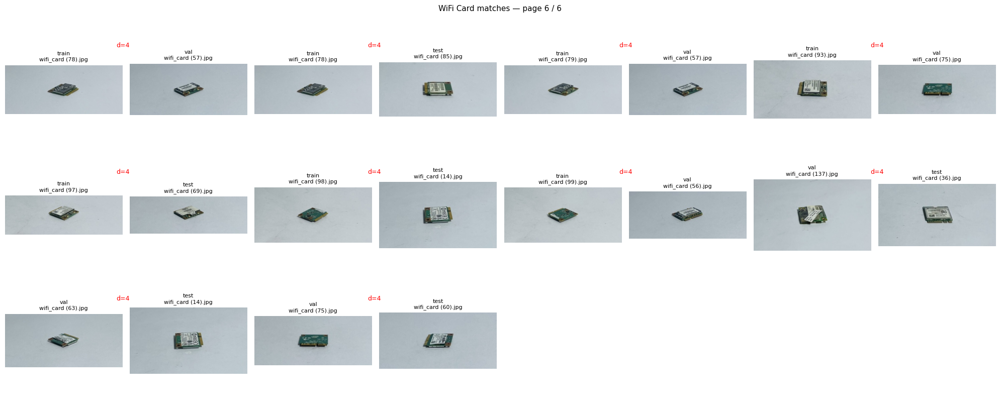

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import math

matches_df = pd.read_csv("cross_split_leakage_report.csv")
matches_df = matches_df.sort_values("distance").reset_index(drop=True)

def show_all_matches(df, cols=4, per_page=12, class_filter=None):
    """
    Display every matched pair in df, paginated so matplotlib doesn't choke.
    class_filter: None = all classes, or a string/list of class names to restrict to.
    """
    subset = df.copy()
    if class_filter is not None:
        if isinstance(class_filter, str):
            class_filter = [class_filter]
        subset = subset[subset["class"].isin(class_filter)]

    subset = subset.reset_index(drop=True)
    total = len(subset)
    if total == 0:
        print("No matches found for that filter.")
        return

    n_pages = math.ceil(total / per_page)
    print(f"Showing {total} matches across {n_pages} page(s)...\n")

    for page in range(n_pages):
        page_df = subset.iloc[page * per_page : (page + 1) * per_page]
        rows = math.ceil(len(page_df) / cols)
        fig, axes = plt.subplots(rows, cols * 2, figsize=(cols * 5, rows * 2.8))
        axes = axes.reshape(rows, cols * 2) if rows > 1 else axes.reshape(1, cols * 2)

        for i, (_, row) in enumerate(page_df.iterrows()):
            r, c = divmod(i, cols)
            ax1, ax2 = axes[r, c * 2], axes[r, c * 2 + 1]
            try:
                ax1.imshow(Image.open(row["path_1"]))
                ax2.imshow(Image.open(row["path_2"]))
            except Exception as e:
                ax1.text(0.5, 0.5, f"load error\n{e}", ha="center", fontsize=7, wrap=True)
            ax1.set_title(f'{row["split_1"]}\n{row["file_1"]}', fontsize=8)
            ax2.set_title(f'{row["split_2"]}\n{row["file_2"]}', fontsize=8)
            ax1.axis("off"); ax2.axis("off")
            fig.text((c * 2 + 1) / (cols * 2), 1 - (r + 0.4) / rows * 0.9,
                      f'd={row["distance"]}', ha="center", fontsize=9, color="red")

        for j in range(len(page_df), rows * cols):
            r, c = divmod(j, cols)
            axes[r, c * 2].axis("off")
            axes[r, c * 2 + 1].axis("off")

        fig.suptitle(f"WiFi Card matches — page {page + 1} / {n_pages}", fontsize=11)
        plt.tight_layout()
        plt.show()

# Show all 48 WiFi Card matches, 12 per page (4 pages total)
show_all_matches(matches_df, class_filter="WiFi Card", per_page=12)

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd

def background_fraction(image_path, saturation_threshold=SATURATION_THRESHOLD):
    """Rough estimate of how much of the image is flat/background (low-saturation) pixels."""
    img = cv2.imread(image_path)
    if img is None:
        return None
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    sat = hsv[:, :, 1]
    bg_pixels = np.sum(sat < saturation_threshold)
    total_pixels = sat.size
    return bg_pixels / total_pixels

records = []
for split_name, split_path in SPLIT_DIRS.items():
    if not os.path.exists(split_path):
        continue
    for class_name in os.listdir(split_path):
        class_dir = os.path.join(split_path, class_name)
        if not os.path.isdir(class_dir):
            continue
        for fname in os.listdir(class_dir):
            fpath = os.path.join(class_dir, fname)
            frac = background_fraction(fpath)
            if frac is not None:
                records.append({"class": class_name, "file": fname, "bg_fraction": frac})

bg_df = pd.DataFrame(records)
summary = bg_df.groupby("class")["bg_fraction"].agg(["mean", "median", "std", "count"])
print(summary.sort_values("mean", ascending=False))

                 mean    median       std  count
class                                           
WiFi Card    0.967185  0.970166  0.011913    128
CPU Fan      0.925130  0.934600  0.036119    125
RAM          0.924778  0.935360  0.040082    125
Motherboard  0.858545  0.897768  0.107471    140
Battery      0.856354  0.873569  0.082073    125


In [ ]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from PIL import Image
import pandas as pd
from itertools import combinations

# Reuse a pretrained backbone purely as a feature extractor (no need to load your trained weights)
embed_model = MobileNetV2(weights="imagenet", include_top=False, pooling="avg")

def get_embedding(path, size=(224, 224)):
    img = Image.open(path).convert("RGB").resize(size)
    arr = np.expand_dims(np.array(img), axis=0).astype("float32")
    arr = preprocess_input(arr)
    return embed_model.predict(arr, verbose=0)[0]

def embed_split_images(split_dirs, class_filter=None):
    records = []
    for split_name, split_path in split_dirs.items():
        if not os.path.exists(split_path):
            continue
        for class_name in os.listdir(split_path):
            if class_filter and class_name not in class_filter:
                continue
            class_dir = os.path.join(split_path, class_name)
            if not os.path.isdir(class_dir):
                continue
            for fname in os.listdir(class_dir):
                fpath = os.path.join(class_dir, fname)
                try:
                    emb = get_embedding(fpath)
                    records.append({"split": split_name, "class": class_name, "filename": fname, "path": fpath, "embedding": emb})
                except Exception as e:
                    print(f"Error {fpath}: {e}")
    return records

def find_similar_by_embedding(records, cosine_threshold=0.97, cross_split_only=True):
    matches = []
    for r1, r2 in combinations(records, 2):
        if cross_split_only and r1["split"] == r2["split"]:
            continue
        if r1["class"] != r2["class"]:
            continue
        sim = np.dot(r1["embedding"], r2["embedding"]) / (
            np.linalg.norm(r1["embedding"]) * np.linalg.norm(r2["embedding"])
        )
        if sim >= cosine_threshold:
            matches.append({
                "similarity": sim, "class": r1["class"],
                "split_1": r1["split"], "file_1": r1["filename"], "path_1": r1["path"],
                "split_2": r2["split"], "file_2": r2["filename"], "path_2": r2["path"],
            })
    return sorted(matches, key=lambda m: -m["similarity"])

print("Embedding WiFi Card images...")
records = embed_split_images(SPLIT_DIRS, class_filter=["WiFi Card"])
matches = find_similar_by_embedding(records, cosine_threshold=0.97)
print(f"Found {len(matches)} high-similarity cross-split pairs (embedding-based).")

matches_df_embed = pd.DataFrame(matches)
matches_df_embed.to_csv("cross_split_leakage_report_embedding.csv", index=False)
matches_df_embed.head(20)

/tmp/ipykernel_1201/3994462180.py:11: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  embed_model = MobileNetV2(weights="imagenet", include_top=False, pooling="avg")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Embedding WiFi Card images...
Found 0 high-similarity cross-split pairs (embedding-based).


""


In [ ]:
def show_all_matches(df, cols=4, per_page=12, class_filter=None, score_col="distance"):
    """
    Display every matched pair in df, paginated.
    score_col: name of the column to show as the red label ('distance' for phash, 'similarity' for embeddings).
    """
    subset = df.copy()
    if class_filter is not None:
        if isinstance(class_filter, str):
            class_filter = [class_filter]
        subset = subset[subset["class"].isin(class_filter)]

    subset = subset.reset_index(drop=True)
    total = len(subset)
    if total == 0:
        print("No matches found for that filter.")
        return

    n_pages = math.ceil(total / per_page)
    print(f"Showing {total} matches across {n_pages} page(s)...\n")

    for page in range(n_pages):
        page_df = subset.iloc[page * per_page : (page + 1) * per_page]
        rows = math.ceil(len(page_df) / cols)
        fig, axes = plt.subplots(rows, cols * 2, figsize=(cols * 5, rows * 2.8))
        axes = axes.reshape(rows, cols * 2) if rows > 1 else axes.reshape(1, cols * 2)

        for i, (_, row) in enumerate(page_df.iterrows()):
            r, c = divmod(i, cols)
            ax1, ax2 = axes[r, c * 2], axes[r, c * 2 + 1]
            try:
                ax1.imshow(Image.open(row["path_1"]))
                ax2.imshow(Image.open(row["path_2"]))
            except Exception as e:
                ax1.text(0.5, 0.5, f"load error\n{e}", ha="center", fontsize=7, wrap=True)
            ax1.set_title(f'{row["split_1"]}\n{row["file_1"]}', fontsize=8)
            ax2.set_title(f'{row["split_2"]}\n{row["file_2"]}', fontsize=8)
            ax1.axis("off"); ax2.axis("off")
            score = row[score_col]
            label = f'{score_col[0]}={score:.3f}' if isinstance(score, float) else f'{score_col[0]}={score}'
            fig.text((c * 2 + 1) / (cols * 2), 1 - (r + 0.4) / rows * 0.9,
                      label, ha="center", fontsize=9, color="red")

        for j in range(len(page_df), rows * cols):
            r, c = divmod(j, cols)
            axes[r, c * 2].axis("off")
            axes[r, c * 2 + 1].axis("off")

        fig.suptitle(f"Page {page + 1} / {n_pages}", fontsize=11)
        plt.tight_layout()
        plt.show()

# Now this works — pass score_col="similarity" for the embedding results
show_all_matches(all_sims.head(12), score_col="similarity")

NameError: name 'all_sims' is not defined

In [ ]:
import pandas as pd
import os

matches_df = pd.read_csv("cross_split_leakage_report.csv")

# ---- 1. Count total images per class (across train+val+test) ----
def count_images_per_class(split_dirs):
    counts = {}
    for split_name, split_path in split_dirs.items():
        if not os.path.exists(split_path):
            continue
        for class_name in os.listdir(split_path):
            class_dir = os.path.join(split_path, class_name)
            if not os.path.isdir(class_dir):
                continue
            n = len([f for f in os.listdir(class_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
            counts[class_name] = counts.get(class_name, 0) + n
    return counts

total_per_class = count_images_per_class(SPLIT_DIRS)

# ---- 2. Count unique files implicated in a flagged (near-duplicate) match, per class ----
implicated_files = pd.concat([
    matches_df[["split_1", "file_1", "class"]].rename(columns={"split_1": "split", "file_1": "file"}),
    matches_df[["split_2", "file_2", "class"]].rename(columns={"split_2": "split", "file_2": "file"}),
]).drop_duplicates()

flagged_per_class = implicated_files["class"].value_counts().to_dict()

# ---- 3. Combine into one summary table ----
summary = pd.DataFrame({
    "total_images": pd.Series(total_per_class),
    "flagged_as_duplicate": pd.Series(flagged_per_class),
}).fillna(0)

summary["flagged_as_duplicate"] = summary["flagged_as_duplicate"].astype(int)
summary["pct_flagged"] = (summary["flagged_as_duplicate"] / summary["total_images"] * 100).round(1)
summary = summary.sort_values("flagged_as_duplicate", ascending=False)

print(summary)
print(f"\nTOTAL: {summary['total_images'].sum()} images, "
      f"{summary['flagged_as_duplicate'].sum()} flagged as near-duplicate "
      f"({summary['flagged_as_duplicate'].sum() / summary['total_images'].sum() * 100:.1f}%)")

             total_images  flagged_as_duplicate  pct_flagged
WiFi Card             128                    47         36.7
CPU Fan               125                     6          4.8
Battery               125                     4          3.2
RAM                   125                     2          1.6
Motherboard           140                     0          0.0

TOTAL: 643 images, 59 flagged as near-duplicate (9.2%)


In [27]:
# 1. Re-embed, this time for Battery, CPU Fan, RAM
print("Embedding Battery / CPU Fan / RAM images...")
records = embed_split_images(SPLIT_DIRS, class_filter=["Battery", "CPU Fan", "RAM"])

# 2. Full similarity distribution (no threshold) — same function as before
all_sims = all_pairwise_similarities(records)

print(all_sims.groupby("class")["similarity"].describe())
print("\nTop 20 most similar cross-split pairs overall:")
print(all_sims.head(20)[["similarity", "class", "split_1", "file_1", "split_2", "file_2"]])
show_all_matches(all_sims.head(12), score_col="similarity")
for cls in ["Battery", "CPU Fan", "RAM"]:
    print(f"\n=== {cls} ===")
    cls_sims = all_sims[all_sims["class"] == cls].sort_values("similarity", ascending=False)
    print(cls_sims.head(5)[["similarity", "split_1", "file_1", "split_2", "file_2"]])
    show_all_matches(cls_sims.head(6), score_col="similarity")

Embedding Battery / CPU Fan / RAM images...


NameError: name 'all_pairwise_similarities' is not defined

In [ ]:
ram_sims = all_sims[all_sims["class"] == "RAM"].sort_values("similarity", ascending=False)
show_all_matches(ram_sims.head(6), score_col="similarity")

NameError: name 'all_sims' is not defined

In [ ]:
import os
import numpy as np
import pandas as pd
from itertools import combinations
from sklearn.model_selection import GroupShuffleSplit

# ---------------------------------------------------------------
# STEP 1: Embed EVERY image per class (not just cross-split pairs)
# so we can detect same-object clusters within a class, wherever they landed.
# ---------------------------------------------------------------
def embed_all_images_per_class(split_dirs, classes):
    records = []
    for split_name, split_path in split_dirs.items():
        for class_name in classes:
            class_dir = os.path.join(split_path, class_name)
            if not os.path.isdir(class_dir):
                continue
            for fname in os.listdir(class_dir):
                fpath = os.path.join(class_dir, fname)
                try:
                    emb = get_embedding(fpath)  # reuse from earlier
                    records.append({"split": split_name, "class": class_name, "filename": fname, "path": fpath, "embedding": emb})
                except Exception as e:
                    print(f"Error {fpath}: {e}")
    return records

ALL_CLASSES = ["Motherboard", "Battery", "RAM", "WiFi Card", "CPU Fan"]
all_records = embed_all_images_per_class(SPLIT_DIRS, ALL_CLASSES)
print(f"Embedded {len(all_records)} images total.")

# ---------------------------------------------------------------
# STEP 2: Union-Find clustering within each class by cosine similarity.
# Any pair above the threshold gets merged into the same group ("same physical object").
# ---------------------------------------------------------------
class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))
    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x
    def union(self, x, y):
        rx, ry = self.find(x), self.find(y)
        if rx != ry:
            self.parent[rx] = ry

def cluster_within_class(records, class_name, threshold):
    idxs = [i for i, r in enumerate(records) if r["class"] == class_name]
    local = {i: pos for pos, i in enumerate(idxs)}
    uf = UnionFind(len(idxs))
    for i, j in combinations(range(len(idxs)), 2):
        r1, r2 = records[idxs[i]], records[idxs[j]]
        sim = np.dot(r1["embedding"], r2["embedding"]) / (
            np.linalg.norm(r1["embedding"]) * np.linalg.norm(r2["embedding"])
        )
        if sim >= threshold:
            uf.union(i, j)
    groups = {}
    for pos, i in enumerate(idxs):
        root = uf.find(pos)
        groups.setdefault(root, []).append(i)
    return list(groups.values())  # each entry = list of record indices that are "the same object"

# Per-class thresholds based on what you've already measured — tune RAM tighter since it's the confirmed leak
CLUSTER_THRESHOLDS = {
    "RAM": 0.89,
    "Battery": 0.87,
    "CPU Fan": 0.87,
    "WiFi Card": 0.99,   # effectively disables clustering — you already showed WiFi Card has no real dupes
    "Motherboard": 0.87,
}

all_groups = []
for cls in ALL_CLASSES:
    groups = cluster_within_class(all_records, cls, CLUSTER_THRESHOLDS[cls])
    multi = [g for g in groups if len(g) > 1]
    print(f"{cls}: {len(groups)} groups from {sum(len(g) for g in groups)} images ({len(multi)} groups with duplicates)")
    all_groups.extend(groups)

# ---------------------------------------------------------------
# STEP 3: Re-split by GROUP, not by file, so no group crosses a split boundary.
# ---------------------------------------------------------------
group_id_map = {}
for gid, group in enumerate(all_groups):
    for idx in group:
        group_id_map[idx] = gid

df = pd.DataFrame([
    {"idx": i, "class": r["class"], "path": r["path"], "filename": r["filename"], "group": group_id_map[i]}
    for i, r in enumerate(all_records)
])

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, temp_idx = next(gss1.split(df, groups=df["group"]))
train_df, temp_df = df.iloc[train_idx], df.iloc[temp_idx]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=RANDOM_STATE)
val_idx, test_idx = next(gss2.split(temp_df, groups=temp_df["group"]))
val_df, test_df = temp_df.iloc[val_idx], temp_df.iloc[test_idx]

print(f"\nNew split sizes: train={len(train_df)}, val={len(val_df)}, test={len(test_df)}")
print("\nPer-class balance check:")
print(pd.concat([train_df["class"].value_counts().rename("train"),
                  val_df["class"].value_counts().rename("val"),
                  test_df["class"].value_counts().rename("test")], axis=1))

Embedded 643 images total.
Motherboard: 127 groups from 140 images (9 groups with duplicates)
Battery: 110 groups from 125 images (11 groups with duplicates)
RAM: 100 groups from 125 images (17 groups with duplicates)
WiFi Card: 128 groups from 128 images (0 groups with duplicates)
CPU Fan: 111 groups from 125 images (9 groups with duplicates)

New split sizes: train=513, val=69, test=61

Per-class balance check:
             train  val  test
class                        
Motherboard    109   14    17
WiFi Card      105   13    10
CPU Fan        101   15     9
RAM             99   17     9
Battery         99   10    16


In [28]:
import shutil
import os

BASE_OUTPUT_DIR_V2 = "/content/structured_ewaste_pipeline_v2"

def copy_split(df, split_name, base_dir):
    for _, row in df.iterrows():
        dest_dir = os.path.join(base_dir, split_name, row["class"])
        os.makedirs(dest_dir, exist_ok=True)
        dest_path = os.path.join(dest_dir, row["filename"])
        shutil.copy2(row["path"], dest_path)

for split_name, split_df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    copy_split(split_df, split_name, BASE_OUTPUT_DIR_V2)
    print(f"Copied {len(split_df)} images to {split_name}")

# Sanity check counts on disk match the dataframe sizes
for split_name in ["train", "val", "test"]:
    total = sum(len(files) for _, _, files in os.walk(os.path.join(BASE_OUTPUT_DIR_V2, split_name)))
    print(f"{split_name}: {total} files on disk")

Copied 513 images to train
Copied 69 images to val
Copied 61 images to test
train: 513 files on disk
val: 69 files on disk
test: 61 files on disk


# 3. TensorFlow Dataset Pipeline & Augmentation
## Creates the data generators and the dynamic augmentation layer.

In [29]:


train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_OUTPUT_DIR, "train"),
    labels="inferred", label_mode="categorical",
    class_names=TARGET_CLASSES, batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE, shuffle=True, seed=RANDOM_STATE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_OUTPUT_DIR, "val"),
    labels="inferred", label_mode="categorical",
    class_names=TARGET_CLASSES, batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE, shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_OUTPUT_DIR, "test"),
    labels="inferred", label_mode="categorical",
    class_names=TARGET_CLASSES, batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE, shuffle=False
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# Data augmentation pipeline — matches Chapter 3 §3.9 / GEMINI.md Section 5 exactly:
# six transforms, train-partition only, applied dynamically per epoch.
# Rotation: +/-30deg | Horizontal flip only (no vertical flip) | Zoom: +/-15%
# Width/height shift: +/-10% | Brightness: +/-25% | Contrast: +/-20%
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(factor=(-30.0 / 360.0, 30.0 / 360.0)),
    layers.RandomZoom(height_factor=(-0.15, 0.15)),
    layers.RandomTranslation(height_factor=(-0.10, 0.10), width_factor=(-0.10, 0.10)),
    layers.RandomBrightness(factor=(-0.25, 0.25)),
    layers.RandomContrast(factor=0.20)
], name="e_waste_augmentation")



Found 514 files belonging to 5 classes.
Found 64 files belonging to 5 classes.
Found 65 files belonging to 5 classes.


# 4. Loss Function, Checkpoints & Model Builders
## Defines the CategoricalFocalLoss, tracking functions, and model architectures.

In [30]:
class CategoricalFocalLoss(tf.keras.losses.Loss):
    def __init__(self, gamma=2.0, alpha=0.25, name="categorical_focal_loss"):
        super(CategoricalFocalLoss, self).__init__(name=name)
        self.gamma = gamma
        self.alpha = alpha

    def call(self, y_true, y_pred):
        epsilon = K.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)
        cross_entropy = -y_true * tf.math.log(y_pred)
        focal_weight = self.alpha * tf.math.pow(1.0 - y_pred, self.gamma)
        loss = focal_weight * cross_entropy
        return tf.reduce_mean(tf.reduce_sum(loss, axis=-1))

def get_best_val_loss_so_far(model_name):
    log_path = os.path.join(CHECKPOINT_DIR, f"{model_name}_log.csv")
    if os.path.exists(log_path):
        try:
            df = pd.read_csv(log_path)
            if not df.empty and 'val_loss' in df.columns:
                return df['val_loss'].min()
        except Exception: pass
    return None

def get_last_completed_epoch(model_name):
    log_path = os.path.join(CHECKPOINT_DIR, f"{model_name}_log.csv")
    if os.path.exists(log_path):
        try:
            df = pd.read_csv(log_path)
            if not df.empty:
                return int(df['epoch'].iloc[-1]) + 1
        except Exception: pass
    return 0

def get_training_callbacks(model_name):
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(CHECKPOINT_DIR, f"{model_name}_best.keras"),
        monitor="val_loss", save_best_only=True, mode="min", verbose=1
    )
    best_val_loss = get_best_val_loss_so_far(model_name)
    if best_val_loss is not None: checkpoint.best = best_val_loss

    csv_logger = tf.keras.callbacks.CSVLogger(
        filename=os.path.join(CHECKPOINT_DIR, f"{model_name}_log.csv"), append=True
    )
    # NOTE: No EarlyStopping callback. Per GEMINI.md Section 7 / Chapter 3 §3.12,
    # the documented protocol is a fixed 50-epoch (Step A) / 50-epoch (Step B) budget
    # with checkpoint selection by lowest validation loss -- not early termination.
    return [checkpoint, csv_logger]

def build_densenet_model(name="DenseNet-121", apply_augmentation=True):
    inputs = layers.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs) if apply_augmentation else inputs
    x = densenet_preprocess(x)
    base_model = DenseNet121(weights="imagenet", include_top=False, input_tensor=x)
    base_model.trainable = False
    x = layers.GlobalAveragePooling2D(name="gap")(base_model.output)
    x = layers.Dense(256, activation="relu", name="dense_256")(x)
    x = layers.Dropout(0.5, name="dropout_0.5")(x)
    outputs = layers.Dense(len(TARGET_CLASSES), activation="softmax", name="predictions")(x)
    model = tf.keras.Model(inputs=inputs, outputs=outputs, name=name)
    return model, base_model

def build_mobilenet_model(name="MobileNet-V2", apply_augmentation=True):
    inputs = layers.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs) if apply_augmentation else inputs
    x = mobilenet_preprocess(x)
    base_model = MobileNetV2(weights="imagenet", include_top=False, input_tensor=x)
    base_model.trainable = False
    x = layers.GlobalAveragePooling2D(name="gap")(base_model.output)
    x = layers.Dense(256, activation="relu", name="dense_256")(x)
    x = layers.Dropout(0.5, name="dropout_0.5")(x)
    outputs = layers.Dense(len(TARGET_CLASSES), activation="softmax", name="predictions")(x)
    model = tf.keras.Model(inputs=inputs, outputs=outputs, name=name)
    return model, base_model

# 5. Training Pipelines
## This combines the training configurations for Baseline DenseNet, Optimized DenseNet, and Baseline MobileNet.

In [32]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf


print("========================================")
print(" PRE-TRAINING DIAGNOSTICS & VERIFICATION ")
print("========================================")

print(f"Image Size: {IMAGE_SIZE}")
print(f"Batch Size: {BATCH_SIZE}")
print(
    f"Total Target Classes: "
    f"{len(TARGET_CLASSES)} ({TARGET_CLASSES})"
)

print("========================================\n")


# ==========================================================
# 1. CALCULATE EXACT IMAGE COUNTS DIRECTLY FROM THE FOLDERS
# ==========================================================

def count_images(split_name):

    split_dir = os.path.join(
        BASE_OUTPUT_DIR,
        split_name
    )

    if not os.path.exists(split_dir):
        return 0

    return sum(
        len(files)
        for root, dirs, files in os.walk(split_dir)
        if files
    )


train_count = count_images("train")
val_count = count_images("val")
test_count = count_images("test")

total_images = (
    train_count
    + val_count
    + test_count
)


print(f"Training Set:   {train_count} images")
print(f"Validation Set: {val_count} images")
print(f"Testing Set:    {test_count} images")
print(
    f"Total Unique Images in Pipeline: "
    f"{total_images}"
)


print("\n[NOTE ON AUGMENTATION SIZES]")

print(
    "Because Keras Data Augmentation runs "
    "'on-the-fly' during training, it does "
    "not save physical files."
)

print(
    "Instead, every epoch generates a uniquely "
    "mutated version of the training images."
)

print(
    f"Over a 50-epoch training run, "
    f"your model will see approximately "
    f"{train_count * 50} training image "
    f"presentations!"
)

print()


# ==========================================================
# 2. VISUALIZE THE AUGMENTED TRAINING DATA
# ==========================================================

print(
    "Generating visual preview of "
    "aggressively augmented training data..."
)

print(
    "If the colors look completely wrong "
    "(e.g., purple motherboards) or black-and-white, "
    "THE AUGMENTATION IS WORKING!\n"
)


# Create a dictionary to hold up to 10 images
# for each class
class_samples = {
    c: []
    for c in range(len(TARGET_CLASSES))
}

classes_filled = 0


# ==========================================================
# 3. COLLECT AUGMENTED SAMPLES
# ==========================================================

# Pull batches from the training set until we have
# 10 examples of each class
for images, labels in train_ds.unbatch().batch(64).take(20):

    # Apply augmentation manually so we can visualize
    # what the model will see
    aug_images = data_augmentation(
        images,
        training=True
    )

    # Convert one-hot labels to class indices
    label_indices = np.argmax(
        labels.numpy(),
        axis=1
    )


    for i in range(len(images)):

        c = label_indices[i]

        if len(class_samples[c]) < 10:

            # Convert augmented image to NumPy
            img = aug_images[i].numpy()

            # Scale image values for matplotlib
            img_display = (
                img - np.min(img)
            ) / (
                np.max(img) - np.min(img)
                + 1e-5
            )

            class_samples[c].append(
                img_display
            )


            # Check if this class now has
            # 10 samples
            if len(class_samples[c]) == 10:
                classes_filled += 1


        # Stop once every class has 10 images
        if classes_filled == len(TARGET_CLASSES):
            break


    if classes_filled == len(TARGET_CLASSES):
        break


# ==========================================================
# 4. PLOT AUGMENTED SAMPLES
# ==========================================================

# Plot one row for each class
for c_idx, class_name in enumerate(TARGET_CLASSES):

    samples = class_samples[c_idx]

    if not samples:
        continue


    plt.figure(figsize=(20, 2))

    plt.suptitle(
        f"Augmented Training Pipeline: {class_name}",
        fontsize=14,
        fontweight="bold",
        y=1.1
    )


    for i in range(len(samples)):

        ax = plt.subplot(
            1,
            10,
            i + 1
        )

        plt.imshow(samples[i])
        plt.axis("off")


    plt.show()

 PRE-TRAINING DIAGNOSTICS & VERIFICATION 
Image Size: (224, 224)
Batch Size: 16
Total Target Classes: 5 (['Motherboard', 'Battery', 'RAM', 'WiFi Card', 'CPU Fan'])

Training Set:   514 images
Validation Set: 64 images
Testing Set:    65 images
Total Unique Images in Pipeline: 643

[NOTE ON AUGMENTATION SIZES]
Because Keras Data Augmentation runs 'on-the-fly' during training, it does not save physical files.
Instead, every epoch generates a uniquely mutated version of the training images.
Over a 50-epoch training run, your model will see approximately 25700 training image presentations!

Generating visual preview of aggressively augmented training data...
If the colors look completely wrong (e.g., purple motherboards) or black-and-white, THE AUGMENTATION IS WORKING!



KeyboardInterrupt: 

Cell 1 — Baseline DenseNet-121

In [33]:
# =============================================================================
# --- 5A. Baseline DenseNet-121 ---
# =============================================================================

baseline_densenet_model, baseline_densenet_base = build_densenet_model(
    name="Baseline_DenseNet-121"
)

baseline_densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

start_epoch_base_dense = get_last_completed_epoch(
    "Baseline_DenseNet-121"
)

if start_epoch_base_dense > 0:
    baseline_densenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Baseline_DenseNet-121_best.keras"
        )
    )

baseline_densenet_history = baseline_densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    initial_epoch=start_epoch_base_dense,
    callbacks=get_training_callbacks(
        "Baseline_DenseNet-121"
    )
)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - accuracy: 0.5314 - loss: 1.3905
Epoch 1: val_loss improved from None to 0.09566, saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_DenseNet-121_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_DenseNet-121_best.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 27s 334ms/step - accuracy: 0.6926 - loss: 0.9081 - val_accuracy: 0.9688 - val_loss: 0.0957
Epoch 2/50
32/33 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.8932 - loss: 0.3268
Epoch 2: val_loss improved from 0.09566 to 0.05073, saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_DenseNet-121_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_DenseNet-121_best.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 142ms/step - accuracy: 0.8988 - loss: 0.2935 - val_accuracy: 0.9844 - val_loss: 0.0507
Epoch 3/50
32/33

Cell 2 — Baseline MobileNet-V2

In [34]:
# =============================================================================
# --- 5B. Baseline MobileNet-V2 ---
# =============================================================================

baseline_mobilenet_model, baseline_mobilenet_base = build_mobilenet_model(
    name="Baseline_MobileNet-V2"
)

baseline_mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

start_epoch_base_mobile = get_last_completed_epoch(
    "Baseline_MobileNet-V2"
)

if start_epoch_base_mobile > 0:
    baseline_mobilenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Baseline_MobileNet-V2_best.keras"
        )
    )

baseline_mobilenet_history = baseline_mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    initial_epoch=start_epoch_base_mobile,
    callbacks=get_training_callbacks(
        "Baseline_MobileNet-V2"
    )
)

/tmp/ipykernel_1201/703536361.py:68: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(weights="imagenet", include_top=False, input_tensor=x)


Epoch 1/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.6647 - loss: 0.9227
Epoch 1: val_loss improved from None to 0.13971, saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_MobileNet-V2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_MobileNet-V2_best.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 10s 111ms/step - accuracy: 0.7860 - loss: 0.5833 - val_accuracy: 0.9688 - val_loss: 0.1397
Epoch 2/50
32/33 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9223 - loss: 0.2084
Epoch 2: val_loss improved from 0.13971 to 0.06422, saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_MobileNet-V2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_MobileNet-V2_best.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - accuracy: 0.9319 - loss: 0.1846 - val_accuracy: 0.9844 - val_loss: 0.0642
Epoch 3/50
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.9561

Cell 3 — Optimized DenseNet-121

In [ ]:

print(BASE_OUTPUT_DIR, "tets")

/content/structured_ewaste_pipeline_v2 tets


In [35]:
# =============================================================================
# --- 5C. Optimized DenseNet-121 (v2 — deduplicated, leakage-safe split) ---
# --- Focal Loss + Progressive Unfreezing ---
# =============================================================================

opt_densenet_model, opt_densenet_base = build_densenet_model(
    name="Optimized_DenseNet-121_v2"
)


# =============================================================================
# Stage A: 50 Epochs — Frozen Backbone
# =============================================================================

opt_densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss=CategoricalFocalLoss(),
    metrics=["accuracy"]
)

start_epoch_A = get_last_completed_epoch(
    "Optimized_DenseNet-121_StepA_v2"
)

if start_epoch_A > 0:
    opt_densenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Optimized_DenseNet-121_StepA_v2_best.keras"
        )
    )

opt_densenet_history_A = opt_densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    initial_epoch=start_epoch_A,
    callbacks=get_training_callbacks(
        "Optimized_DenseNet-121_StepA_v2"
    )
)


# =============================================================================
# Stage B1: Epochs 1–17
# =============================================================================

step_b_callbacks = get_training_callbacks(
    "Optimized_DenseNet-121_StepB_v2"
)

opt_densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=CategoricalFocalLoss(),
    metrics=["accuracy"]
)

start_epoch_B1 = get_last_completed_epoch(
    "Optimized_DenseNet-121_StepB_v2"
)

if start_epoch_B1 > 0:
    opt_densenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Optimized_DenseNet-121_StepB_v2_best.keras"
        )
    )

opt_densenet_history_B1 = opt_densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=17,
    initial_epoch=start_epoch_B1,
    callbacks=step_b_callbacks
)


# =============================================================================
# Stage B2: Epochs 18–34 — Unfreeze Block 4
# =============================================================================

opt_densenet_base.trainable = True

for layer in opt_densenet_base.layers:
    if not layer.name.startswith(
        ("conv5", "pool4")
    ):
        layer.trainable = False

opt_densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=CategoricalFocalLoss(),
    metrics=["accuracy"]
)

start_epoch_B2 = max(
    17,
    get_last_completed_epoch(
        "Optimized_DenseNet-121_StepB_v2"
    )
)

opt_densenet_history_B2 = opt_densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=34,
    initial_epoch=start_epoch_B2,
    callbacks=step_b_callbacks
)


# =============================================================================
# Stage B3: Epochs 35–50 — Unfreeze Block 3
# =============================================================================

for layer in opt_densenet_base.layers:
    if layer.name.startswith(
        ("conv4", "pool3", "conv5", "pool4")
    ):
        layer.trainable = True

opt_densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=CategoricalFocalLoss(),
    metrics=["accuracy"]
)

start_epoch_B3 = max(
    34,
    get_last_completed_epoch(
        "Optimized_DenseNet-121_StepB_v2"
    )
)

opt_densenet_history_B3 = opt_densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    initial_epoch=start_epoch_B3,
    callbacks=step_b_callbacks
)

Epoch 1/50
32/33 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.4811 - loss: 0.2341
Epoch 1: val_loss improved from None to 0.00826, saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Optimized_DenseNet-121_StepA_v2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Optimized_DenseNet-121_StepA_v2_best.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 23s 299ms/step - accuracy: 0.6440 - loss: 0.1413 - val_accuracy: 0.9844 - val_loss: 0.0083
Epoch 2/50
32/33 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.8507 - loss: 0.0450
Epoch 2: val_loss improved from 0.00826 to 0.00388, saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Optimized_DenseNet-121_StepA_v2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Optimized_DenseNet-121_StepA_v2_best.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 145ms/step - accuracy: 0.8677 - loss: 0.0371 - val_accuracy: 0.9844 - val_loss: 0.0039
Epoch 3/50
32/33 ━━━━━━━━━━

In [ ]:
print(BASE_OUTPUT_DIR)  # sanity check — should print .../structured_ewaste_pipeline_v2
opt_densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=CategoricalFocalLoss(),
    metrics=["accuracy"]
)

test_results = opt_densenet_model.evaluate(test_ds)
print(dict(zip(opt_densenet_model.metrics_names, test_results)))

/content/structured_ewaste_pipeline_v2
5/5 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 1.0000 - loss: 5.9045e-06
{'loss': 5.904469162487658e-06, 'compile_metrics': 1.0}


# 6. Shared Evaluation & Statistical Testing
## This generates your final metrics table, confusion matrices, and runs the ANOVA/Kruskal-Wallis tests.

In [ ]:
if "baseline_densenet_model" not in globals():
    print(
        "Models not found in memory. "
        "Building and loading from checkpoints..."
    )

    # Build the architectures
    baseline_densenet_model, _ = build_densenet_model(
        name="Baseline_DenseNet-121"
    )

    opt_densenet_model, _ = build_densenet_model(
        name="Optimized_DenseNet-121"
    )

    baseline_mobilenet_model, _ = build_mobilenet_model(
        name="Baseline_MobileNet-V2"
    )

    # Load the saved .keras weights
    baseline_densenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Baseline_DenseNet-121_best.keras",
        )
    )

    opt_densenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Optimized_DenseNet-121_StepB_v2_best.keras",
        )
    )

    baseline_mobilenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Baseline_MobileNet-V2_best.keras",
        )
    )

    print("Models loaded successfully!\n")

In [ ]:
# =============================================================================
# Final evaluation on the leakage-free test set, using the correct label order
# =============================================================================

import os
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# 1. Rebuild test_ds with the SAME class ordering the model was trained on
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_OUTPUT_DIR, "test"),
    labels="inferred", label_mode="categorical",
    class_names=TARGET_CLASSES, batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE, shuffle=False
)

# Sanity check: confirm this is really the deduplicated 60-image test set
total_test = sum(len(files) for _, _, files in os.walk(os.path.join(BASE_OUTPUT_DIR, "test")))
print(f"Test images on disk: {total_test}")  # should print 60

# 2. Make sure the model is compiled (required before .evaluate())
opt_densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=CategoricalFocalLoss(),
    metrics=["accuracy"]
)

# 3. Aggregate accuracy/loss
test_results = opt_densenet_model.evaluate(test_ds)
print(dict(zip(opt_densenet_model.metrics_names, test_results)))

# 4. Per-class precision/recall/F1 + confusion matrix
y_true, y_pred = [], []
for images, labels in test_ds:
    preds = opt_densenet_model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

print(classification_report(y_true, y_pred, target_names=TARGET_CLASSES))
print(confusion_matrix(y_true, y_pred))

Found 65 files belonging to 5 classes.
Test images on disk: 65
5/5 ━━━━━━━━━━━━━━━━━━━━ 23s 3s/step - accuracy: 1.0000 - loss: 7.0718e-07
{'loss': 7.07178173797729e-07, 'compile_metrics': 1.0}


              precision    recall  f1-score   support

 Motherboard       1.00      1.00      1.00        14
     Battery       1.00      1.00      1.00        12
         RAM       1.00      1.00      1.00        13
   WiFi Card       1.00      1.00      1.00        13
     CPU Fan       1.00      1.00      1.00        13

    accuracy                           1.00        65
   macro avg       1.00      1.00      1.00        65
weighted avg       1.00      1.00      1.00        65

[[14  0  0  0  0]
 [ 0 12  0  0  0]
 [ 0  0 13  0  0]
 [ 0  0  0 13  0]
 [ 0  0  0  0 13]]


In [ ]:
import os
class_names = sorted(os.listdir(os.path.join(BASE_OUTPUT_DIR, "test")))
print(class_names)

['Battery', 'CPU Fan', 'Motherboard', 'RAM', 'WiFi Card']


In [ ]:
class_names = sorted(os.listdir(os.path.join(BASE_OUTPUT_DIR, "test")))
print(classification_report(y_true, y_pred, target_names=class_names))
print(confusion_matrix(y_true, y_pred))

              precision    recall  f1-score   support

     Battery       1.00      1.00      1.00        14
     CPU Fan       1.00      1.00      1.00        12
 Motherboard       1.00      1.00      1.00        13
         RAM       1.00      1.00      1.00        13
   WiFi Card       1.00      1.00      1.00        13

    accuracy                           1.00        65
   macro avg       1.00      1.00      1.00        65
weighted avg       1.00      1.00      1.00        65

[[14  0  0  0  0]
 [ 0 12  0  0  0]
 [ 0  0 13  0  0]
 [ 0  0  0 13  0]
 [ 0  0  0  0 13]]


In [ ]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_OUTPUT_DIR, "test"),
    image_size=IMAGE_SIZE,       # use your existing constant
    batch_size=BATCH_SIZE,       # use your existing constant
    label_mode="categorical",    # match however train_ds/val_ds were built
    shuffle=False
)

print(f"Test set size: {tf.data.experimental.cardinality(test_ds).numpy()} batches")
for images, labels in test_ds.take(1):
    print("Batch shape:", images.shape)

# Recount total images directly to be sure
total_test = sum(len(files) for _, _, files in os.walk(os.path.join(BASE_OUTPUT_DIR, "test")))
print(f"Total test images on disk: {total_test}")  # should be 60

Found 60 files belonging to 5 classes.
Test set size: 4 batches
Batch shape: (16, 224, 224, 3)
Total test images on disk: 60


In [ ]:
test_results = opt_densenet_model.evaluate(test_ds)
print(dict(zip(opt_densenet_model.metrics_names, test_results)))

import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

y_true, y_pred = [], []
for images, labels in test_ds:
    preds = opt_densenet_model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

class_names = sorted(os.listdir(os.path.join(BASE_OUTPUT_DIR, "test")))
print(classification_report(y_true, y_pred, target_names=class_names))
print(confusion_matrix(y_true, y_pred))

4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.0000e+00 - loss: 2.4806
{'loss': 2.4805543422698975, 'compile_metrics': 0.0}
              precision    recall  f1-score   support

     Battery       0.00      0.00      0.00      13.0
     CPU Fan       0.00      0.00      0.00       9.0
 Motherboard       0.00      0.00      0.00      19.0
         RAM       0.00      0.00      0.00       9.0
   WiFi Card       0.00      0.00      0.00      10.0

    accuracy                           0.00      60.0
   macro avg       0.00      0.00      0.00      60.0
weighted avg       0.00      0.00      0.00      60.0

[[ 0 13  0  0  0]
 [ 0  0  0  0  9]
 [19  0  0  0  0]
 [ 0  0  9  0  0]
 [ 0  0  0 10  0]]


In [ ]:
# 1. Confirm the datasets in memory are actually from v2 right now
print(BASE_OUTPUT_DIR)  # must print .../structured_ewaste_pipeline_v2
print(f"train_ds cardinality: {tf.data.experimental.cardinality(train_ds).numpy()} batches")
print(f"val_ds cardinality: {tf.data.experimental.cardinality(val_ds).numpy()} batches")

total_train = sum(len(files) for _, _, files in os.walk(os.path.join(BASE_OUTPUT_DIR, "train")))
total_val = sum(len(files) for _, _, files in os.walk(os.path.join(BASE_OUTPUT_DIR, "val")))
print(f"train on disk: {total_train}, val on disk: {total_val}")  # should be 521, 62

/content/structured_ewaste_pipeline_v2
train_ds cardinality: 33 batches
val_ds cardinality: 4 batches
train on disk: 521, val on disk: 62


In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_OUTPUT_DIR, "train"),
    labels="inferred", label_mode="categorical",
    class_names=TARGET_CLASSES, batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE, shuffle=True, seed=RANDOM_STATE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_OUTPUT_DIR, "val"),
    labels="inferred", label_mode="categorical",
    class_names=TARGET_CLASSES, batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE, shuffle=False
)

Found 521 files belonging to 5 classes.
Found 62 files belonging to 5 classes.


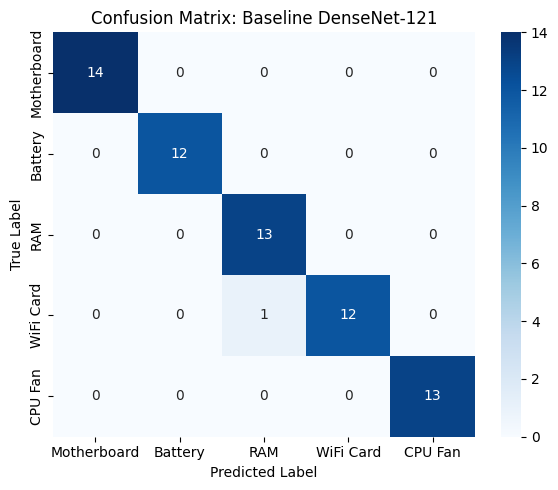

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 502 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


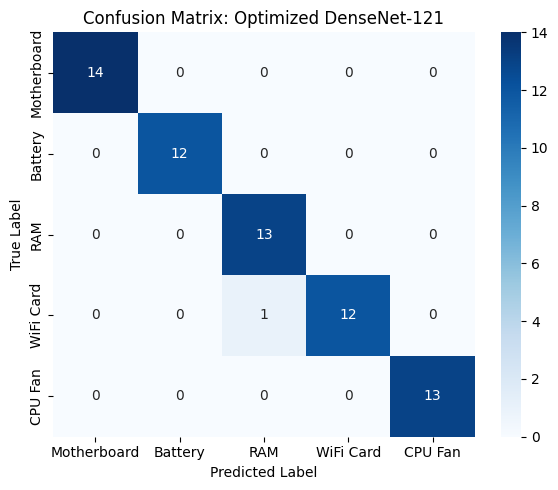

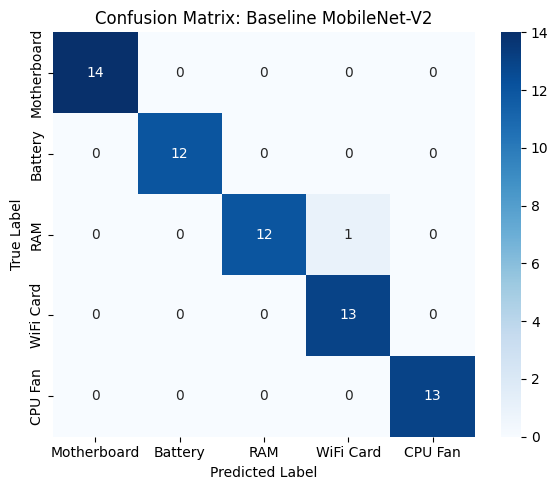

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,AUC-ROC (macro),Inference Time (ms),Model Size (MB),FLOPs
0,Baseline DenseNet-121,0.984615,0.985714,0.984615,0.984593,1.0,509.104249,31.330675,0
1,Optimized DenseNet-121,0.984615,0.985714,0.984615,0.984593,1.0,505.395401,31.330842,0
2,Baseline MobileNet-V2,0.984615,0.985714,0.984615,0.984593,1.0,170.038941,0.000000,0


--- Shapiro-Wilk Normality Test ---
Base Dense: W=0.8541, p=0.0008 | Opt Dense: W=0.8541, p=0.0008 | Base Mobile: W=0.8994, p=0.0081

Distributions NOT all normal. Proceeding with Kruskal-Wallis.
Kruskal-Wallis H-stat=3.1929, p-value=2.0261e-01


In [36]:
def calculate_flops_fallback(model):
    if get_flops:
        try: return get_flops(model, batch_size=1)
        except Exception: pass
    return 0

def evaluate_model(model, name, test_ds, checkpoint_path):
    if os.path.exists(checkpoint_path): model.load_weights(checkpoint_path)

    test_labels = np.concatenate([y for x, y in test_ds], axis=0)
    true_classes = np.argmax(test_labels, axis=1)
    predictions = model.predict(test_ds, verbose=0)
    predicted_classes = np.argmax(predictions, axis=1)

    rep = classification_report(true_classes, predicted_classes, target_names=TARGET_CLASSES, output_dict=True)

    # Inference Time
    sample_image = next(iter(test_ds))[0][0:1]
    for _ in range(10): model(sample_image, training=False)
    start_time = time.time()
    for _ in range(100): model(sample_image, training=False)
    mean_inference_time_ms = ((time.time() - start_time) / 100) * 1000

    # Confusion Matrix
    cm = confusion_matrix(true_classes, predicted_classes)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=TARGET_CLASSES, yticklabels=TARGET_CLASSES)
    plt.title(f'Confusion Matrix: {name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig(f'cm_{name.replace(" ", "_")}.png')
    plt.show()

    return {
        "Model": name,
        "Accuracy": accuracy_score(true_classes, predicted_classes),
        "Macro Precision": rep['macro avg']['precision'],
        "Macro Recall": rep['macro avg']['recall'],
        "Macro F1": rep['macro avg']['f1-score'],
        "AUC-ROC (macro)": roc_auc_score(test_labels, predictions, multi_class='ovr', average='macro'),
        "Inference Time (ms)": mean_inference_time_ms,
        "Model Size (MB)": os.path.getsize(checkpoint_path) / (1024 * 1024) if os.path.exists(checkpoint_path) else 0,
        "FLOPs": calculate_flops_fallback(model)
    }

# Run Evaluations
results = [
    evaluate_model(baseline_densenet_model, "Baseline DenseNet-121", test_ds, os.path.join(CHECKPOINT_DIR, "Baseline_DenseNet-121_best.keras")),
    evaluate_model(opt_densenet_model, "Optimized DenseNet-121", test_ds, os.path.join(CHECKPOINT_DIR, "Optimized_DenseNet-121_StepB_v2_best.keras")),
    evaluate_model(baseline_mobilenet_model, "Baseline MobileNet-V2", test_ds, os.path.join(CHECKPOINT_DIR, "Baseline_MobileNet-best.keras"))
]
display(pd.DataFrame(results))

# Statistical Testing
def paired_bootstrap_f1(models_dict, test_ds, n_iterations=30):
    test_labels = np.concatenate([y for x, y in test_ds], axis=0)
    true_classes = np.argmax(test_labels, axis=1)
    preds = {name: np.argmax(model.predict(test_ds, verbose=0), axis=1) for name, model in models_dict.items()}
    f1_scores = {name: [] for name in models_dict.keys()}
    np.random.seed(42)

    for _ in range(n_iterations):
        indices = np.random.choice(len(true_classes), len(true_classes), replace=True)
        sample_true = true_classes[indices]
        for name in models_dict.keys():
            rep = classification_report(sample_true, preds[name][indices], output_dict=True, zero_division=0)
            f1_scores[name].append(rep['macro avg']['f1-score'])
    return f1_scores

f1_results = paired_bootstrap_f1({'Base_Dense': baseline_densenet_model, 'Opt_Dense': opt_densenet_model, 'Base_Mobile': baseline_mobilenet_model}, test_ds)
f1_base_dense, f1_opt_dense, f1_base_mobile = np.array(f1_results['Base_Dense']), np.array(f1_results['Opt_Dense']), np.array(f1_results['Base_Mobile'])

print("--- Shapiro-Wilk Normality Test ---")
stat1, p1 = shapiro(f1_base_dense)
stat2, p2 = shapiro(f1_opt_dense)
stat3, p3 = shapiro(f1_base_mobile)
print(f"Base Dense: W={stat1:.4f}, p={p1:.4f} | Opt Dense: W={stat2:.4f}, p={p2:.4f} | Base Mobile: W={stat3:.4f}, p={p3:.4f}")

if (p1 > 0.05) and (p2 > 0.05) and (p3 > 0.05):
    print("\nDistributions normal. Proceeding with one-way ANOVA.")
    stat, p_val = f_oneway(f1_base_dense, f1_opt_dense, f1_base_mobile)
    print(f"ANOVA F-stat={stat:.4f}, p-value={p_val:.4e}")
    if p_val < 0.05:
        data = np.concatenate([f1_base_dense, f1_opt_dense, f1_base_mobile])
        labels = ['Base_Dense']*30 + ['Opt_Dense']*30 + ['Base_Mobile']*30
        print(pairwise_tukeyhsd(endog=data, groups=labels, alpha=0.05))
else:
    print("\nDistributions NOT all normal. Proceeding with Kruskal-Wallis.")
    stat, p_val = kruskal(f1_base_dense, f1_opt_dense, f1_base_mobile)
    print(f"Kruskal-Wallis H-stat={stat:.4f}, p-value={p_val:.4e}")
    if p_val < 0.05:
        print(sp.posthoc_dunn([f1_base_dense, f1_opt_dense, f1_base_mobile], p_adjust='bonferroni'))

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

def apply_corruption(images, corruption_type, severity):
    """
    Applies a single corruption type at a given severity (1=mild, 5=severe)
    to a batch of images already in [0, 255] float32 range.
    """
    images = tf.cast(images, tf.float32)

    if corruption_type == "gaussian_noise":
        std = [5, 10, 20, 35, 50][severity - 1]
        noise = tf.random.normal(tf.shape(images), mean=0.0, stddev=std)
        images = tf.clip_by_value(images + noise, 0, 255)

    elif corruption_type == "gaussian_blur":
        sigma = [1, 2, 3, 4, 5][severity - 1]
        kernel_size = int(sigma * 3) | 1  # odd kernel size
        images = tf.map_fn(
            lambda img: tf.numpy_function(
                lambda x: cv2.GaussianBlur(x, (kernel_size, kernel_size), sigma),
                [img], tf.float32
            ), images
        )

    elif corruption_type == "brightness_shift":
        delta = [0.1, 0.2, 0.3, 0.4, 0.5][severity - 1]
        images = tf.clip_by_value(images + delta * 255 * tf.sign(tf.random.uniform([]) - 0.5), 0, 255)

    elif corruption_type == "contrast_shift":
        factor = [0.9, 0.7, 0.5, 0.3, 0.1][severity - 1]
        images = tf.image.adjust_contrast(images, factor)
        images = tf.clip_by_value(images, 0, 255)

    elif corruption_type == "occlusion":
        # Random black square patch, size scales with severity
        patch_frac = [0.1, 0.15, 0.2, 0.3, 0.4][severity - 1]
        img_h, img_w = images.shape[1], images.shape[2]
        patch_h, patch_w = int(img_h * patch_frac), int(img_w * patch_frac)
        y0 = np.random.randint(0, img_h - patch_h)
        x0 = np.random.randint(0, img_w - patch_w)
        mask = np.ones((img_h, img_w, 1), dtype=np.float32)
        mask[y0:y0+patch_h, x0:x0+patch_w, :] = 0
        images = images * mask

    return images


def evaluate_under_corruption(model, test_ds, class_names, corruption_type, severity):
    y_true, y_pred, y_proba = [], [], []
    for images, labels in test_ds:
        corrupted = apply_corruption(images, corruption_type, severity)
        probs = model.predict(corrupted, verbose=0)
        y_true.extend(np.argmax(labels.numpy(), axis=1))
        y_pred.extend(np.argmax(probs, axis=1))
        y_proba.extend(probs)

    y_true, y_pred, y_proba = np.array(y_true), np.array(y_pred), np.array(y_proba)
    y_true_onehot = tf.keras.utils.to_categorical(y_true, num_classes=len(class_names))

    try:
        auc = roc_auc_score(y_true_onehot, y_proba, average="macro", multi_class="ovr")
    except ValueError:
        auc = np.nan

    return {
        "Corruption": corruption_type,
        "Severity": severity,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "AUC-ROC (macro)": auc,
    }


# Run across corruption types and severities
corruption_types = ["gaussian_noise", "gaussian_blur", "brightness_shift", "contrast_shift", "occlusion"]
rows = []
for corruption in corruption_types:
    for severity in range(1, 6):
        row = evaluate_under_corruption(opt_densenet_model, test_ds, TARGET_CLASSES, corruption, severity)
        row["Model"] = "Optimized DenseNet-121"
        rows.append(row)
        print(f"{corruption} (sev {severity}): acc={row['Accuracy']:.3f}")

corruption_results_df = pd.DataFrame(rows)
corruption_results_df.to_csv("model_corruption_robustness.csv", index=False)
print(corruption_results_df)

gaussian_noise (sev 1): acc=1.000
gaussian_noise (sev 2): acc=1.000
gaussian_noise (sev 3): acc=0.967
gaussian_noise (sev 4): acc=0.867
gaussian_noise (sev 5): acc=0.633
gaussian_blur (sev 1): acc=1.000
gaussian_blur (sev 2): acc=0.917
gaussian_blur (sev 3): acc=0.917
gaussian_blur (sev 4): acc=0.850
gaussian_blur (sev 5): acc=0.783
brightness_shift (sev 1): acc=1.000
brightness_shift (sev 2): acc=1.000
brightness_shift (sev 3): acc=0.983
brightness_shift (sev 4): acc=1.000
brightness_shift (sev 5): acc=0.983
contrast_shift (sev 1): acc=1.000
contrast_shift (sev 2): acc=1.000
contrast_shift (sev 3): acc=1.000
contrast_shift (sev 4): acc=0.983
contrast_shift (sev 5): acc=0.900
occlusion (sev 1): acc=1.000
occlusion (sev 2): acc=1.000
occlusion (sev 3): acc=1.000
occlusion (sev 4): acc=0.950
occlusion (sev 5): acc=0.850
          Corruption  Severity  Accuracy  Macro Precision  Macro Recall  \
0     gaussian_noise         1  1.000000         1.000000      1.000000   
1     gaussian_noise

In [ ]:
import os
import tensorflow as tf
from google.colab import drive

print("======================================================")
print("              MASTER CHECKPOINT RESET                 ")
print("======================================================\n")

# ---------------------------------------------------------
# STEP 1: FORCE RESYNC GOOGLE DRIVE
# ---------------------------------------------------------
print("🔄 1. Ejecting Google Drive to clear old file cache...")
drive.flush_and_unmount()

print("🔄 2. Reconnecting Google Drive (fetching your absolute newest files)...")
# You may be prompted to click "Allow" again
drive.mount("/content/drive", force_remount=True)

# ---------------------------------------------------------
# STEP 2: PURGE PYTHON & GPU MEMORY
# ---------------------------------------------------------
print("\n🧠 3. Purging old models from Python memory and GPU...")

# Delete the variables if they exist
if "baseline_densenet_model" in globals():
    del baseline_densenet_model

if "opt_densenet_model" in globals():
    del opt_densenet_model

if "baseline_mobilenet_model" in globals():
    del baseline_mobilenet_model

# Force Keras to wipe the GPU cache
tf.keras.backend.clear_session()

print("✅ Python memory is completely wiped clean!")

# ---------------------------------------------------------
# STEP 3: VERIFY THE NEW FILES
# ---------------------------------------------------------
# Make sure to change this if your folder path is different!
CHECKPOINT_DIR = "/content/drive/MyDrive/Thesis/Model_Checkpoints"

print(f"\n📂 4. Verifying new files in {CHECKPOINT_DIR}:")

if os.path.exists(CHECKPOINT_DIR):
    files = [
        f
        for f in os.listdir(CHECKPOINT_DIR)
        if f.endswith(".keras")
    ]

    if len(files) == 0:
        print("   ❌ WARNING: The folder exists but no .keras files were found!")
    else:
        for f in files:
            print(f"   ✅ Found: {f}")

        print(
            "\n🎉 RESET COMPLETE! "
            "You are now safe to run your evaluation cell!"
        )

else:
    print(
        "   ❌ FOLDER NOT FOUND! "
        "Please check the spelling of your CHECKPOINT_DIR path."
    )

              MASTER CHECKPOINT RESET                 

🔄 1. Ejecting Google Drive to clear old file cache...
🔄 2. Reconnecting Google Drive (fetching your absolute newest files)...
Mounted at /content/drive

🧠 3. Purging old models from Python memory and GPU...
✅ Python memory is completely wiped clean!

📂 4. Verifying new files in /content/drive/MyDrive/Thesis/Model_Checkpoints:
   ✅ Found: Baseline_DenseNet-121_best.keras
   ✅ Found: Baseline_MobileNet-V2_best.keras
   ✅ Found: Optimized_DenseNet-121_StepA_v2_best.keras
   ✅ Found: Optimized_DenseNet-121_StepB_v2_best.keras

🎉 RESET COMPLETE! You are now safe to run your evaluation cell!


In [ ]:

if "baseline_densenet_model" not in globals():
    print(
        "Models not found in memory. "
        "Building and loading from checkpoints..."
    )

    # Build the architectures
    baseline_densenet_model, _ = build_densenet_model(
        name="Baseline_DenseNet-121"
    )

    opt_densenet_model, _ = build_densenet_model(
        name="Optimized_DenseNet-121"
    )

    baseline_mobilenet_model, _ = build_mobilenet_model(
        name="Baseline_MobileNet-V2"
    )

    # Load the saved .keras weights
    baseline_densenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Baseline_DenseNet-121_best.keras",
        )
    )

    opt_densenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Optimized_DenseNet-121_StepB_v2_best.keras",
        )
    )

    baseline_mobilenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Baseline_MobileNet-best.keras",
        )
    )

    print("Models loaded successfully!\n")



Upload ONE or MULTIPLE images (Press Ctrl+A / Cmd+A to select a whole folder):


Saving Wifi Card_White_2.jpg to Wifi Card_White_2.jpg
Saving Wifi Card_White_10.jpg to Wifi Card_White_10.jpg
Saving Wifi Card_White_9.jpg to Wifi Card_White_9.jpg
Saving Wifi Card_White_8.jpg to Wifi Card_White_8.jpg
Saving Wifi Card_White_7.jpg to Wifi Card_White_7.jpg
Saving Wifi Card_White_6.jpg to Wifi Card_White_6.jpg
Saving Wifi Card_White_5.jpg to Wifi Card_White_5.jpg
Saving Wifi Card_White_4.jpg to Wifi Card_White_4.jpg
Saving Wifi Card_White_3.jpg to Wifi Card_White_3.jpg
Saving Wifi Card_White_1.jpg to Wifi Card_White_1.jpg
Saving Wifi Card_Messy_10.jpg to Wifi Card_Messy_10.jpg
Saving Wifi Card_Messy_9.jpg to Wifi Card_Messy_9.jpg
Saving Wifi Card_Messy_8.jpg to Wifi Card_Messy_8.jpg
Saving Wifi Card_Messy_7.jpg to Wifi Card_Messy_7.jpg
Saving Wifi Card_Messy_6.jpg to Wifi Card_Messy_6.jpg
Saving Wifi Card_Messy_5.jpg to Wifi Card_Messy_5.jpg
Saving Wifi Card_Messy_4.jpg to Wifi Card_Messy_4.jpg
Saving Wifi Card_Messy_3.jpg to Wifi Card_Messy_3.jpg
Saving Wifi Card_Messy_2

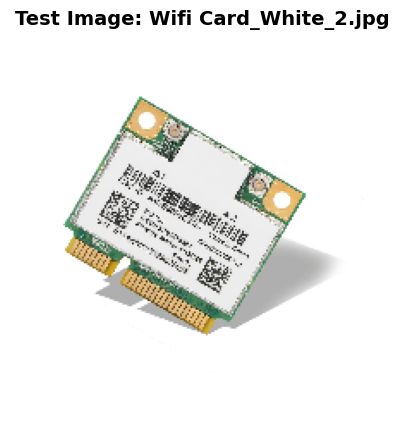

                    MODEL PREDICTION COMPARISON
Wifi Card_White_2.jpg
 [1] Baseline DenseNet-121  : WiFi Card    (65.91% confidence)
 [2] Optimized DenseNet-121 : WiFi Card    (55.77% confidence)
 [3] Baseline MobileNet-V2  : Battery      (87.27% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  33.63% | Opt Dense:  19.19% | MobileNet:   7.18%
 Battery      | Base Dense:   0.30% | Opt Dense:   5.29% | MobileNet:  87.27%
 RAM          | Base Dense:   0.15% | Opt Dense:  18.97% | MobileNet:   4.23%
 WiFi Card    | Base Dense:  65.91% | Opt Dense:  55.77% | MobileNet:   1.06%
 CPU Fan      | Base Dense:   0.01% | Opt Dense:   0.78% | MobileNet:   0.25%



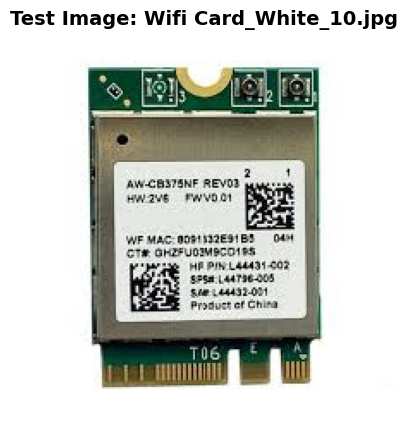

                    MODEL PREDICTION COMPARISON
Wifi Card_White_10.jpg
 [1] Baseline DenseNet-121  : RAM          (76.71% confidence)
 [2] Optimized DenseNet-121 : RAM          (75.40% confidence)
 [3] Baseline MobileNet-V2  : RAM          (96.03% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   3.97% | Opt Dense:   5.12% | MobileNet:   0.10%
 Battery      | Base Dense:  14.37% | Opt Dense:   9.54% | MobileNet:   2.82%
 RAM          | Base Dense:  76.71% | Opt Dense:  75.40% | MobileNet:  96.03%
 WiFi Card    | Base Dense:   4.88% | Opt Dense:   9.51% | MobileNet:   0.11%
 CPU Fan      | Base Dense:   0.08% | Opt Dense:   0.44% | MobileNet:   0.94%



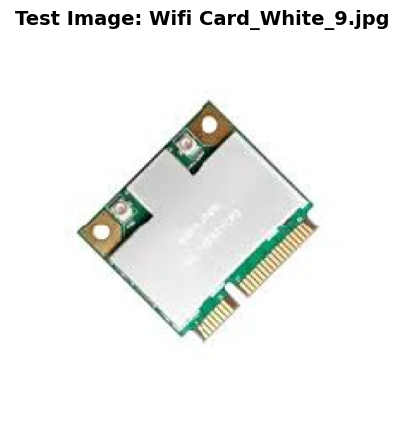

                    MODEL PREDICTION COMPARISON
Wifi Card_White_9.jpg
 [1] Baseline DenseNet-121  : Battery      (45.67% confidence)
 [2] Optimized DenseNet-121 : RAM          (54.85% confidence)
 [3] Baseline MobileNet-V2  : Battery      (89.87% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   9.78% | Opt Dense:   9.60% | MobileNet:   3.53%
 Battery      | Base Dense:  45.67% | Opt Dense:  24.38% | MobileNet:  89.87%
 RAM          | Base Dense:  38.03% | Opt Dense:  54.85% | MobileNet:   6.32%
 WiFi Card    | Base Dense:   6.20% | Opt Dense:   7.08% | MobileNet:   0.10%
 CPU Fan      | Base Dense:   0.31% | Opt Dense:   4.09% | MobileNet:   0.18%



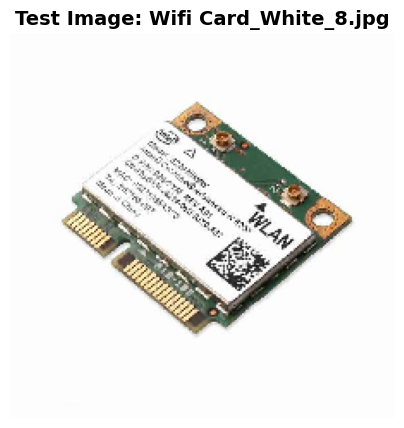

                    MODEL PREDICTION COMPARISON
Wifi Card_White_8.jpg
 [1] Baseline DenseNet-121  : Motherboard  (73.72% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (40.13% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (79.16% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  73.72% | Opt Dense:  40.13% | MobileNet:  79.16%
 Battery      | Base Dense:   0.18% | Opt Dense:   4.41% | MobileNet:  15.64%
 RAM          | Base Dense:   0.68% | Opt Dense:  18.79% | MobileNet:   0.94%
 WiFi Card    | Base Dense:  25.41% | Opt Dense:  35.93% | MobileNet:   4.16%
 CPU Fan      | Base Dense:   0.01% | Opt Dense:   0.74% | MobileNet:   0.10%



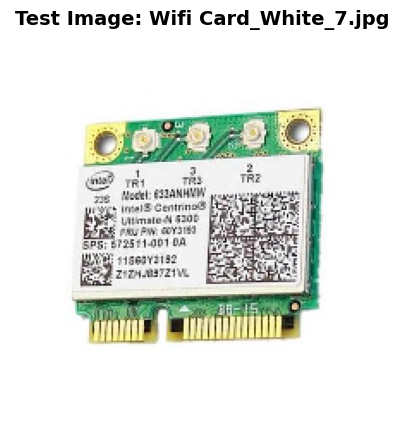

                    MODEL PREDICTION COMPARISON
Wifi Card_White_7.jpg
 [1] Baseline DenseNet-121  : Motherboard  (91.36% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (46.38% confidence)
 [3] Baseline MobileNet-V2  : RAM          (97.93% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  91.36% | Opt Dense:  46.38% | MobileNet:   1.06%
 Battery      | Base Dense:   1.71% | Opt Dense:   7.77% | MobileNet:   0.10%
 RAM          | Base Dense:   4.95% | Opt Dense:  32.42% | MobileNet:  97.93%
 WiFi Card    | Base Dense:   1.97% | Opt Dense:  12.60% | MobileNet:   0.85%
 CPU Fan      | Base Dense:   0.01% | Opt Dense:   0.83% | MobileNet:   0.06%



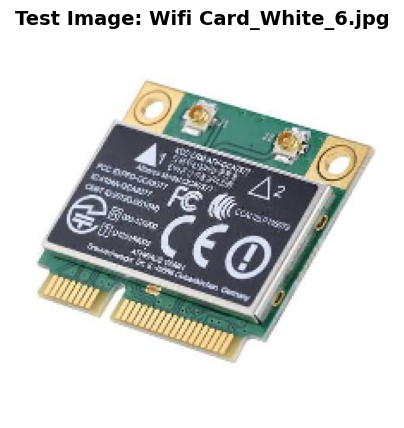

                    MODEL PREDICTION COMPARISON
Wifi Card_White_6.jpg
 [1] Baseline DenseNet-121  : RAM          (82.54% confidence)
 [2] Optimized DenseNet-121 : RAM          (75.57% confidence)
 [3] Baseline MobileNet-V2  : RAM          (84.69% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.07% | Opt Dense:   4.38% | MobileNet:   0.29%
 Battery      | Base Dense:  17.38% | Opt Dense:  13.67% | MobileNet:  14.65%
 RAM          | Base Dense:  82.54% | Opt Dense:  75.57% | MobileNet:  84.69%
 WiFi Card    | Base Dense:   0.01% | Opt Dense:   3.37% | MobileNet:   0.05%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   3.01% | MobileNet:   0.32%



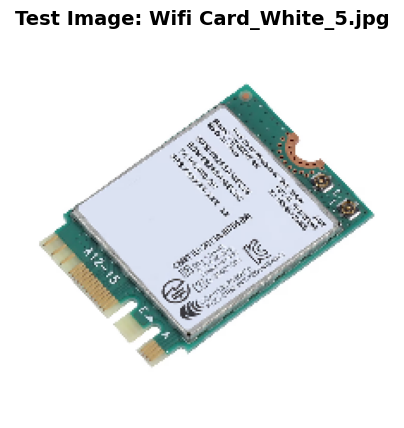

                    MODEL PREDICTION COMPARISON
Wifi Card_White_5.jpg
 [1] Baseline DenseNet-121  : RAM          (97.71% confidence)
 [2] Optimized DenseNet-121 : RAM          (84.34% confidence)
 [3] Baseline MobileNet-V2  : Battery      (52.37% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.29% | Opt Dense:   1.28% | MobileNet:   0.18%
 Battery      | Base Dense:   1.75% | Opt Dense:   3.47% | MobileNet:  52.37%
 RAM          | Base Dense:  97.71% | Opt Dense:  84.34% | MobileNet:  47.39%
 WiFi Card    | Base Dense:   0.26% | Opt Dense:  10.78% | MobileNet:   0.01%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.12% | MobileNet:   0.04%



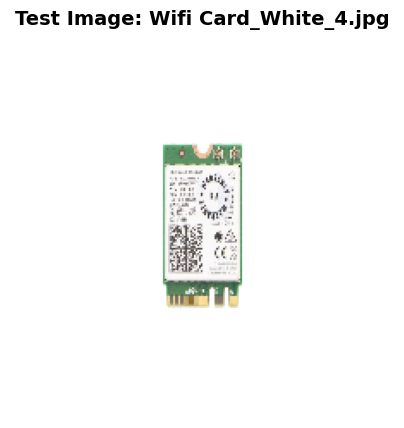

                    MODEL PREDICTION COMPARISON
Wifi Card_White_4.jpg
 [1] Baseline DenseNet-121  : WiFi Card    (96.43% confidence)
 [2] Optimized DenseNet-121 : WiFi Card    (78.53% confidence)
 [3] Baseline MobileNet-V2  : WiFi Card    (97.56% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   2.04% | Opt Dense:   4.54% | MobileNet:   0.32%
 Battery      | Base Dense:   0.10% | Opt Dense:   2.49% | MobileNet:   0.06%
 RAM          | Base Dense:   1.42% | Opt Dense:  14.24% | MobileNet:   2.06%
 WiFi Card    | Base Dense:  96.43% | Opt Dense:  78.53% | MobileNet:  97.56%
 CPU Fan      | Base Dense:   0.02% | Opt Dense:   0.20% | MobileNet:   0.01%



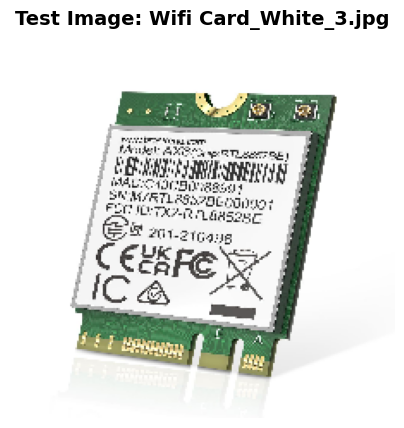

                    MODEL PREDICTION COMPARISON
Wifi Card_White_3.jpg
 [1] Baseline DenseNet-121  : Battery      (75.73% confidence)
 [2] Optimized DenseNet-121 : RAM          (49.17% confidence)
 [3] Baseline MobileNet-V2  : RAM          (65.61% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  10.27% | Opt Dense:  28.79% | MobileNet:  26.91%
 Battery      | Base Dense:  75.73% | Opt Dense:  15.32% | MobileNet:   5.29%
 RAM          | Base Dense:  13.19% | Opt Dense:  49.17% | MobileNet:  65.61%
 WiFi Card    | Base Dense:   0.77% | Opt Dense:   4.67% | MobileNet:   2.16%
 CPU Fan      | Base Dense:   0.03% | Opt Dense:   2.05% | MobileNet:   0.04%



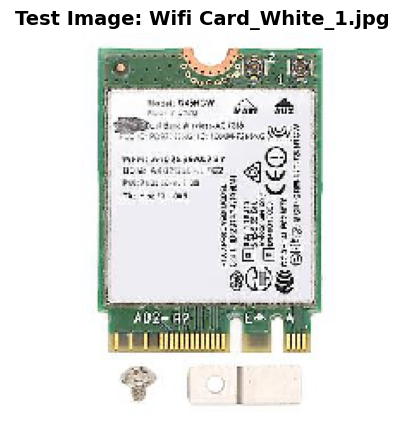

                    MODEL PREDICTION COMPARISON
Wifi Card_White_1.jpg
 [1] Baseline DenseNet-121  : Motherboard  (89.10% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (59.14% confidence)
 [3] Baseline MobileNet-V2  : RAM          (58.78% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  89.10% | Opt Dense:  59.14% | MobileNet:   6.02%
 Battery      | Base Dense:   1.19% | Opt Dense:   5.68% | MobileNet:   1.93%
 RAM          | Base Dense:   1.78% | Opt Dense:  21.52% | MobileNet:  58.78%
 WiFi Card    | Base Dense:   7.92% | Opt Dense:  12.97% | MobileNet:  28.48%
 CPU Fan      | Base Dense:   0.01% | Opt Dense:   0.70% | MobileNet:   4.80%



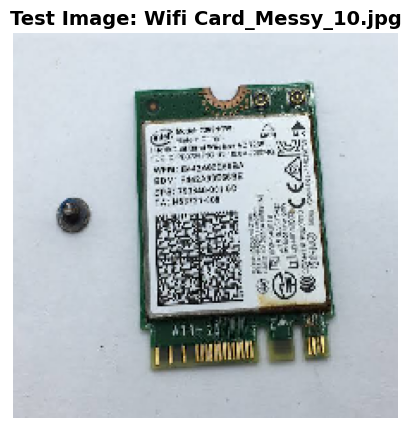

                    MODEL PREDICTION COMPARISON
Wifi Card_Messy_10.jpg
 [1] Baseline DenseNet-121  : WiFi Card    (99.16% confidence)
 [2] Optimized DenseNet-121 : WiFi Card    (92.98% confidence)
 [3] Baseline MobileNet-V2  : WiFi Card    (99.54% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.14% | Opt Dense:   3.47% | MobileNet:   0.01%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.07% | MobileNet:   0.00%
 RAM          | Base Dense:   0.69% | Opt Dense:   3.33% | MobileNet:   0.43%
 WiFi Card    | Base Dense:  99.16% | Opt Dense:  92.98% | MobileNet:  99.54%
 CPU Fan      | Base Dense:   0.01% | Opt Dense:   0.14% | MobileNet:   0.03%



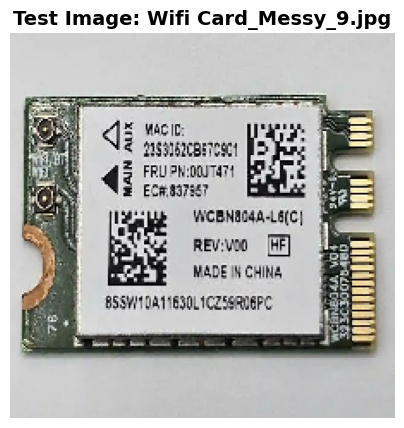

                    MODEL PREDICTION COMPARISON
Wifi Card_Messy_9.jpg
 [1] Baseline DenseNet-121  : RAM          (97.96% confidence)
 [2] Optimized DenseNet-121 : RAM          (63.44% confidence)
 [3] Baseline MobileNet-V2  : WiFi Card    (59.97% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.22% | Opt Dense:   0.90% | MobileNet:  19.75%
 Battery      | Base Dense:   0.01% | Opt Dense:   0.95% | MobileNet:   0.19%
 RAM          | Base Dense:  97.96% | Opt Dense:  63.44% | MobileNet:   2.37%
 WiFi Card    | Base Dense:   1.81% | Opt Dense:  34.70% | MobileNet:  59.97%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:  17.71%



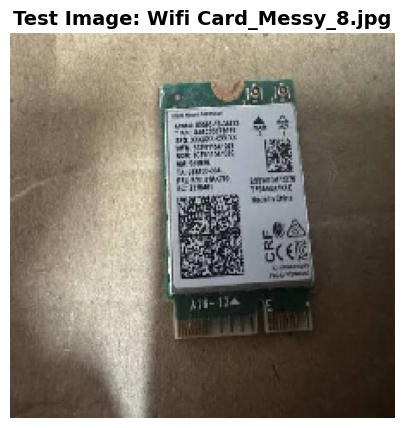

                    MODEL PREDICTION COMPARISON
Wifi Card_Messy_8.jpg
 [1] Baseline DenseNet-121  : WiFi Card    (98.12% confidence)
 [2] Optimized DenseNet-121 : WiFi Card    (91.91% confidence)
 [3] Baseline MobileNet-V2  : WiFi Card    (98.04% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.01% | Opt Dense:   0.11% | MobileNet:   0.04%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.08% | MobileNet:   0.89%
 RAM          | Base Dense:   1.87% | Opt Dense:   7.90% | MobileNet:   0.98%
 WiFi Card    | Base Dense:  98.12% | Opt Dense:  91.91% | MobileNet:  98.04%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.06%



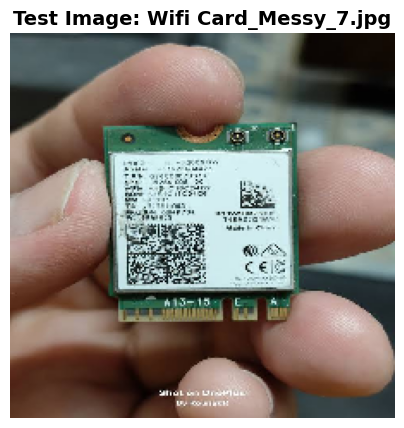

                    MODEL PREDICTION COMPARISON
Wifi Card_Messy_7.jpg
 [1] Baseline DenseNet-121  : RAM          (80.80% confidence)
 [2] Optimized DenseNet-121 : WiFi Card    (44.68% confidence)
 [3] Baseline MobileNet-V2  : WiFi Card    (87.13% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   1.52% | Opt Dense:   6.68% | MobileNet:   1.41%
 Battery      | Base Dense:   8.94% | Opt Dense:   9.28% | MobileNet:   3.30%
 RAM          | Base Dense:  80.80% | Opt Dense:  39.28% | MobileNet:   2.73%
 WiFi Card    | Base Dense:   8.72% | Opt Dense:  44.68% | MobileNet:  87.13%
 CPU Fan      | Base Dense:   0.01% | Opt Dense:   0.09% | MobileNet:   5.44%



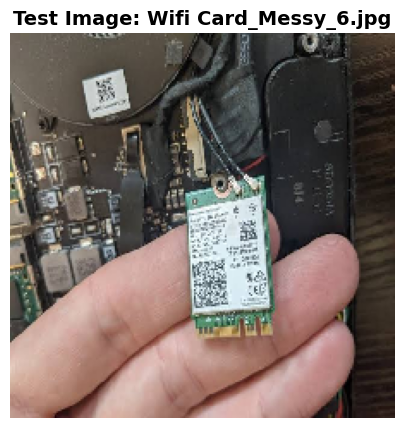

                    MODEL PREDICTION COMPARISON
Wifi Card_Messy_6.jpg
 [1] Baseline DenseNet-121  : Motherboard  (94.69% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (92.62% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (91.18% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  94.69% | Opt Dense:  92.62% | MobileNet:  91.18%
 Battery      | Base Dense:   0.09% | Opt Dense:   3.01% | MobileNet:   2.82%
 RAM          | Base Dense:   0.22% | Opt Dense:   2.74% | MobileNet:   0.90%
 WiFi Card    | Base Dense:   4.99% | Opt Dense:   1.37% | MobileNet:   5.00%
 CPU Fan      | Base Dense:   0.01% | Opt Dense:   0.27% | MobileNet:   0.10%



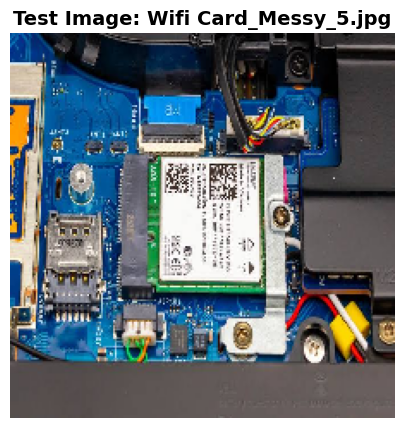

                    MODEL PREDICTION COMPARISON
Wifi Card_Messy_5.jpg
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (99.44% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense:  99.44% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.16% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.24% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.16% | MobileNet:   0.00%



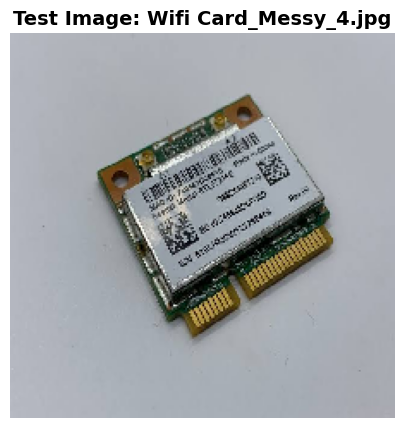

                    MODEL PREDICTION COMPARISON
Wifi Card_Messy_4.jpg
 [1] Baseline DenseNet-121  : WiFi Card    (97.49% confidence)
 [2] Optimized DenseNet-121 : WiFi Card    (72.48% confidence)
 [3] Baseline MobileNet-V2  : WiFi Card    (99.17% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.47% | Opt Dense:   6.40% | MobileNet:   0.26%
 Battery      | Base Dense:   0.00% | Opt Dense:   1.21% | MobileNet:   0.08%
 RAM          | Base Dense:   2.04% | Opt Dense:  19.81% | MobileNet:   0.48%
 WiFi Card    | Base Dense:  97.49% | Opt Dense:  72.48% | MobileNet:  99.17%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.10% | MobileNet:   0.00%



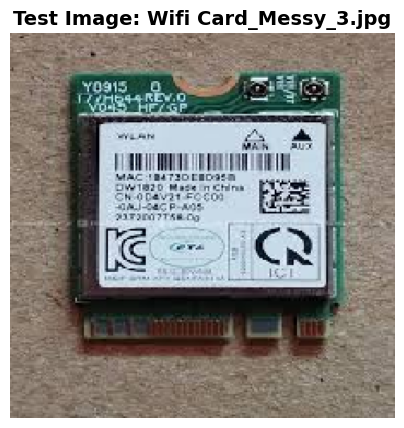

                    MODEL PREDICTION COMPARISON
Wifi Card_Messy_3.jpg
 [1] Baseline DenseNet-121  : WiFi Card    (89.66% confidence)
 [2] Optimized DenseNet-121 : WiFi Card    (64.87% confidence)
 [3] Baseline MobileNet-V2  : WiFi Card    (52.96% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.07% | Opt Dense:   2.16% | MobileNet:  13.51%
 Battery      | Base Dense:   0.02% | Opt Dense:   3.34% | MobileNet:   0.03%
 RAM          | Base Dense:  10.22% | Opt Dense:  29.03% | MobileNet:   4.09%
 WiFi Card    | Base Dense:  89.66% | Opt Dense:  64.87% | MobileNet:  52.96%
 CPU Fan      | Base Dense:   0.04% | Opt Dense:   0.61% | MobileNet:  29.41%



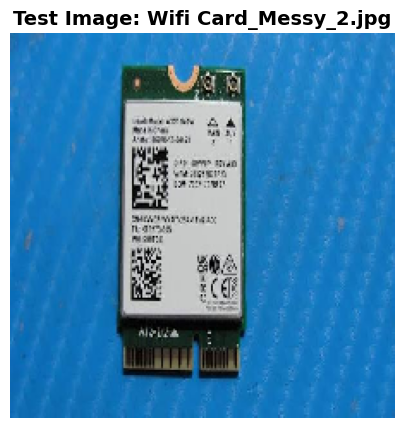

                    MODEL PREDICTION COMPARISON
Wifi Card_Messy_2.jpg
 [1] Baseline DenseNet-121  : RAM          (91.03% confidence)
 [2] Optimized DenseNet-121 : RAM          (62.45% confidence)
 [3] Baseline MobileNet-V2  : WiFi Card    (94.23% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.15% | MobileNet:   0.05%
 Battery      | Base Dense:   0.06% | Opt Dense:   5.85% | MobileNet:   0.10%
 RAM          | Base Dense:  91.03% | Opt Dense:  62.45% | MobileNet:   5.43%
 WiFi Card    | Base Dense:   8.91% | Opt Dense:  31.54% | MobileNet:  94.23%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.02% | MobileNet:   0.19%



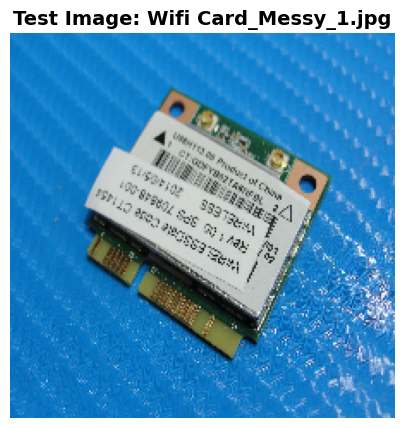

                    MODEL PREDICTION COMPARISON
Wifi Card_Messy_1.jpg
 [1] Baseline DenseNet-121  : RAM          (98.77% confidence)
 [2] Optimized DenseNet-121 : RAM          (75.71% confidence)
 [3] Baseline MobileNet-V2  : RAM          (89.24% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.24% | Opt Dense:   3.97% | MobileNet:   0.05%
 Battery      | Base Dense:   0.91% | Opt Dense:  18.02% | MobileNet:   0.02%
 RAM          | Base Dense:  98.77% | Opt Dense:  75.71% | MobileNet:  89.24%
 WiFi Card    | Base Dense:   0.08% | Opt Dense:   2.22% | MobileNet:  10.68%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.08% | MobileNet:   0.02%



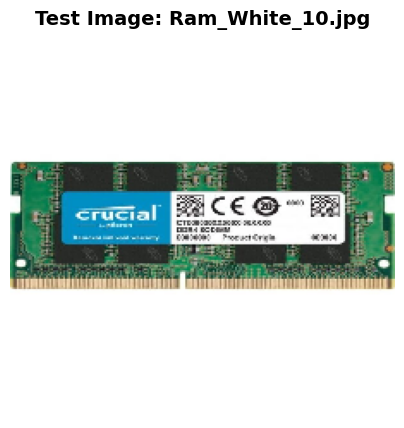

                    MODEL PREDICTION COMPARISON
Ram_White_10.jpg
 [1] Baseline DenseNet-121  : Motherboard  (96.31% confidence)
 [2] Optimized DenseNet-121 : RAM          (59.60% confidence)
 [3] Baseline MobileNet-V2  : RAM          (99.89% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  96.31% | Opt Dense:  35.31% | MobileNet:   0.09%
 Battery      | Base Dense:   0.09% | Opt Dense:   4.32% | MobileNet:   0.02%
 RAM          | Base Dense:   3.59% | Opt Dense:  59.60% | MobileNet:  99.89%
 WiFi Card    | Base Dense:   0.01% | Opt Dense:   0.67% | MobileNet:   0.01%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.10% | MobileNet:   0.00%



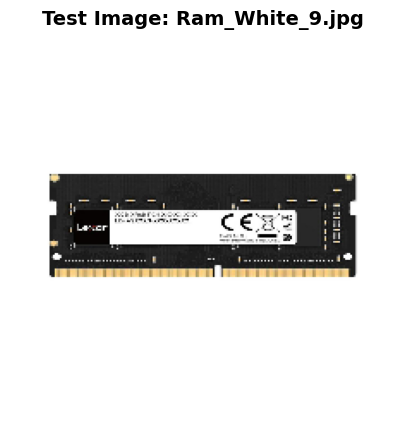

                    MODEL PREDICTION COMPARISON
Ram_White_9.jpg
 [1] Baseline DenseNet-121  : Motherboard  (58.63% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (33.99% confidence)
 [3] Baseline MobileNet-V2  : RAM          (99.97% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  58.63% | Opt Dense:  33.99% | MobileNet:   0.00%
 Battery      | Base Dense:  18.52% | Opt Dense:  30.90% | MobileNet:   0.02%
 RAM          | Base Dense:  22.43% | Opt Dense:  26.36% | MobileNet:  99.97%
 WiFi Card    | Base Dense:   0.01% | Opt Dense:   0.22% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.41% | Opt Dense:   8.52% | MobileNet:   0.00%



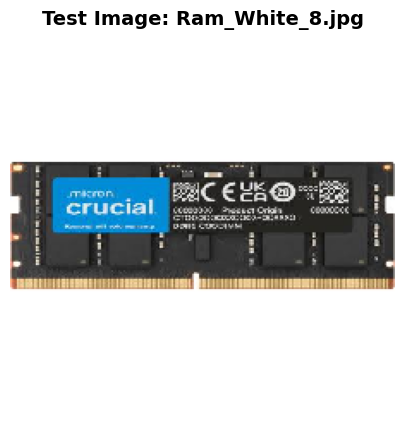

                    MODEL PREDICTION COMPARISON
Ram_White_8.jpg
 [1] Baseline DenseNet-121  : RAM          (60.77% confidence)
 [2] Optimized DenseNet-121 : RAM          (82.96% confidence)
 [3] Baseline MobileNet-V2  : RAM          (89.49% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  37.08% | Opt Dense:   8.82% | MobileNet:   0.69%
 Battery      | Base Dense:   2.14% | Opt Dense:   7.65% | MobileNet:   9.80%
 RAM          | Base Dense:  60.77% | Opt Dense:  82.96% | MobileNet:  89.49%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.20% | MobileNet:   0.02%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.36% | MobileNet:   0.00%



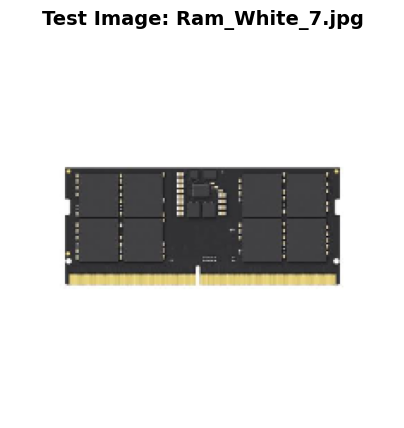

                    MODEL PREDICTION COMPARISON
Ram_White_7.jpg
 [1] Baseline DenseNet-121  : RAM          (62.95% confidence)
 [2] Optimized DenseNet-121 : Battery      (53.08% confidence)
 [3] Baseline MobileNet-V2  : RAM          (52.37% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   8.92% | Opt Dense:   8.53% | MobileNet:   0.01%
 Battery      | Base Dense:  28.09% | Opt Dense:  53.08% | MobileNet:  47.62%
 RAM          | Base Dense:  62.95% | Opt Dense:  37.41% | MobileNet:  52.37%
 WiFi Card    | Base Dense:   0.01% | Opt Dense:   0.22% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.03% | Opt Dense:   0.76% | MobileNet:   0.00%



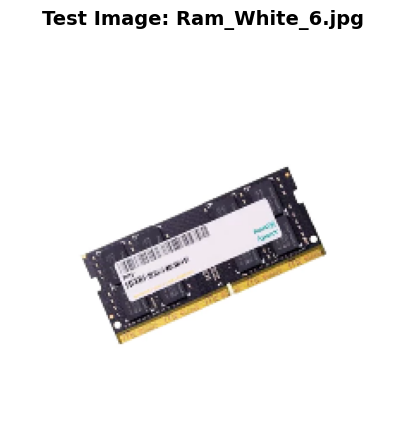

                    MODEL PREDICTION COMPARISON
Ram_White_6.jpg
 [1] Baseline DenseNet-121  : RAM          (87.31% confidence)
 [2] Optimized DenseNet-121 : RAM          (63.40% confidence)
 [3] Baseline MobileNet-V2  : RAM          (99.99% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   5.67% | Opt Dense:  13.74% | MobileNet:   0.00%
 Battery      | Base Dense:   7.02% | Opt Dense:  22.60% | MobileNet:   0.01%
 RAM          | Base Dense:  87.31% | Opt Dense:  63.40% | MobileNet:  99.99%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.13% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.14% | MobileNet:   0.00%



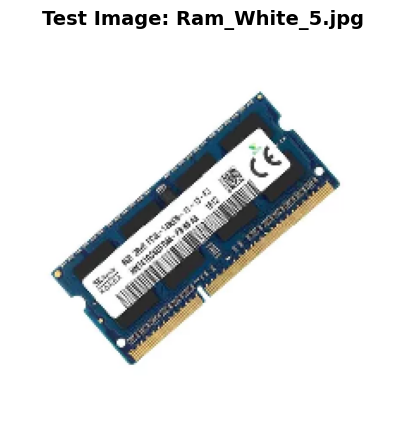

                    MODEL PREDICTION COMPARISON
Ram_White_5.jpg
 [1] Baseline DenseNet-121  : RAM          (68.42% confidence)
 [2] Optimized DenseNet-121 : RAM          (63.09% confidence)
 [3] Baseline MobileNet-V2  : RAM          (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.18% | Opt Dense:   2.26% | MobileNet:   0.00%
 Battery      | Base Dense:  31.40% | Opt Dense:  34.58% | MobileNet:   0.00%
 RAM          | Base Dense:  68.42% | Opt Dense:  63.09% | MobileNet: 100.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.04% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.03% | MobileNet:   0.00%



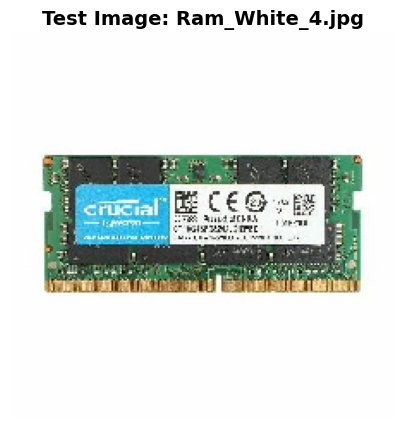

                    MODEL PREDICTION COMPARISON
Ram_White_4.jpg
 [1] Baseline DenseNet-121  : RAM          (98.34% confidence)
 [2] Optimized DenseNet-121 : RAM          (80.20% confidence)
 [3] Baseline MobileNet-V2  : RAM          (99.75% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   1.64% | Opt Dense:  17.73% | MobileNet:   0.24%
 Battery      | Base Dense:   0.02% | Opt Dense:   1.04% | MobileNet:   0.00%
 RAM          | Base Dense:  98.34% | Opt Dense:  80.20% | MobileNet:  99.75%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.90% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.13% | MobileNet:   0.00%



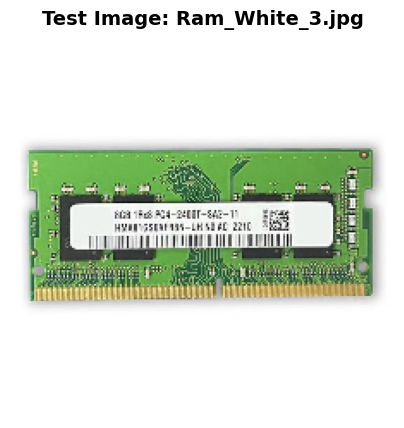

                    MODEL PREDICTION COMPARISON
Ram_White_3.jpg
 [1] Baseline DenseNet-121  : RAM          (99.95% confidence)
 [2] Optimized DenseNet-121 : RAM          (96.66% confidence)
 [3] Baseline MobileNet-V2  : RAM          (99.78% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.04% | Opt Dense:   1.46% | MobileNet:   0.21%
 Battery      | Base Dense:   0.01% | Opt Dense:   1.10% | MobileNet:   0.01%
 RAM          | Base Dense:  99.95% | Opt Dense:  96.66% | MobileNet:  99.78%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.68% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.10% | MobileNet:   0.00%



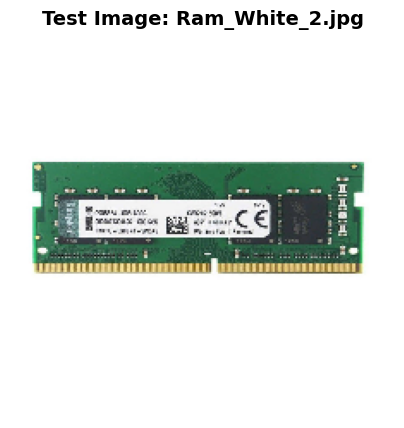

                    MODEL PREDICTION COMPARISON
Ram_White_2.jpg
 [1] Baseline DenseNet-121  : RAM          (93.81% confidence)
 [2] Optimized DenseNet-121 : RAM          (89.68% confidence)
 [3] Baseline MobileNet-V2  : RAM          (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   6.04% | Opt Dense:   6.81% | MobileNet:   0.00%
 Battery      | Base Dense:   0.10% | Opt Dense:   1.37% | MobileNet:   0.00%
 RAM          | Base Dense:  93.81% | Opt Dense:  89.68% | MobileNet: 100.00%
 WiFi Card    | Base Dense:   0.04% | Opt Dense:   1.67% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.01% | Opt Dense:   0.46% | MobileNet:   0.00%



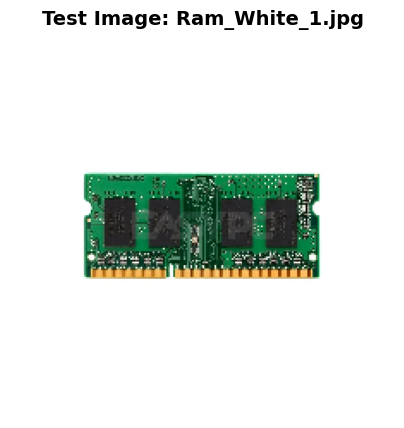

                    MODEL PREDICTION COMPARISON
Ram_White_1.jpg
 [1] Baseline DenseNet-121  : RAM          (53.62% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (61.19% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (99.92% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  45.77% | Opt Dense:  61.19% | MobileNet:  99.92%
 Battery      | Base Dense:   0.61% | Opt Dense:   2.08% | MobileNet:   0.01%
 RAM          | Base Dense:  53.62% | Opt Dense:  36.53% | MobileNet:   0.07%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.07% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.13% | MobileNet:   0.00%



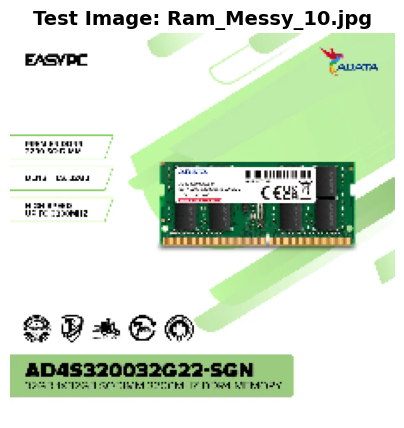

                    MODEL PREDICTION COMPARISON
Ram_Messy_10.jpg
 [1] Baseline DenseNet-121  : RAM          (81.12% confidence)
 [2] Optimized DenseNet-121 : RAM          (86.90% confidence)
 [3] Baseline MobileNet-V2  : RAM          (99.98% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   5.88% | Opt Dense:   5.03% | MobileNet:   0.00%
 Battery      | Base Dense:  12.90% | Opt Dense:   7.58% | MobileNet:   0.02%
 RAM          | Base Dense:  81.12% | Opt Dense:  86.90% | MobileNet:  99.98%
 WiFi Card    | Base Dense:   0.09% | Opt Dense:   0.12% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.01% | Opt Dense:   0.37% | MobileNet:   0.00%



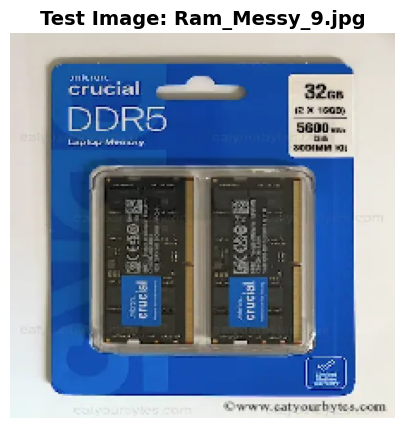

                    MODEL PREDICTION COMPARISON
Ram_Messy_9.jpg
 [1] Baseline DenseNet-121  : Battery      (93.59% confidence)
 [2] Optimized DenseNet-121 : Battery      (84.44% confidence)
 [3] Baseline MobileNet-V2  : RAM          (95.82% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.13% | Opt Dense:   0.17% | MobileNet:   0.16%
 Battery      | Base Dense:  93.59% | Opt Dense:  84.44% | MobileNet:   4.00%
 RAM          | Base Dense:   5.96% | Opt Dense:  14.37% | MobileNet:  95.82%
 WiFi Card    | Base Dense:   0.32% | Opt Dense:   1.01% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.02% | MobileNet:   0.01%



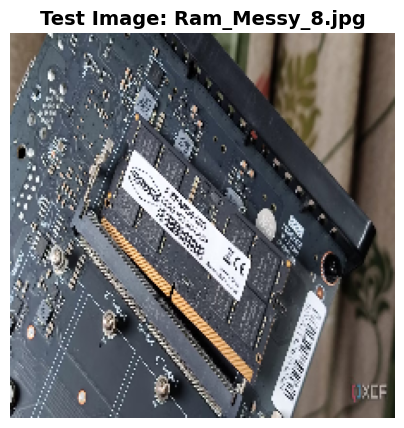

                    MODEL PREDICTION COMPARISON
Ram_Messy_8.jpg
 [1] Baseline DenseNet-121  : Motherboard  (99.03% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (97.13% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (99.99% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  99.03% | Opt Dense:  97.13% | MobileNet:  99.99%
 Battery      | Base Dense:   0.97% | Opt Dense:   2.40% | MobileNet:   0.01%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.32% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.15% | MobileNet:   0.00%



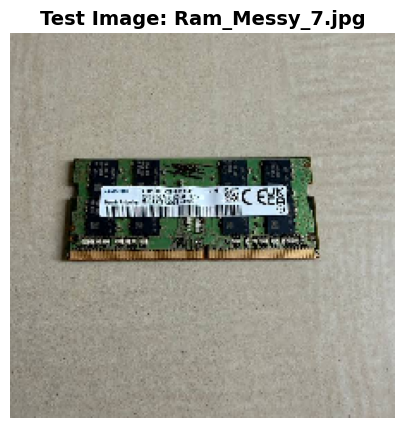

                    MODEL PREDICTION COMPARISON
Ram_Messy_7.jpg
 [1] Baseline DenseNet-121  : RAM          (98.77% confidence)
 [2] Optimized DenseNet-121 : RAM          (88.39% confidence)
 [3] Baseline MobileNet-V2  : RAM          (99.85% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.13%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%
 RAM          | Base Dense:  98.77% | Opt Dense:  88.39% | MobileNet:  99.85%
 WiFi Card    | Base Dense:   1.23% | Opt Dense:  11.58% | MobileNet:   0.02%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



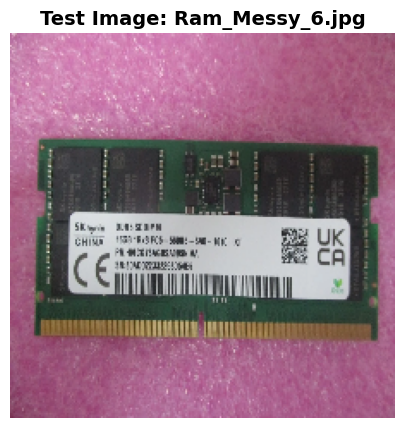

                    MODEL PREDICTION COMPARISON
Ram_Messy_6.jpg
 [1] Baseline DenseNet-121  : RAM          (99.96% confidence)
 [2] Optimized DenseNet-121 : RAM          (97.94% confidence)
 [3] Baseline MobileNet-V2  : RAM          (99.88% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.17% | MobileNet:   0.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.58% | MobileNet:   0.12%
 RAM          | Base Dense:  99.96% | Opt Dense:  97.94% | MobileNet:  99.88%
 WiFi Card    | Base Dense:   0.04% | Opt Dense:   1.29% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.02% | MobileNet:   0.00%



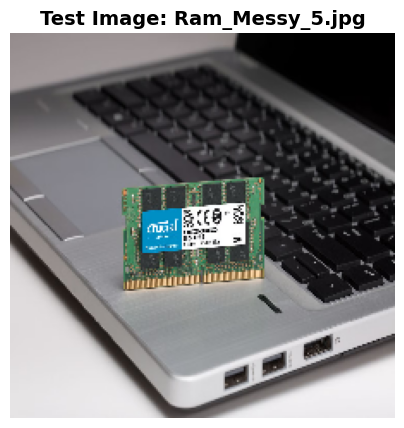

                    MODEL PREDICTION COMPARISON
Ram_Messy_5.jpg
 [1] Baseline DenseNet-121  : Battery      (99.79% confidence)
 [2] Optimized DenseNet-121 : Battery      (89.08% confidence)
 [3] Baseline MobileNet-V2  : Battery      (99.98% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   1.44% | MobileNet:   0.00%
 Battery      | Base Dense:  99.79% | Opt Dense:  89.08% | MobileNet:  99.98%
 RAM          | Base Dense:   0.21% | Opt Dense:   9.06% | MobileNet:   0.02%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.41% | MobileNet:   0.00%



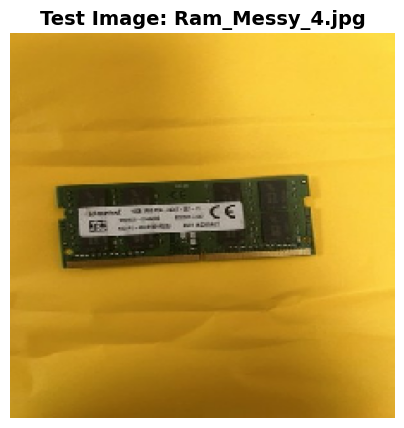

                    MODEL PREDICTION COMPARISON
Ram_Messy_4.jpg
 [1] Baseline DenseNet-121  : RAM          (99.73% confidence)
 [2] Optimized DenseNet-121 : RAM          (93.16% confidence)
 [3] Baseline MobileNet-V2  : RAM          (99.87% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.07% | MobileNet:   0.00%
 Battery      | Base Dense:   0.27% | Opt Dense:   6.67% | MobileNet:   0.13%
 RAM          | Base Dense:  99.73% | Opt Dense:  93.16% | MobileNet:  99.87%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.10% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



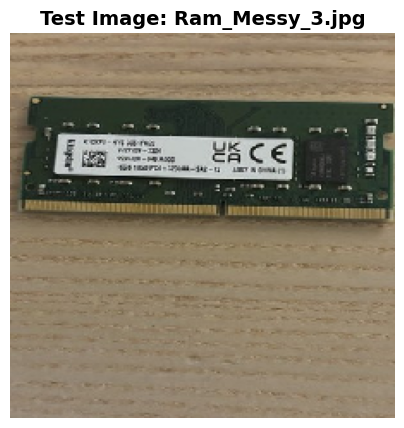

                    MODEL PREDICTION COMPARISON
Ram_Messy_3.jpg
 [1] Baseline DenseNet-121  : RAM          (100.00% confidence)
 [2] Optimized DenseNet-121 : RAM          (99.07% confidence)
 [3] Baseline MobileNet-V2  : RAM          (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.24% | MobileNet:   0.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.36% | MobileNet:   0.00%
 RAM          | Base Dense: 100.00% | Opt Dense:  99.07% | MobileNet: 100.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.31% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.02% | MobileNet:   0.00%



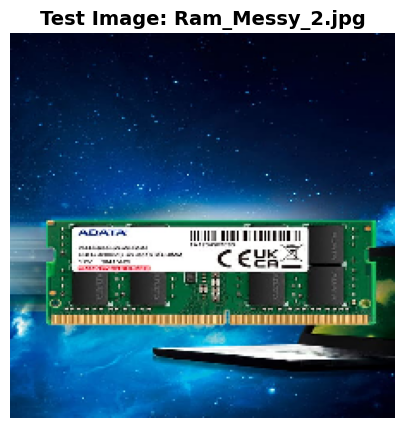

                    MODEL PREDICTION COMPARISON
Ram_Messy_2.jpg
 [1] Baseline DenseNet-121  : RAM          (69.37% confidence)
 [2] Optimized DenseNet-121 : RAM          (67.54% confidence)
 [3] Baseline MobileNet-V2  : RAM          (95.99% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.64% | Opt Dense:   3.66% | MobileNet:   0.04%
 Battery      | Base Dense:  29.99% | Opt Dense:  28.78% | MobileNet:   3.64%
 RAM          | Base Dense:  69.37% | Opt Dense:  67.54% | MobileNet:  95.99%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.33%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.01%



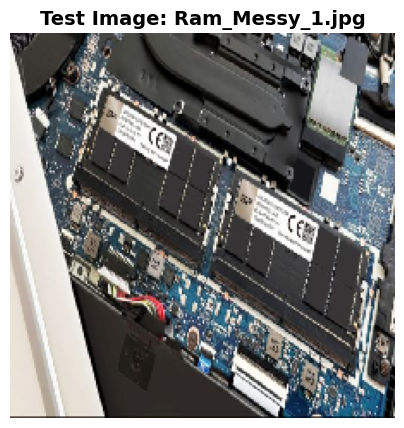

                    MODEL PREDICTION COMPARISON
Ram_Messy_1.jpg
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (99.97% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense:  99.97% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.03% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



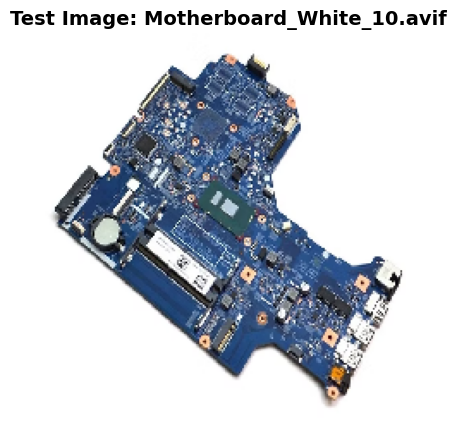

                    MODEL PREDICTION COMPARISON
Motherboard_White_10.avif
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (100.00% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense: 100.00% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



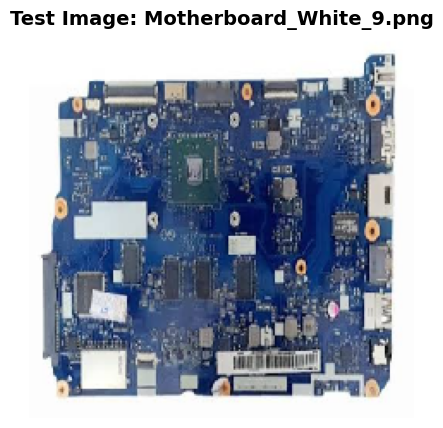

                    MODEL PREDICTION COMPARISON
Motherboard_White_9.png
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (99.80% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense:  99.80% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.10% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.10% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



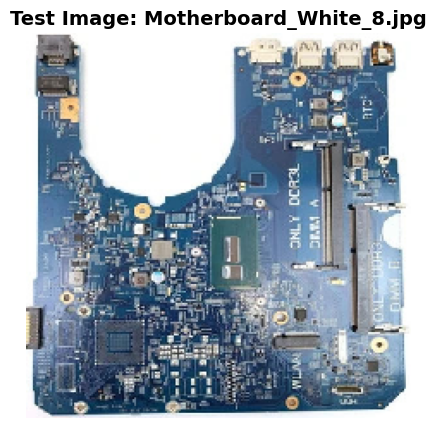

                    MODEL PREDICTION COMPARISON
Motherboard_White_8.jpg
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (99.99% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense:  99.99% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



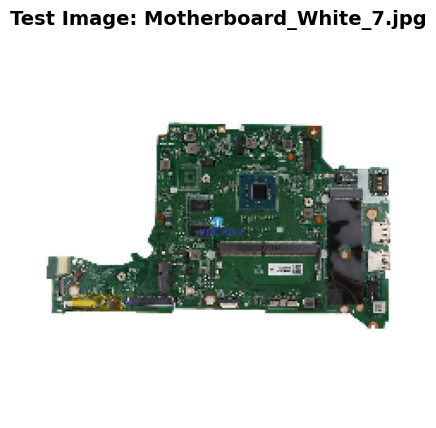

                    MODEL PREDICTION COMPARISON
Motherboard_White_7.jpg
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (100.00% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense: 100.00% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



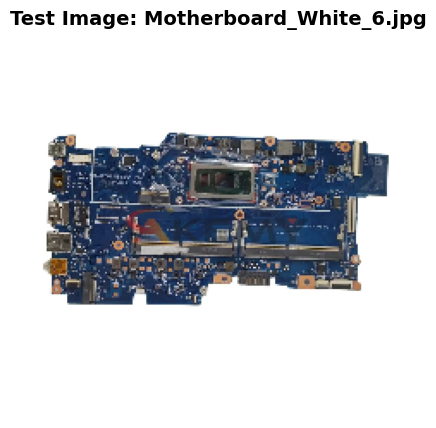

                    MODEL PREDICTION COMPARISON
Motherboard_White_6.jpg
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (99.99% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense:  99.99% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



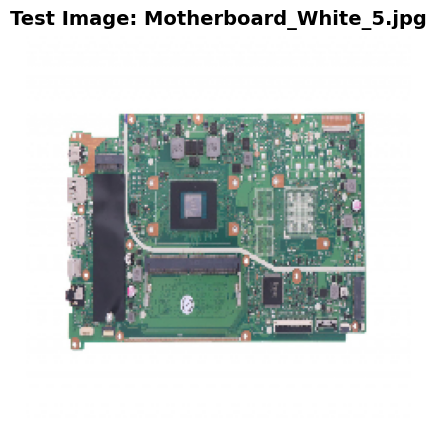

                    MODEL PREDICTION COMPARISON
Motherboard_White_5.jpg
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (99.89% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense:  99.89% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.02% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.07% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%



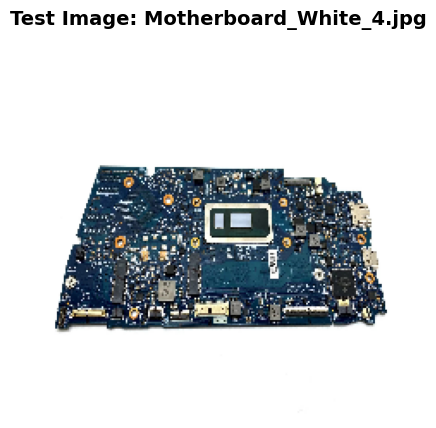

                    MODEL PREDICTION COMPARISON
Motherboard_White_4.jpg
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (99.98% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense:  99.98% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.02% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



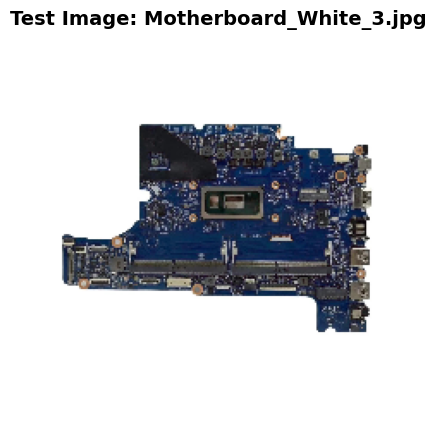

                    MODEL PREDICTION COMPARISON
Motherboard_White_3.jpg
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (100.00% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense: 100.00% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



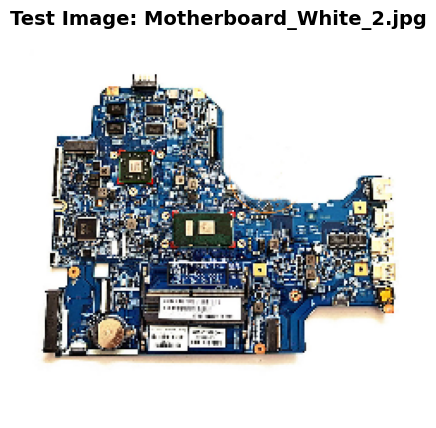

                    MODEL PREDICTION COMPARISON
Motherboard_White_2.jpg
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (99.98% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense:  99.98% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.02% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



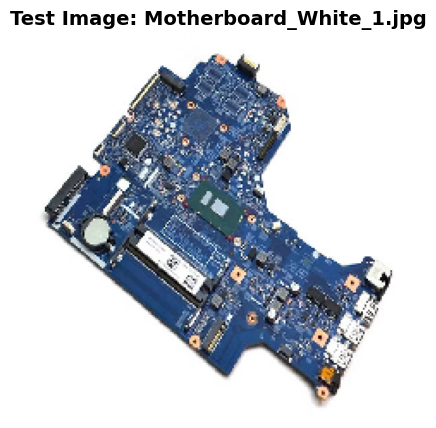

                    MODEL PREDICTION COMPARISON
Motherboard_White_1.jpg
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (100.00% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense: 100.00% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



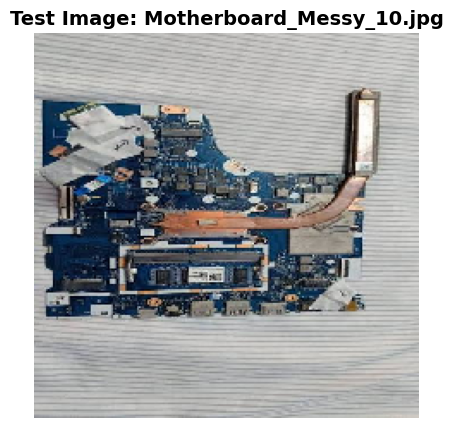

                    MODEL PREDICTION COMPARISON
Motherboard_Messy_10.jpg
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (99.99% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense:  99.99% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%



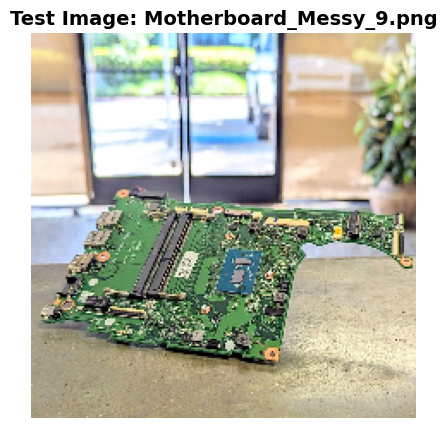

                    MODEL PREDICTION COMPARISON
Motherboard_Messy_9.png
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (100.00% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense: 100.00% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



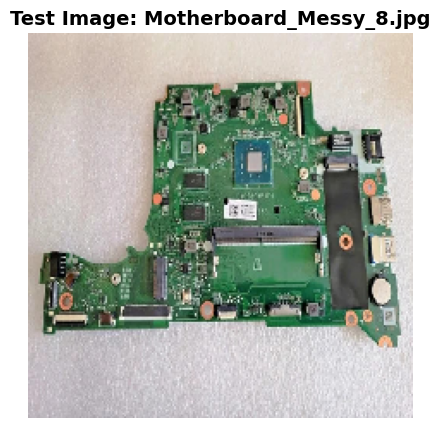

                    MODEL PREDICTION COMPARISON
Motherboard_Messy_8.jpg
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (100.00% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense: 100.00% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



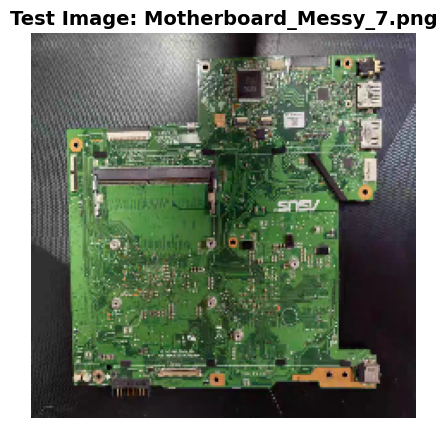

                    MODEL PREDICTION COMPARISON
Motherboard_Messy_7.png
 [1] Baseline DenseNet-121  : Motherboard  (99.97% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (99.92% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  99.97% | Opt Dense:  99.92% | MobileNet: 100.00%
 Battery      | Base Dense:   0.03% | Opt Dense:   0.08% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



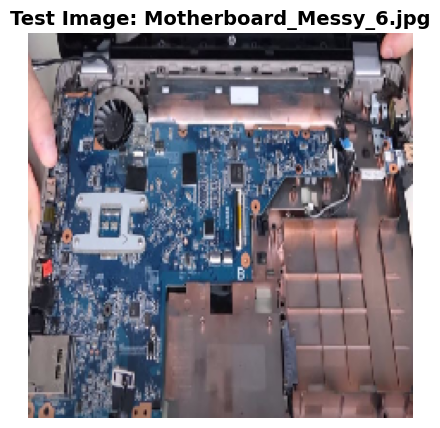

                    MODEL PREDICTION COMPARISON
Motherboard_Messy_6.jpg
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (99.53% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense:  99.53% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.46% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



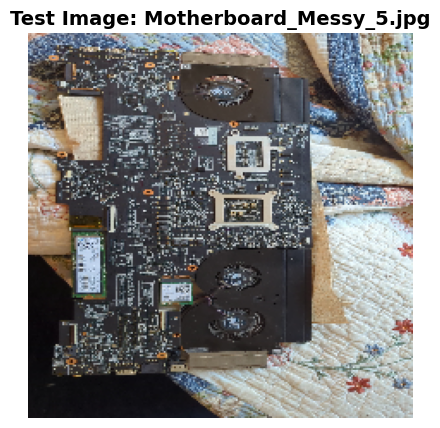

                    MODEL PREDICTION COMPARISON
Motherboard_Messy_5.jpg
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (99.73% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (99.86% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense:  99.73% | MobileNet:  99.86%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.08% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.07% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.11%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.11% | MobileNet:   0.02%



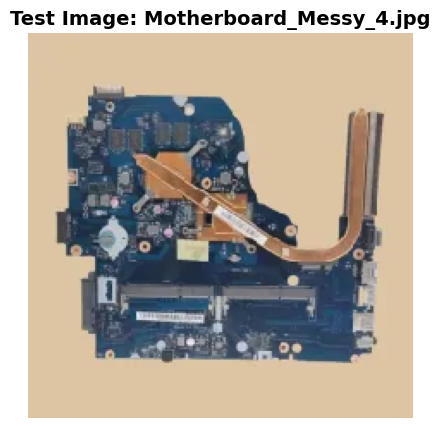

                    MODEL PREDICTION COMPARISON
Motherboard_Messy_4.jpg
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (99.99% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense:  99.99% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



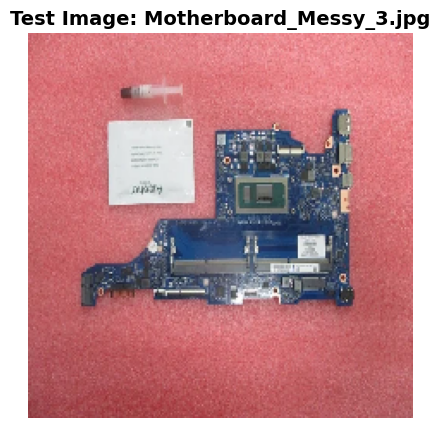

                    MODEL PREDICTION COMPARISON
Motherboard_Messy_3.jpg
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (99.98% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense:  99.98% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



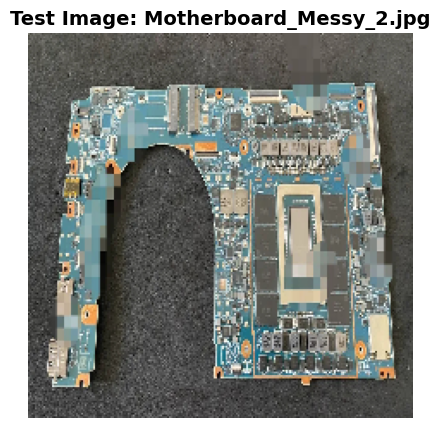

                    MODEL PREDICTION COMPARISON
Motherboard_Messy_2.jpg
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (99.99% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense:  99.99% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



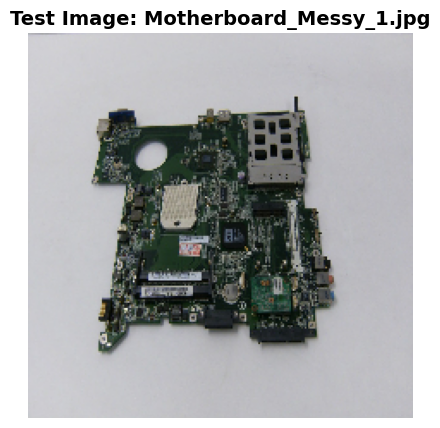

                    MODEL PREDICTION COMPARISON
Motherboard_Messy_1.jpg
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (100.00% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense: 100.00% | MobileNet: 100.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



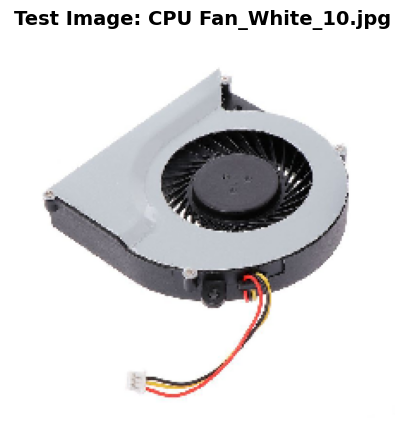

                    MODEL PREDICTION COMPARISON
CPU Fan_White_10.jpg
 [1] Baseline DenseNet-121  : CPU Fan      (100.00% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (100.00% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (99.96% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.03%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.01%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense: 100.00% | Opt Dense: 100.00% | MobileNet:  99.96%



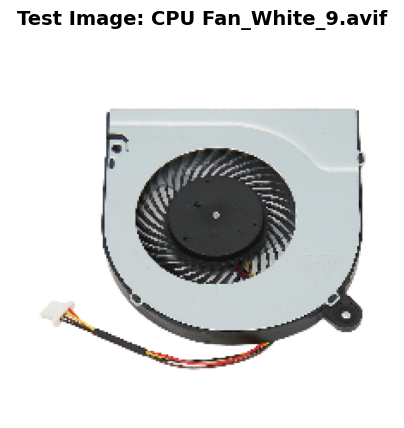

                    MODEL PREDICTION COMPARISON
CPU Fan_White_9.avif
 [1] Baseline DenseNet-121  : CPU Fan      (100.00% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (99.98% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (97.94% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   1.66%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.39%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense: 100.00% | Opt Dense:  99.98% | MobileNet:  97.94%



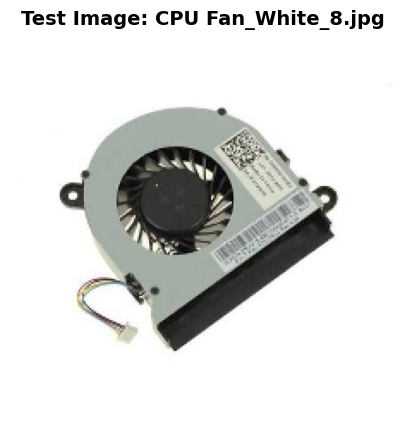

                    MODEL PREDICTION COMPARISON
CPU Fan_White_8.jpg
 [1] Baseline DenseNet-121  : CPU Fan      (100.00% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (99.99% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (100.00% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense: 100.00% | Opt Dense:  99.99% | MobileNet: 100.00%



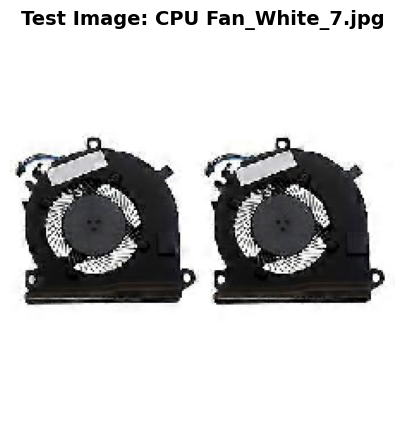

                    MODEL PREDICTION COMPARISON
CPU Fan_White_7.jpg
 [1] Baseline DenseNet-121  : CPU Fan      (100.00% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (99.99% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (99.99% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.01%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense: 100.00% | Opt Dense:  99.99% | MobileNet:  99.99%



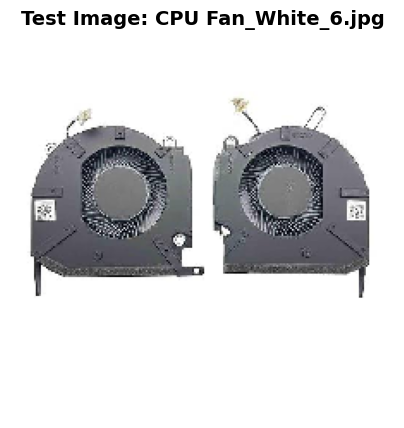

                    MODEL PREDICTION COMPARISON
CPU Fan_White_6.jpg
 [1] Baseline DenseNet-121  : CPU Fan      (99.99% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (99.99% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (78.02% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.01% | Opt Dense:   0.01% | MobileNet:  21.97%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:  99.99% | Opt Dense:  99.99% | MobileNet:  78.02%



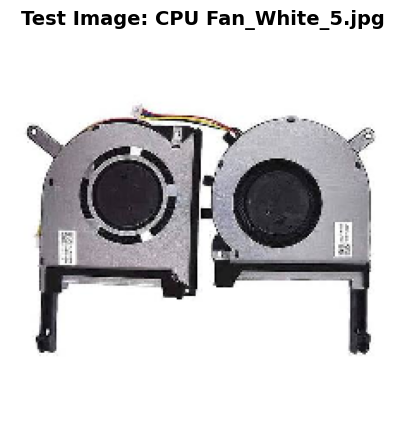

                    MODEL PREDICTION COMPARISON
CPU Fan_White_5.jpg
 [1] Baseline DenseNet-121  : CPU Fan      (100.00% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (99.97% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (98.99% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.02% | MobileNet:   0.99%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.01%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense: 100.00% | Opt Dense:  99.97% | MobileNet:  98.99%



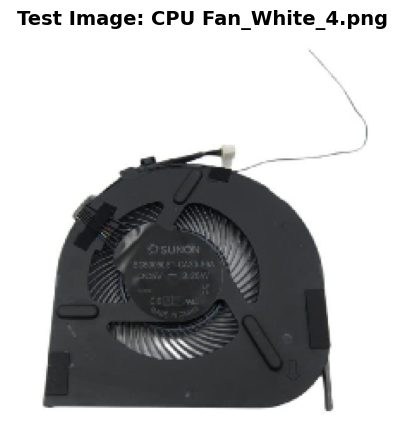

                    MODEL PREDICTION COMPARISON
CPU Fan_White_4.png
 [1] Baseline DenseNet-121  : CPU Fan      (98.81% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (99.99% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (99.97% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 Battery      | Base Dense:   1.19% | Opt Dense:   0.01% | MobileNet:   0.03%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:  98.81% | Opt Dense:  99.99% | MobileNet:  99.97%



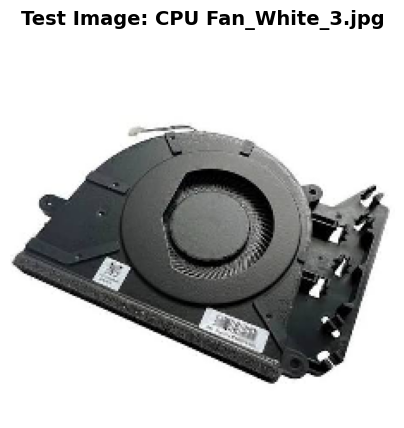

                    MODEL PREDICTION COMPARISON
CPU Fan_White_3.jpg
 [1] Baseline DenseNet-121  : Motherboard  (93.31% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (72.70% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (80.91% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  93.31% | Opt Dense:  26.46% | MobileNet:  18.70%
 Battery      | Base Dense:   0.17% | Opt Dense:   0.83% | MobileNet:   0.39%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   6.52% | Opt Dense:  72.70% | MobileNet:  80.91%



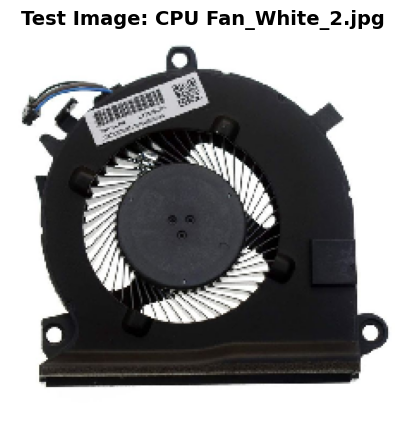

                    MODEL PREDICTION COMPARISON
CPU Fan_White_2.jpg
 [1] Baseline DenseNet-121  : CPU Fan      (99.96% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (99.84% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (99.39% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.02% | Opt Dense:   0.09% | MobileNet:   0.10%
 Battery      | Base Dense:   0.02% | Opt Dense:   0.07% | MobileNet:   0.49%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.01%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:  99.96% | Opt Dense:  99.84% | MobileNet:  99.39%



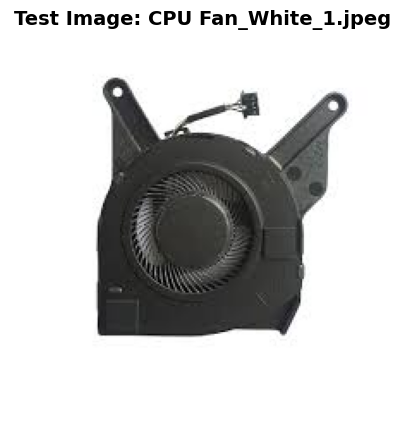

                    MODEL PREDICTION COMPARISON
CPU Fan_White_1.jpeg
 [1] Baseline DenseNet-121  : CPU Fan      (99.99% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (99.99% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (99.64% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.27%
 Battery      | Base Dense:   0.01% | Opt Dense:   0.01% | MobileNet:   0.09%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:  99.99% | Opt Dense:  99.99% | MobileNet:  99.64%



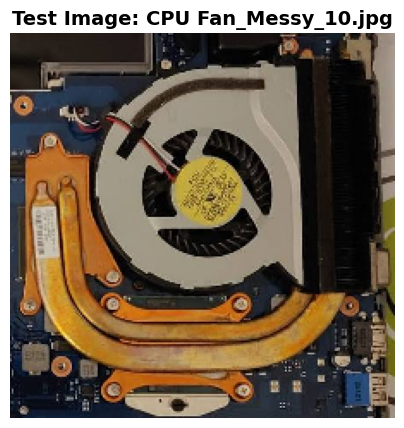

                    MODEL PREDICTION COMPARISON
CPU Fan_Messy_10.jpg
 [1] Baseline DenseNet-121  : Motherboard  (89.13% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (69.53% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (95.74% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  89.13% | Opt Dense:  69.53% | MobileNet:   4.25%
 Battery      | Base Dense:   0.01% | Opt Dense:   0.13% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:  10.86% | Opt Dense:  30.33% | MobileNet:  95.74%



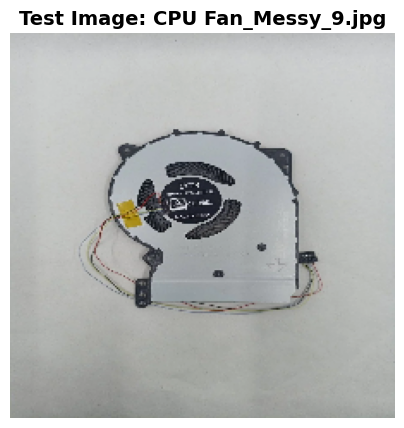

                    MODEL PREDICTION COMPARISON
CPU Fan_Messy_9.jpg
 [1] Baseline DenseNet-121  : CPU Fan      (99.94% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (99.54% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (99.70% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.04% | Opt Dense:   0.42% | MobileNet:   0.29%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.03% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.02% | Opt Dense:   0.01% | MobileNet:   0.00%
 CPU Fan      | Base Dense:  99.94% | Opt Dense:  99.54% | MobileNet:  99.70%



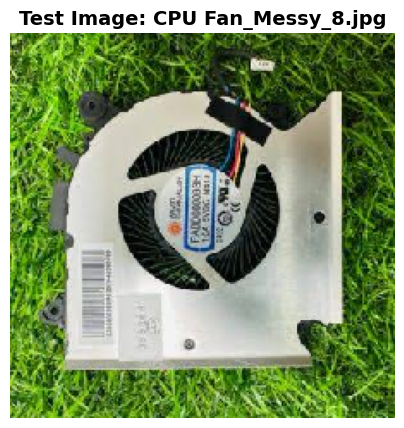

                    MODEL PREDICTION COMPARISON
CPU Fan_Messy_8.jpg
 [1] Baseline DenseNet-121  : CPU Fan      (99.96% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (99.98% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (99.69% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.22%
 Battery      | Base Dense:   0.04% | Opt Dense:   0.01% | MobileNet:   0.09%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:  99.96% | Opt Dense:  99.98% | MobileNet:  99.69%



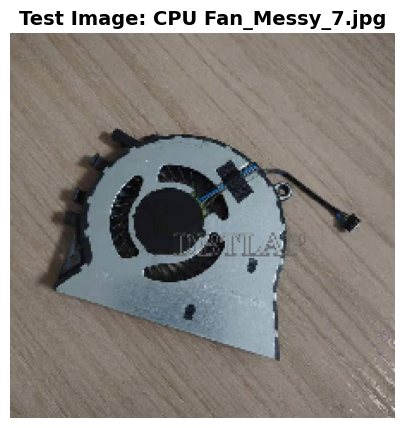

                    MODEL PREDICTION COMPARISON
CPU Fan_Messy_7.jpg
 [1] Baseline DenseNet-121  : CPU Fan      (99.99% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (99.79% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (98.73% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.01% | Opt Dense:   0.20% | MobileNet:   1.27%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:  99.99% | Opt Dense:  99.79% | MobileNet:  98.73%



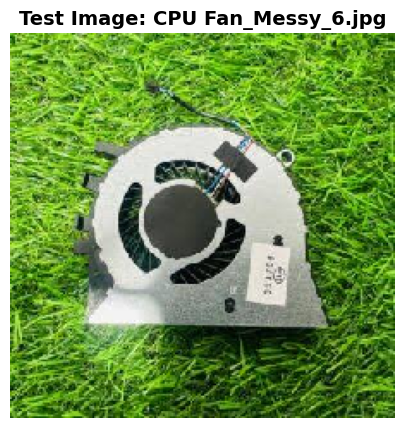

                    MODEL PREDICTION COMPARISON
CPU Fan_Messy_6.jpg
 [1] Baseline DenseNet-121  : CPU Fan      (99.98% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (98.93% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (95.13% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.02% | Opt Dense:   0.91% | MobileNet:   4.71%
 Battery      | Base Dense:   0.01% | Opt Dense:   0.16% | MobileNet:   0.14%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.03%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:  99.98% | Opt Dense:  98.93% | MobileNet:  95.13%



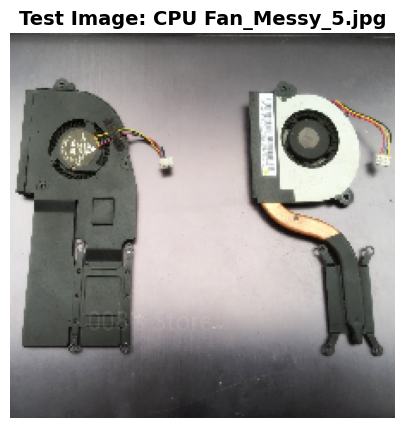

                    MODEL PREDICTION COMPARISON
CPU Fan_Messy_5.jpg
 [1] Baseline DenseNet-121  : CPU Fan      (99.79% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (95.07% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (94.86% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.20% | Opt Dense:   4.79% | MobileNet:   4.73%
 Battery      | Base Dense:   0.01% | Opt Dense:   0.14% | MobileNet:   0.41%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:  99.79% | Opt Dense:  95.07% | MobileNet:  94.86%



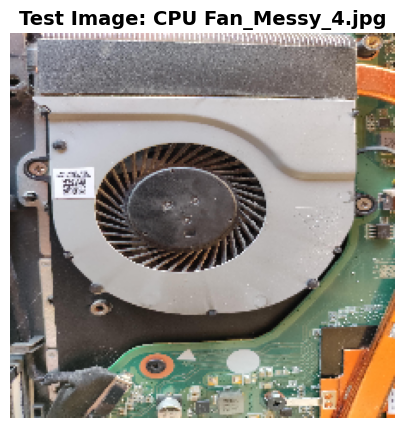

                    MODEL PREDICTION COMPARISON
CPU Fan_Messy_4.jpg
 [1] Baseline DenseNet-121  : Motherboard  (79.61% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (88.65% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (69.14% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  79.61% | Opt Dense:  10.18% | MobileNet:   2.90%
 Battery      | Base Dense:   2.61% | Opt Dense:   1.14% | MobileNet:  27.82%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.03% | MobileNet:   0.14%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:  17.78% | Opt Dense:  88.65% | MobileNet:  69.14%



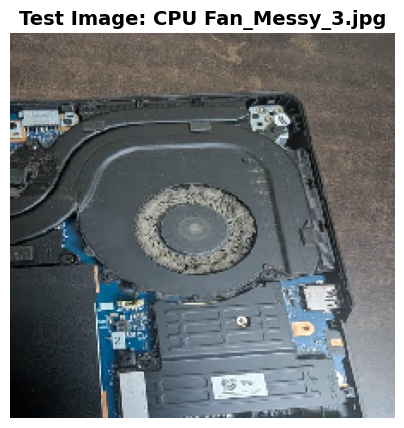

                    MODEL PREDICTION COMPARISON
CPU Fan_Messy_3.jpg
 [1] Baseline DenseNet-121  : Motherboard  (99.99% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (97.48% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (99.89% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  99.99% | Opt Dense:  97.48% | MobileNet:  99.89%
 Battery      | Base Dense:   0.01% | Opt Dense:   0.86% | MobileNet:   0.02%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   1.66% | MobileNet:   0.09%



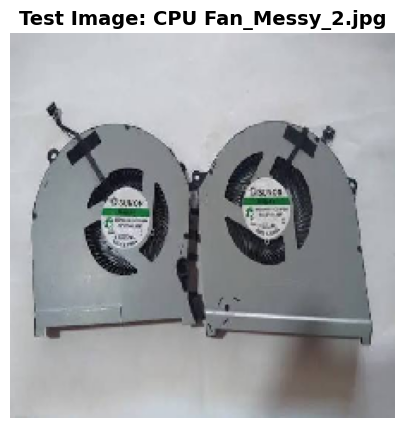

                    MODEL PREDICTION COMPARISON
CPU Fan_Messy_2.jpg
 [1] Baseline DenseNet-121  : CPU Fan      (100.00% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (99.98% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (81.85% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   4.07%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:  14.08%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense: 100.00% | Opt Dense:  99.98% | MobileNet:  81.85%



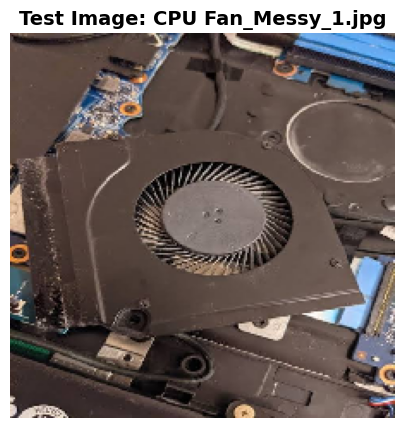

                    MODEL PREDICTION COMPARISON
CPU Fan_Messy_1.jpg
 [1] Baseline DenseNet-121  : Motherboard  (99.99% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (80.99% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (98.12% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  99.99% | Opt Dense:  80.99% | MobileNet:  98.12%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.31% | MobileNet:   0.08%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.02%
 CPU Fan      | Base Dense:   0.01% | Opt Dense:  18.69% | MobileNet:   1.78%



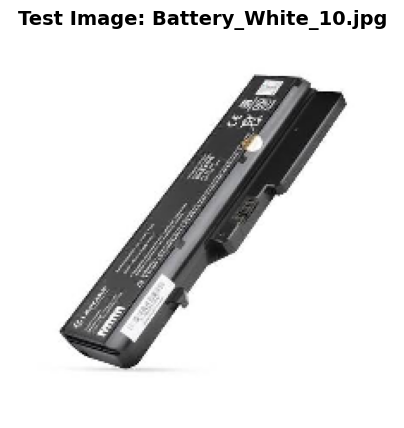

                    MODEL PREDICTION COMPARISON
Battery_White_10.jpg
 [1] Baseline DenseNet-121  : Battery      (100.00% confidence)
 [2] Optimized DenseNet-121 : Battery      (99.79% confidence)
 [3] Baseline MobileNet-V2  : Battery      (99.60% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.05% | MobileNet:   0.00%
 Battery      | Base Dense: 100.00% | Opt Dense:  99.79% | MobileNet:  99.60%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.15% | MobileNet:   0.40%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%



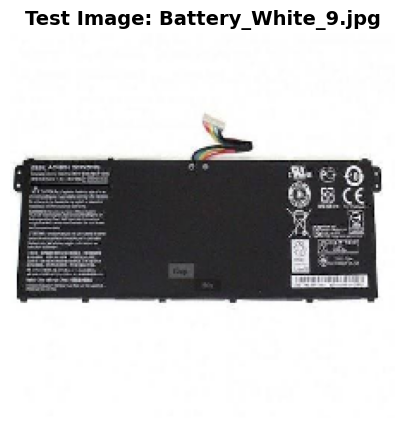

                    MODEL PREDICTION COMPARISON
Battery_White_9.jpg
 [1] Baseline DenseNet-121  : Motherboard  (95.53% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (86.39% confidence)
 [3] Baseline MobileNet-V2  : Battery      (93.20% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  95.53% | Opt Dense:  86.39% | MobileNet:   1.02%
 Battery      | Base Dense:   4.16% | Opt Dense:  10.94% | MobileNet:  93.20%
 RAM          | Base Dense:   0.30% | Opt Dense:   1.51% | MobileNet:   4.86%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.01% | Opt Dense:   1.15% | MobileNet:   0.92%



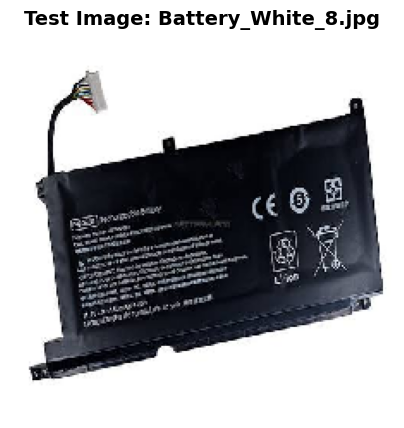

                    MODEL PREDICTION COMPARISON
Battery_White_8.jpg
 [1] Baseline DenseNet-121  : Battery      (100.00% confidence)
 [2] Optimized DenseNet-121 : Battery      (99.34% confidence)
 [3] Baseline MobileNet-V2  : Battery      (99.84% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.33% | MobileNet:   0.04%
 Battery      | Base Dense: 100.00% | Opt Dense:  99.34% | MobileNet:  99.84%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.06% | MobileNet:   0.09%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.27% | MobileNet:   0.04%



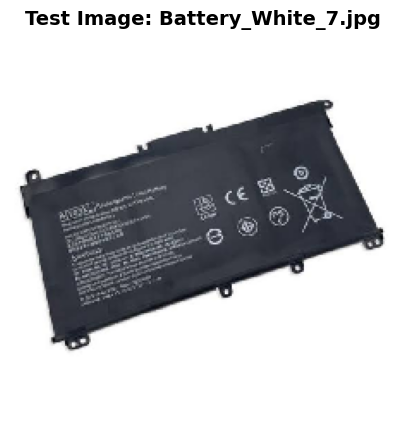

                    MODEL PREDICTION COMPARISON
Battery_White_7.jpg
 [1] Baseline DenseNet-121  : Battery      (99.93% confidence)
 [2] Optimized DenseNet-121 : Battery      (97.47% confidence)
 [3] Baseline MobileNet-V2  : Battery      (99.65% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.07% | Opt Dense:   2.01% | MobileNet:   0.09%
 Battery      | Base Dense:  99.93% | Opt Dense:  97.47% | MobileNet:  99.65%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.17% | MobileNet:   0.02%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.36% | MobileNet:   0.24%



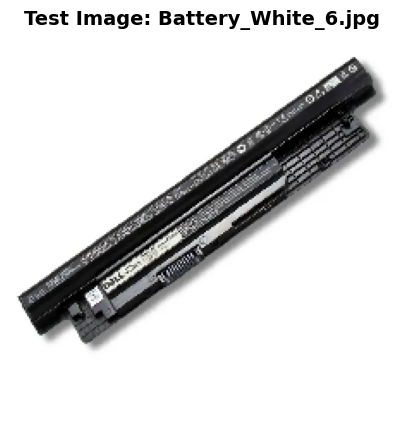

                    MODEL PREDICTION COMPARISON
Battery_White_6.jpg
 [1] Baseline DenseNet-121  : Battery      (98.28% confidence)
 [2] Optimized DenseNet-121 : Battery      (91.64% confidence)
 [3] Baseline MobileNet-V2  : Battery      (87.37% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   1.25% | Opt Dense:   0.21% | MobileNet:   0.07%
 Battery      | Base Dense:  98.28% | Opt Dense:  91.64% | MobileNet:  87.37%
 RAM          | Base Dense:   0.47% | Opt Dense:   8.14% | MobileNet:  12.56%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%



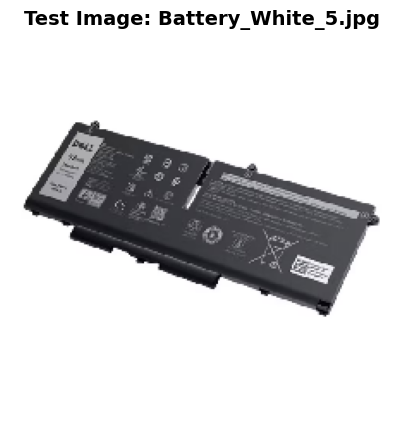

                    MODEL PREDICTION COMPARISON
Battery_White_5.jpg
 [1] Baseline DenseNet-121  : Battery      (99.92% confidence)
 [2] Optimized DenseNet-121 : Battery      (94.90% confidence)
 [3] Baseline MobileNet-V2  : Battery      (99.54% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.08% | Opt Dense:   4.42% | MobileNet:   0.01%
 Battery      | Base Dense:  99.92% | Opt Dense:  94.90% | MobileNet:  99.54%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.57% | MobileNet:   0.45%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.12% | MobileNet:   0.00%



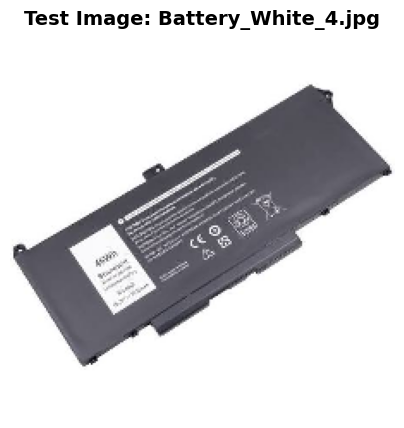

                    MODEL PREDICTION COMPARISON
Battery_White_4.jpg
 [1] Baseline DenseNet-121  : Battery      (100.00% confidence)
 [2] Optimized DenseNet-121 : Battery      (99.88% confidence)
 [3] Baseline MobileNet-V2  : Battery      (99.96% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.05% | MobileNet:   0.00%
 Battery      | Base Dense: 100.00% | Opt Dense:  99.88% | MobileNet:  99.96%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.05% | MobileNet:   0.03%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.02% | MobileNet:   0.00%



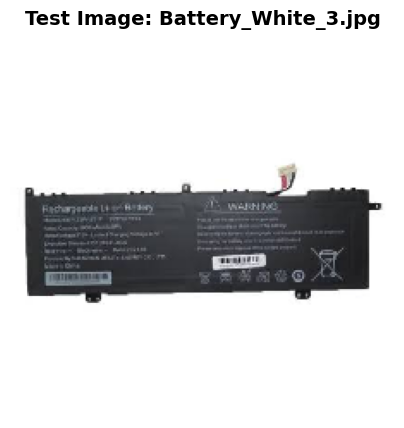

                    MODEL PREDICTION COMPARISON
Battery_White_3.jpg
 [1] Baseline DenseNet-121  : Motherboard  (79.85% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (43.79% confidence)
 [3] Baseline MobileNet-V2  : Battery      (76.91% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  79.85% | Opt Dense:  43.79% | MobileNet:  19.44%
 Battery      | Base Dense:  15.49% | Opt Dense:  35.34% | MobileNet:  76.91%
 RAM          | Base Dense:   0.02% | Opt Dense:   2.24% | MobileNet:   3.63%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.04% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   4.65% | Opt Dense:  18.60% | MobileNet:   0.02%



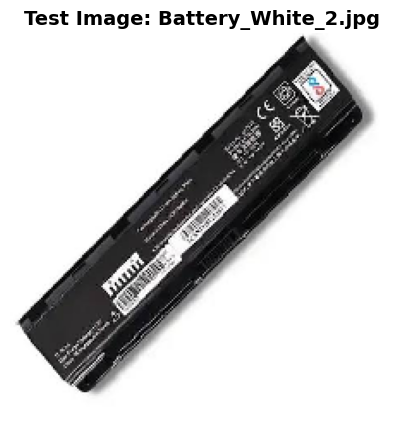

                    MODEL PREDICTION COMPARISON
Battery_White_2.jpg
 [1] Baseline DenseNet-121  : Battery      (99.95% confidence)
 [2] Optimized DenseNet-121 : Battery      (97.15% confidence)
 [3] Baseline MobileNet-V2  : Battery      (67.51% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.01%
 Battery      | Base Dense:  99.95% | Opt Dense:  97.15% | MobileNet:  67.51%
 RAM          | Base Dense:   0.05% | Opt Dense:   2.83% | MobileNet:  32.47%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.01%



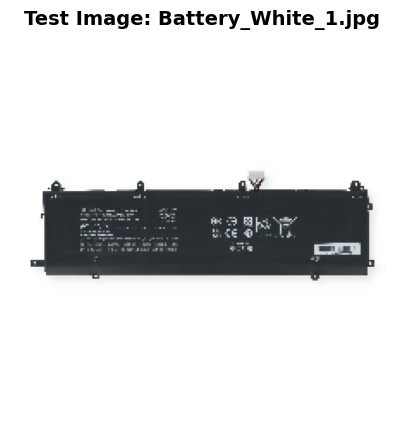

                    MODEL PREDICTION COMPARISON
Battery_White_1.jpg
 [1] Baseline DenseNet-121  : Battery      (59.68% confidence)
 [2] Optimized DenseNet-121 : Battery      (51.39% confidence)
 [3] Baseline MobileNet-V2  : Battery      (69.60% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  38.83% | Opt Dense:  28.60% | MobileNet:   0.40%
 Battery      | Base Dense:  59.68% | Opt Dense:  51.39% | MobileNet:  69.60%
 RAM          | Base Dense:   0.05% | Opt Dense:   1.99% | MobileNet:  29.90%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.03% | MobileNet:   0.02%
 CPU Fan      | Base Dense:   1.45% | Opt Dense:  17.98% | MobileNet:   0.08%



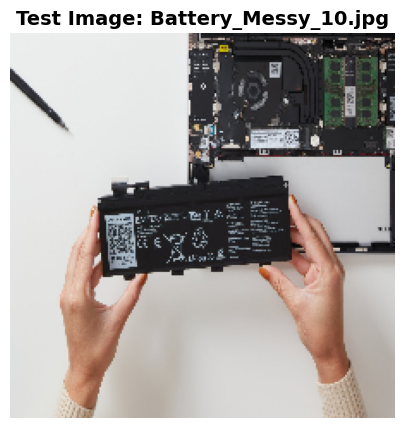

                    MODEL PREDICTION COMPARISON
Battery_Messy_10.jpg
 [1] Baseline DenseNet-121  : Motherboard  (99.51% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (98.73% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (98.10% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  99.51% | Opt Dense:  98.73% | MobileNet:  98.10%
 Battery      | Base Dense:   0.48% | Opt Dense:   0.73% | MobileNet:   1.90%
 RAM          | Base Dense:   0.01% | Opt Dense:   0.43% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.10% | MobileNet:   0.00%



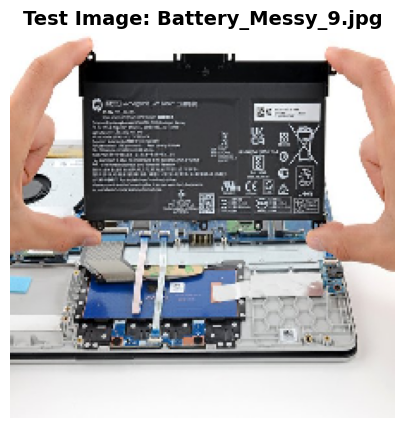

                    MODEL PREDICTION COMPARISON
Battery_Messy_9.jpg
 [1] Baseline DenseNet-121  : Motherboard  (95.92% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (95.99% confidence)
 [3] Baseline MobileNet-V2  : Battery      (93.73% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  95.92% | Opt Dense:  95.99% | MobileNet:   6.21%
 Battery      | Base Dense:   4.08% | Opt Dense:   3.60% | MobileNet:  93.73%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.30% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.10% | MobileNet:   0.05%



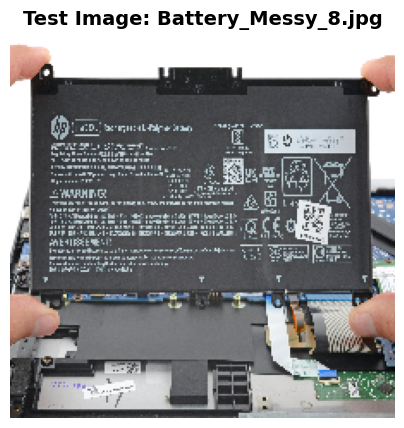

                    MODEL PREDICTION COMPARISON
Battery_Messy_8.jpg
 [1] Baseline DenseNet-121  : Motherboard  (69.94% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (82.68% confidence)
 [3] Baseline MobileNet-V2  : Battery      (94.62% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  69.94% | Opt Dense:  82.68% | MobileNet:   3.80%
 Battery      | Base Dense:  30.05% | Opt Dense:  15.92% | MobileNet:  94.62%
 RAM          | Base Dense:   0.01% | Opt Dense:   1.31% | MobileNet:   1.16%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.24%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.08% | MobileNet:   0.18%



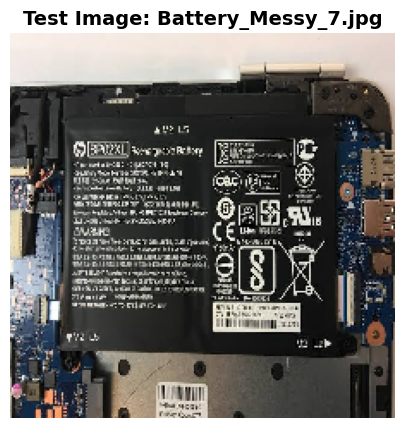

                    MODEL PREDICTION COMPARISON
Battery_Messy_7.jpg
 [1] Baseline DenseNet-121  : Motherboard  (51.17% confidence)
 [2] Optimized DenseNet-121 : Battery      (56.87% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (99.10% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  51.17% | Opt Dense:  37.00% | MobileNet:  99.10%
 Battery      | Base Dense:  48.56% | Opt Dense:  56.87% | MobileNet:   0.03%
 RAM          | Base Dense:   0.25% | Opt Dense:   5.88% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.01% | Opt Dense:   0.05% | MobileNet:   0.11%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.20% | MobileNet:   0.75%



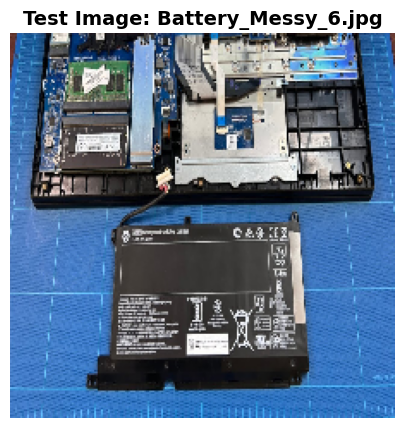

                    MODEL PREDICTION COMPARISON
Battery_Messy_6.jpg
 [1] Baseline DenseNet-121  : Motherboard  (97.04% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (88.18% confidence)
 [3] Baseline MobileNet-V2  : Battery      (59.22% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  97.04% | Opt Dense:  88.18% | MobileNet:  23.67%
 Battery      | Base Dense:   2.96% | Opt Dense:  11.56% | MobileNet:  59.22%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.26% | MobileNet:  16.62%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.39%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.11%



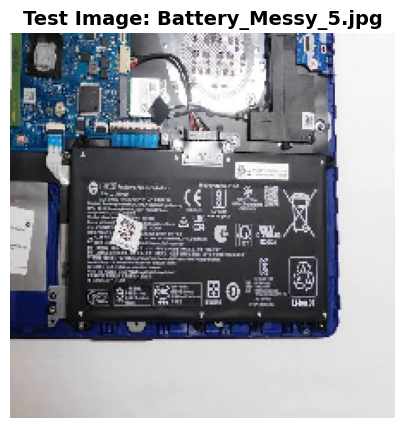

                    MODEL PREDICTION COMPARISON
Battery_Messy_5.jpg
 [1] Baseline DenseNet-121  : Motherboard  (99.97% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (98.36% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (99.99% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  99.97% | Opt Dense:  98.36% | MobileNet:  99.99%
 Battery      | Base Dense:   0.03% | Opt Dense:   1.39% | MobileNet:   0.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.13% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.12% | MobileNet:   0.00%



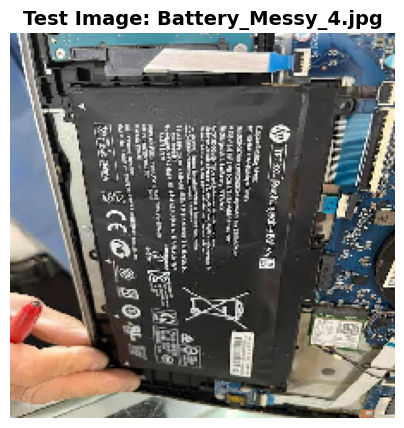

                    MODEL PREDICTION COMPARISON
Battery_Messy_4.jpg
 [1] Baseline DenseNet-121  : Battery      (93.72% confidence)
 [2] Optimized DenseNet-121 : Battery      (53.32% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (94.99% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   6.28% | Opt Dense:  45.76% | MobileNet:  94.99%
 Battery      | Base Dense:  93.72% | Opt Dense:  53.32% | MobileNet:   5.00%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.42% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.49% | MobileNet:   0.00%



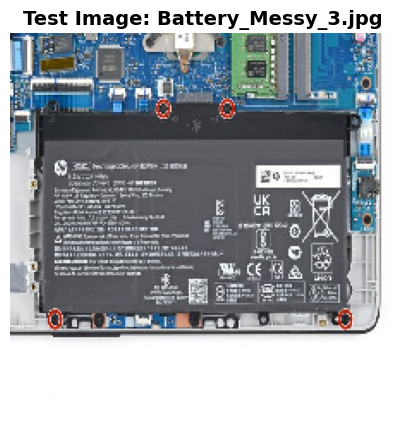

                    MODEL PREDICTION COMPARISON
Battery_Messy_3.jpg
 [1] Baseline DenseNet-121  : Motherboard  (97.84% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (88.11% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (68.53% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  97.84% | Opt Dense:  88.11% | MobileNet:  68.53%
 Battery      | Base Dense:   1.65% | Opt Dense:   6.70% | MobileNet:  26.89%
 RAM          | Base Dense:   0.49% | Opt Dense:   4.91% | MobileNet:   0.49%
 WiFi Card    | Base Dense:   0.01% | Opt Dense:   0.11% | MobileNet:   0.06%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.17% | MobileNet:   4.03%



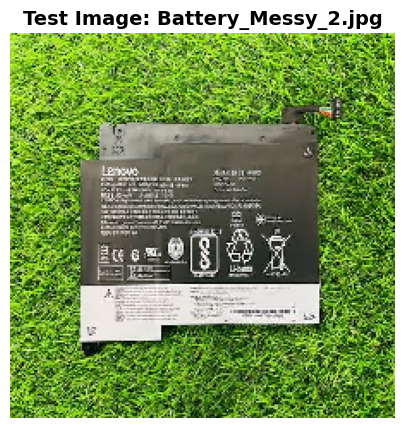

                    MODEL PREDICTION COMPARISON
Battery_Messy_2.jpg
 [1] Baseline DenseNet-121  : Battery      (98.46% confidence)
 [2] Optimized DenseNet-121 : Battery      (84.85% confidence)
 [3] Baseline MobileNet-V2  : RAM          (76.91% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   1.53% | Opt Dense:   7.31% | MobileNet:   6.23%
 Battery      | Base Dense:  98.46% | Opt Dense:  84.85% | MobileNet:   4.17%
 RAM          | Base Dense:   0.01% | Opt Dense:   6.99% | MobileNet:  76.91%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.23% | MobileNet:  11.92%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.62% | MobileNet:   0.77%



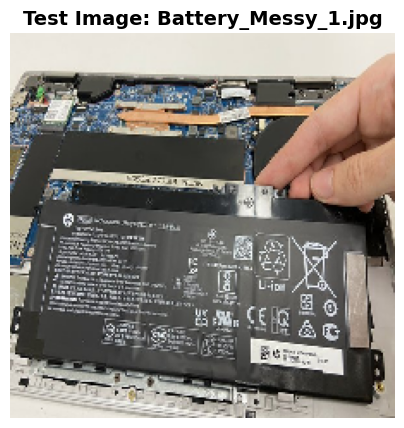

                    MODEL PREDICTION COMPARISON
Battery_Messy_1.jpg
 [1] Baseline DenseNet-121  : Motherboard  (97.65% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (94.28% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (94.10% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  97.65% | Opt Dense:  94.28% | MobileNet:  94.10%
 Battery      | Base Dense:   2.35% | Opt Dense:   5.48% | MobileNet:   2.93%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.19% | MobileNet:   0.11%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   2.83%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.04% | MobileNet:   0.02%

                      FINAL PREDICTION SUMMARY (ALL IMAGES)
| Class       | Baseline DenseNet | Optimized DenseNet | MobileNet-V2 |
| ----------- | ----------------: | -----------------: | ------------: |
| Motherboard |             20/20 |              20/20 |         20/20 |
| Battery     |             10/2

In [38]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from google.colab import files
import matplotlib.pyplot as plt


# ====================================================================
# SAFETY CHECK: LOAD MODELS IF NOT ALREADY IN MEMORY
# ====================================================================

if "baseline_densenet_model" not in globals():
    print(
        "Models not found in memory. "
        "Building and loading from checkpoints..."
    )

    # Build the architectures
    baseline_densenet_model, _ = build_densenet_model(
        name="Baseline_DenseNet-121"
    )

    opt_densenet_model, _ = build_densenet_model(
        name="Optimized_DenseNet-121"
    )

    baseline_mobilenet_model, _ = build_mobilenet_model(
        name="Baseline_MobileNet-V2"
    )

    # Load the saved .keras weights
    baseline_densenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Baseline_DenseNet-121_best.keras",
        )
    )

    opt_densenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Optimized_DenseNet-121_StepB_v2_best.keras",
        )
    )

    baseline_mobilenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Baseline_MobileNet-best.keras",
        )
    )

    print("Models loaded successfully!\n")


# ====================================================================
# INITIALIZE PREDICTION TRACKERS FOR THE FINAL TABLES
# ====================================================================

# Track total files and correct predictions per class
def create_tracker():
    return {
        c: {
            "total": 0,
            "base": 0,
            "opt": 0,
            "mob": 0,
        }
        for c in TARGET_CLASSES
    }


results = create_tracker()
results_white = create_tracker()
results_messy = create_tracker()


# ====================================================================
# MANUAL IMAGE UPLOAD
# ====================================================================

print(
    "Upload ONE or MULTIPLE images "
    "(Press Ctrl+A / Cmd+A to select a whole folder):"
)

uploaded = files.upload()


# ====================================================================
# PROCESS EACH UPLOADED IMAGE
# ====================================================================

for filename in uploaded.keys():

    # ---------------------------------------------------------------
    # 1. LOAD AND RESIZE THE UPLOADED IMAGE
    # ---------------------------------------------------------------

    img_path = filename

    img = image.load_img(
        img_path,
        target_size=IMAGE_SIZE,
    )

    img_array = image.img_to_array(img)

    img_batch = np.expand_dims(
        img_array,
        axis=0,
    )

    # ---------------------------------------------------------------
    # 2. GET PREDICTIONS FROM ALL THREE MODELS
    # ---------------------------------------------------------------

    preds_base_dense = (
        baseline_densenet_model.predict(
            img_batch,
            verbose=0,
        )[0]
    )

    preds_opt_dense = (
        opt_densenet_model.predict(
            img_batch,
            verbose=0,
        )[0]
    )

    preds_mobile = (
        baseline_mobilenet_model.predict(
            img_batch,
            verbose=0,
        )[0]
    )

    # ---------------------------------------------------------------
    # 3. HELPER FUNCTION TO FIND WINNING CLASS & CONFIDENCE
    # ---------------------------------------------------------------

    def get_top_pred(preds):
        idx = np.argmax(preds)

        return (
            TARGET_CLASSES[idx],
            preds[idx] * 100,
        )


    class_base_dense, conf_base_dense = get_top_pred(
        preds_base_dense
    )

    class_opt_dense, conf_opt_dense = get_top_pred(
        preds_opt_dense
    )

    class_mobile, conf_mobile = get_top_pred(
        preds_mobile
    )

    # ---------------------------------------------------------------
    # 4. TRACK ACCURACY
    # ---------------------------------------------------------------

    # Extract true class from filename:
    # "Class_Condition_Number.ext"
    true_class_raw = filename.split("_")[0].lower()

    # Map back to exactly how TARGET_CLASSES spells it
    true_class = None

    for c in TARGET_CLASSES:
        if c.lower() == true_class_raw:
            true_class = c
            break

    is_white = "white" in filename.lower()
    is_messy = "messy" in filename.lower()

    if true_class:

        # -----------------------------------------------------------
        # Update Total Tracker
        # -----------------------------------------------------------

        results[true_class]["total"] += 1

        if class_base_dense == true_class:
            results[true_class]["base"] += 1

        if class_opt_dense == true_class:
            results[true_class]["opt"] += 1

        if class_mobile == true_class:
            results[true_class]["mob"] += 1

        # -----------------------------------------------------------
        # Update White Tracker
        # -----------------------------------------------------------

        if is_white:
            results_white[true_class]["total"] += 1

            if class_base_dense == true_class:
                results_white[true_class]["base"] += 1

            if class_opt_dense == true_class:
                results_white[true_class]["opt"] += 1

            if class_mobile == true_class:
                results_white[true_class]["mob"] += 1

        # -----------------------------------------------------------
        # Update Messy Tracker
        # -----------------------------------------------------------

        if is_messy:
            results_messy[true_class]["total"] += 1

            if class_base_dense == true_class:
                results_messy[true_class]["base"] += 1

            if class_opt_dense == true_class:
                results_messy[true_class]["opt"] += 1

            if class_mobile == true_class:
                results_messy[true_class]["mob"] += 1

    # ---------------------------------------------------------------
    # 5. DISPLAY THE UPLOADED IMAGE
    # ---------------------------------------------------------------

    plt.figure(figsize=(5, 5))

    plt.imshow(img)
    plt.axis("off")

    plt.title(
        f"Test Image: {filename}",
        fontsize=14,
        fontweight="bold",
    )

    plt.show()

    # ---------------------------------------------------------------
    # 6. PRINT COMPARATIVE RESULTS
    # ---------------------------------------------------------------

    print(
        "===================================================================="
    )

    print(
        "                    MODEL PREDICTION COMPARISON"
    )

    print(filename)

    print(
        "===================================================================="
    )

    print(
        f" [1] Baseline DenseNet-121  : "
        f"{class_base_dense:12s} "
        f"({conf_base_dense:.2f}% confidence)"
    )

    print(
        f" [2] Optimized DenseNet-121 : "
        f"{class_opt_dense:12s} "
        f"({conf_opt_dense:.2f}% confidence)"
    )

    print(
        f" [3] Baseline MobileNet-V2  : "
        f"{class_mobile:12s} "
        f"({conf_mobile:.2f}% confidence)"
    )

    print(
        "===================================================================="
    )

    print(
        "\n--- Detailed Probabilities Breakdown ---"
    )

    for i, c in enumerate(TARGET_CLASSES):

        print(
            f" {c:12s} | "
            f"Base Dense: {preds_base_dense[i] * 100:6.2f}% | "
            f"Opt Dense: {preds_opt_dense[i] * 100:6.2f}% | "
            f"MobileNet: {preds_mobile[i] * 100:6.2f}%"
        )

    print(
        "====================================================================\n"
    )


# ====================================================================
# PRINT FINAL ACCURACY SUMMARY TABLES
# ====================================================================

def print_summary_table(title, tracker):

    print(
        "===================================================================="
    )

    print(
        f"                      {title}"
    )

    print(
        "===================================================================="
    )

    print(
        "| Class       | Baseline DenseNet | "
        "Optimized DenseNet | MobileNet-V2 |"
    )

    print(
        "| ----------- | ----------------: | "
        "-----------------: | ------------: |"
    )

    total_base = 0
    total_opt = 0
    total_mob = 0
    total_all = 0

    for c in TARGET_CLASSES:

        tot = tracker[c]["total"]

        # Only show classes that were actually tested
        if tot > 0:

            base = tracker[c]["base"]
            opt = tracker[c]["opt"]
            mob = tracker[c]["mob"]

            total_base += base
            total_opt += opt
            total_mob += mob
            total_all += tot

            base_str = f"{base}/{tot}"
            opt_str = f"{opt}/{tot}"
            mob_str = f"{mob}/{tot}"

            print(
                f"| {c:11s} | "
                f"{base_str:>17s} | "
                f"{opt_str:>18s} | "
                f"{mob_str:>13s} |"
            )

    if total_all > 0:

        base_pct = (
            total_base / total_all
        ) * 100

        opt_pct = (
            total_opt / total_all
        ) * 100

        mob_pct = (
            total_mob / total_all
        ) * 100

        tot_base_str = (
            f"**{total_base}/{total_all} "
            f"({base_pct:.0f}%)**"
        )

        tot_opt_str = (
            f"**{total_opt}/{total_all} "
            f"({opt_pct:.0f}%)**"
        )

        tot_mob_str = (
            f"**{total_mob}/{total_all} "
            f"({mob_pct:.0f}%)**"
        )

        print(
            f"| **Total**   | "
            f"{tot_base_str:>17s} | "
            f"{tot_opt_str:>18s} | "
            f"{tot_mob_str:>13s} |"
        )

    print(
        "====================================================================\n"
    )


# ====================================================================
# PRINT ALL 3 SUMMARY TABLES
# ====================================================================

print_summary_table(
    "FINAL PREDICTION SUMMARY (ALL IMAGES)",
    results,
)

print_summary_table(
    "WHITE BACKGROUND ONLY",
    results_white,
)

print_summary_table(
    "MESSY BACKGROUND ONLY",
    results_messy,
)

In [37]:
import os
import numpy as np
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from tensorflow.keras.preprocessing import image
from google.colab import files
import matplotlib.cm as cm


# ====================================================================
# HEATMAP GENERATOR FUNCTIONS
# ====================================================================

def make_gradcam_heatmap(img_array, model):
    last_conv_layer_name = None

    for layer in model.layers:
        if layer.name == "gap":
            break

        last_conv_layer_name = layer.name

    grad_model = tf.keras.models.Model(
        inputs=[model.inputs],
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.output,
        ],
    )

    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)

        pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(
        class_channel,
        last_conv_layer_output,
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2),
    )

    last_conv_layer_output = last_conv_layer_output[0]

    heatmap = (
        last_conv_layer_output
        @ pooled_grads[..., tf.newaxis]
    )

    heatmap = tf.squeeze(heatmap)

    heatmap = (
        tf.maximum(heatmap, 0)
        / tf.math.reduce_max(heatmap)
    )

    return (
        heatmap.numpy(),
        preds[0],
        pred_index,
    )


def overlay_heatmap(img_array, heatmap):
    heatmap_rescaled = np.uint8(255 * heatmap)

    jet = cm.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]

    jet_heatmap = jet_colors[heatmap_rescaled]

    jet_heatmap = tf.keras.preprocessing.image.array_to_img(
        jet_heatmap
    )

    jet_heatmap = jet_heatmap.resize(
        (
            img_array.shape[1],
            img_array.shape[0],
        )
    )

    jet_heatmap = tf.keras.preprocessing.image.img_to_array(
        jet_heatmap
    )

    superimposed_img = (
        jet_heatmap * 0.4
        + img_array
    )

    return tf.keras.preprocessing.image.array_to_img(
        superimposed_img
    )


def get_top_pred(preds):
    idx = np.argmax(preds)

    return (
        TARGET_CLASSES[idx],
        preds[idx] * 100,
    )


# ====================================================================
# SETUP TRACKERS & MANUAL UPLOAD
# ====================================================================

def create_tracker():
    return {
        c: {
            "total": 0,
            "base": 0,
            "opt": 0,
            "mob": 0,
        }
        for c in TARGET_CLASSES
    }


results_total = create_tracker()
results_white = create_tracker()
results_messy = create_tracker()


print(
    "Upload ONE or MULTIPLE images "
    "(Press Ctrl+A / Cmd+A to select a whole folder):"
)

uploaded = files.upload()

pdf_filename = "Ultimate_OOD_Report.pdf"

print(
    f"Generating {pdf_filename}... "
    "(This may take a minute for 100 images)"
)


# ====================================================================
# GENERATE PDF PAGES
# ====================================================================

with PdfPages(pdf_filename) as pdf:

    for filename in uploaded.keys():

        # ------------------------------------------------------------
        # 1. TRACKING LOGIC
        # ------------------------------------------------------------

        true_class_raw = filename.split("_")[0].lower()

        true_class = None

        for c in TARGET_CLASSES:
            if c.lower() == true_class_raw:
                true_class = c
                break

        is_white = "white" in filename.lower()
        is_messy = "messy" in filename.lower()

        # ------------------------------------------------------------
        # 2. IMAGE PREP
        # ------------------------------------------------------------

        img = image.load_img(
            filename,
            target_size=IMAGE_SIZE,
        )

        img_array = image.img_to_array(img)

        img_batch = np.expand_dims(
            img_array,
            axis=0,
        )

        # ------------------------------------------------------------
        # 3. HEATMAPS & PREDICTIONS
        # ------------------------------------------------------------

        hm_base, preds_base_dense, idx_base = (
            make_gradcam_heatmap(
                img_batch,
                baseline_densenet_model,
            )
        )

        hm_opt, preds_opt_dense, idx_opt = (
            make_gradcam_heatmap(
                img_batch,
                opt_densenet_model,
            )
        )

        hm_mob, preds_mobile, idx_mob = (
            make_gradcam_heatmap(
                img_batch,
                baseline_mobilenet_model,
            )
        )

        over_base = overlay_heatmap(
            img_array,
            hm_base,
        )

        over_opt = overlay_heatmap(
            img_array,
            hm_opt,
        )

        over_mob = overlay_heatmap(
            img_array,
            hm_mob,
        )

        class_base_dense, conf_base_dense = get_top_pred(
            preds_base_dense
        )

        class_opt_dense, conf_opt_dense = get_top_pred(
            preds_opt_dense
        )

        class_mobile, conf_mobile = get_top_pred(
            preds_mobile
        )

        # ------------------------------------------------------------
        # UPDATE TRACKERS
        # Only update summary tables if the filename contains
        # a valid class name.
        # ------------------------------------------------------------

        if true_class:

            results_total[true_class]["total"] += 1

            if is_white:
                results_white[true_class]["total"] += 1

            if is_messy:
                results_messy[true_class]["total"] += 1

            if class_base_dense == true_class:

                results_total[true_class]["base"] += 1

                if is_white:
                    results_white[true_class]["base"] += 1

                if is_messy:
                    results_messy[true_class]["base"] += 1

            if class_opt_dense == true_class:

                results_total[true_class]["opt"] += 1

                if is_white:
                    results_white[true_class]["opt"] += 1

                if is_messy:
                    results_messy[true_class]["opt"] += 1

            if class_mobile == true_class:

                results_total[true_class]["mob"] += 1

                if is_white:
                    results_white[true_class]["mob"] += 1

                if is_messy:
                    results_messy[true_class]["mob"] += 1

        # ------------------------------------------------------------
        # 4. DRAW THE PAGE
        # ------------------------------------------------------------

        fig = plt.figure(figsize=(14, 10))

        gs = fig.add_gridspec(
            2,
            3,
            height_ratios=[1, 1.2],
        )

        # ------------------------------------------------------------
        # Original Test Image
        # ------------------------------------------------------------

        ax1 = fig.add_subplot(gs[0, 0])

        ax1.imshow(img)
        ax1.axis("off")

        ax1.set_title(
            f"Test Image: {filename}",
            fontsize=14,
            fontweight="bold",
        )

        # ------------------------------------------------------------
        # Prediction Comparison
        # ------------------------------------------------------------

        ax2 = fig.add_subplot(gs[0, 1:])
        ax2.axis("off")

        report_text = (
            "MODEL PREDICTION COMPARISON\n"
            f"{'=' * 65}\n"
        )

        report_text += (
            f"[1] Base DenseNet-121 : "
            f"{class_base_dense:12s} "
            f"({conf_base_dense:.2f}%)\n"
        )

        report_text += (
            f"[2] Opt DenseNet-121  : "
            f"{class_opt_dense:12s} "
            f"({conf_opt_dense:.2f}%)\n"
        )

        report_text += (
            f"[3] Base MobileNet-V2 : "
            f"{class_mobile:12s} "
            f"({conf_mobile:.2f}%)\n\n"
        )

        report_text += (
            "DETAILED PROBABILITIES BREAKDOWN\n"
            f"{'-' * 65}\n"
        )

        report_text += (
            f"{'Class':<14s} | "
            f"{'Base Dense':<12s} | "
            f"{'Opt Dense':<12s} | "
            f"{'MobileNet':<12s}\n"
        )

        report_text += f"{'-' * 65}\n"

        for i, c in enumerate(TARGET_CLASSES):

            report_text += (
                f" {c:13s} | "
                f"{preds_base_dense[i] * 100:>9.2f}% | "
                f"{preds_opt_dense[i] * 100:>9.2f}% | "
                f"{preds_mobile[i] * 100:>9.2f}%\n"
            )

        ax2.text(
            0.0,
            0.9,
            report_text,
            fontsize=12,
            family="monospace",
            verticalalignment="top",
        )

        # ------------------------------------------------------------
        # Base DenseNet Heatmap
        # ------------------------------------------------------------

        ax3 = fig.add_subplot(gs[1, 0])

        ax3.imshow(over_base)
        ax3.axis("off")

        ax3.set_title(
            f"[1] Base DenseNet\n"
            f"Pred: {class_base_dense}",
            fontsize=12,
            fontweight="bold",
        )

        # ------------------------------------------------------------
        # Optimized DenseNet Heatmap
        # ------------------------------------------------------------

        ax4 = fig.add_subplot(gs[1, 1])

        ax4.imshow(over_opt)
        ax4.axis("off")

        ax4.set_title(
            f"[2] Opt DenseNet\n"
            f"Pred: {class_opt_dense}",
            fontsize=12,
            fontweight="bold",
        )

        # ------------------------------------------------------------
        # MobileNet-V2 Heatmap
        # ------------------------------------------------------------

        ax5 = fig.add_subplot(gs[1, 2])

        ax5.imshow(over_mob)
        ax5.axis("off")

        ax5.set_title(
            f"[3] MobileNet-V2\n"
            f"Pred: {class_mobile}",
            fontsize=12,
            fontweight="bold",
        )

        plt.tight_layout()

        pdf.savefig(fig)
        plt.close()

    # =================================================================
    # GENERATE THE FINAL SUMMARY PAGE
    # =================================================================

    def generate_table_text(title, tracker):

        text = (
            f"{'=' * 68}\n"
            f"                 {title}\n"
            f"{'=' * 68}\n"
        )

        text += (
            "| Class       | Base DenseNet   | "
            "Opt DenseNet    | MobileNet-V2   |\n"
        )

        text += (
            "| ----------- | --------------: | "
            "--------------: | --------------: |\n"
        )

        t_base = 0
        t_opt = 0
        t_mob = 0
        t_all = 0

        for c in TARGET_CLASSES:

            tot = tracker[c]["total"]

            if tot > 0:

                b = tracker[c]["base"]
                o = tracker[c]["opt"]
                m = tracker[c]["mob"]

                t_base += b
                t_opt += o
                t_mob += m
                t_all += tot

                text += (
                    f"| {c:11s} | "
                    f"{b}/{tot:<11} | "
                    f"{o}/{tot:<11} | "
                    f"{m}/{tot:<11} |\n"
                )

        if t_all > 0:

            text += (
                "| ----------- | --------------: | "
                "--------------: | --------------: |\n"
            )

            base_pct = (t_base / t_all) * 100
            opt_pct = (t_opt / t_all) * 100
            mob_pct = (t_mob / t_all) * 100

            text += (
                f"| TOTAL       | "
                f"{t_base}/{t_all} ({base_pct:2.0f}%) | "
                f"{t_opt}/{t_all} ({opt_pct:2.0f}%) | "
                f"{t_mob}/{t_all} ({mob_pct:2.0f}%) |\n"
            )

        text += (
            f"{'=' * 68}\n\n"
        )

        return text

    # ---------------------------------------------------------------
    # Create Final Summary Page
    # ---------------------------------------------------------------

    fig = plt.figure(figsize=(14, 12))

    ax = fig.add_subplot(111)
    ax.axis("off")

    full_text = generate_table_text(
        "FINAL PREDICTION SUMMARY (ALL IMAGES)",
        results_total,
    )

    full_text += generate_table_text(
        "WHITE BACKGROUND ONLY",
        results_white,
    )

    full_text += generate_table_text(
        "MESSY BACKGROUND ONLY",
        results_messy,
    )

    # Draw the text onto the PDF page
    ax.text(
        0.1,
        0.95,
        full_text,
        fontsize=13,
        family="monospace",
        verticalalignment="top",
    )

    pdf.savefig(fig)
    plt.close()


print(f"✅ Successfully created {pdf_filename}!")

files.download(pdf_filename)

Upload ONE or MULTIPLE images (Press Ctrl+A / Cmd+A to select a whole folder):


Generating Ultimate_OOD_Report.pdf... (This may take a minute for 100 images)
✅ Successfully created Ultimate_OOD_Report.pdf!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Generating 3-Stage Pipeline Previews...


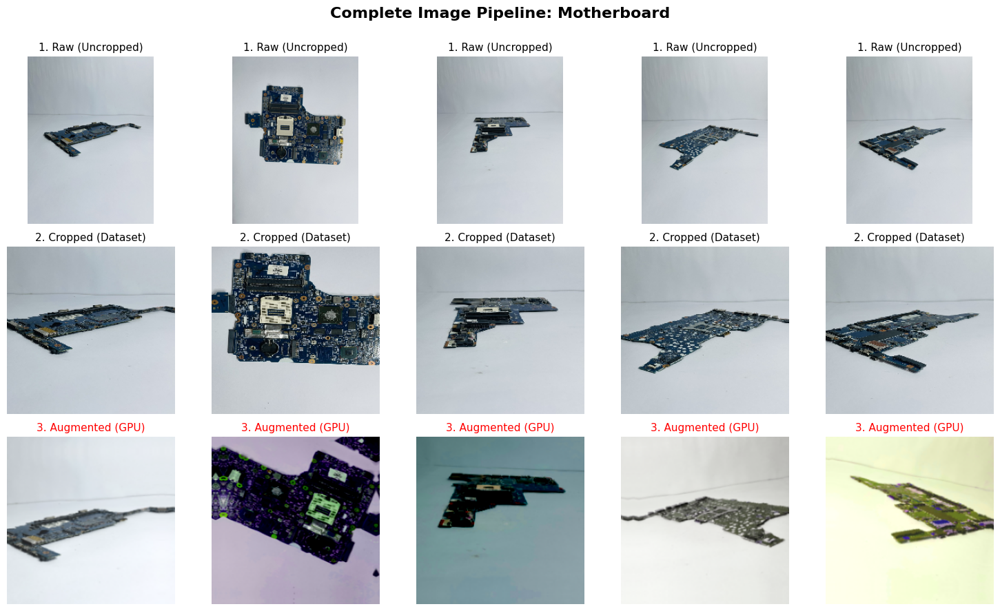

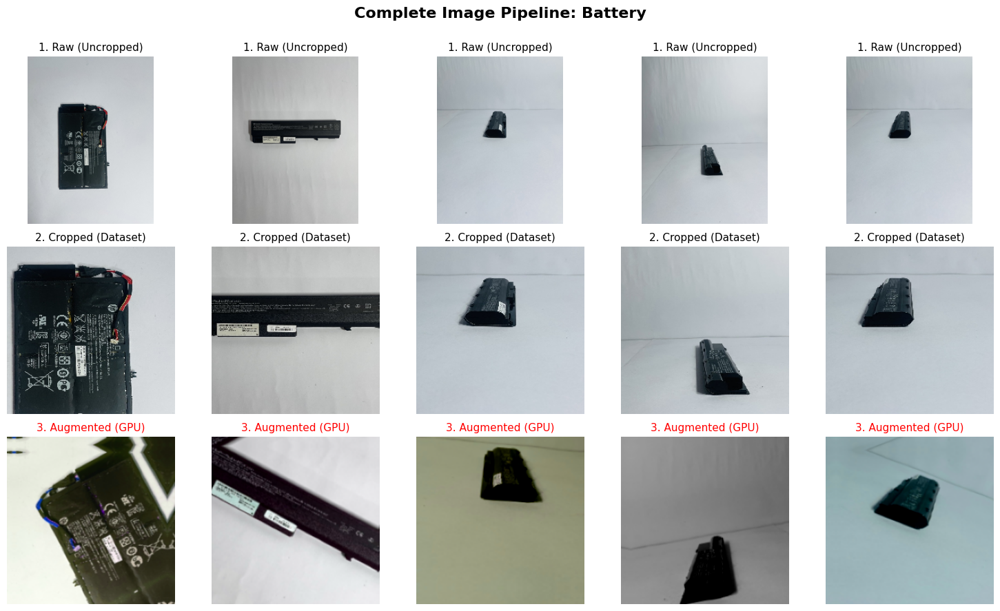

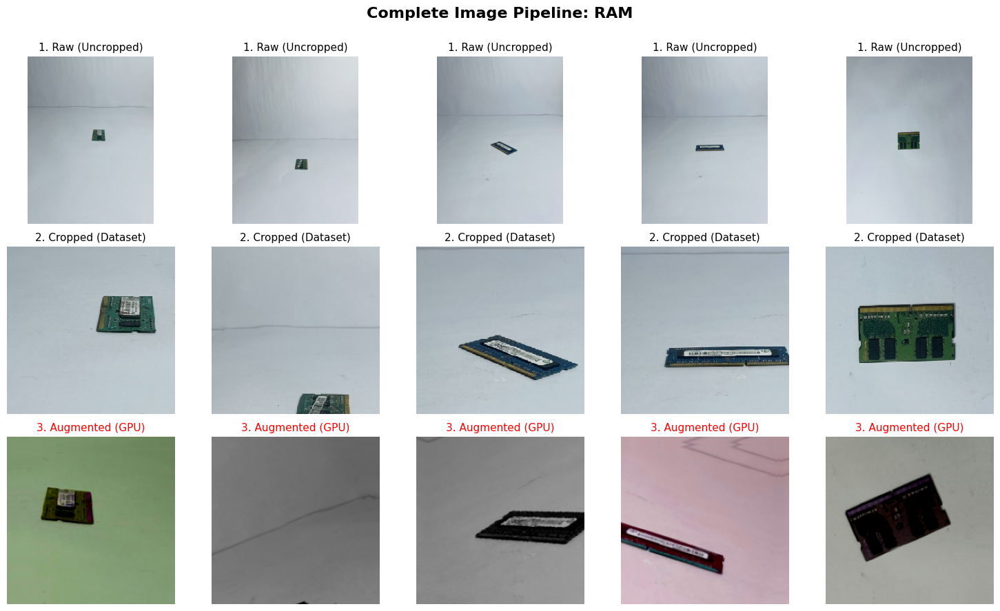

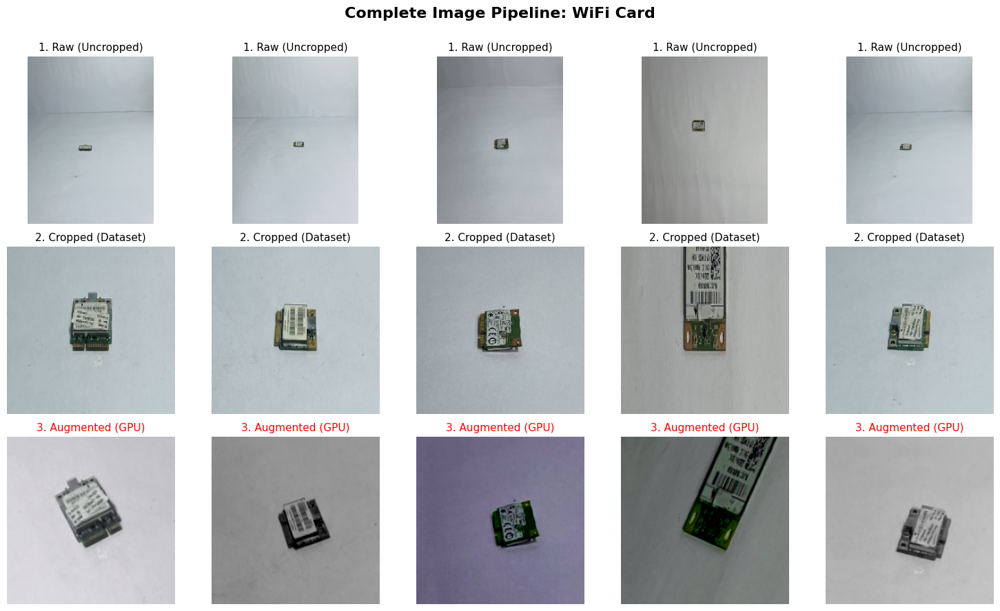

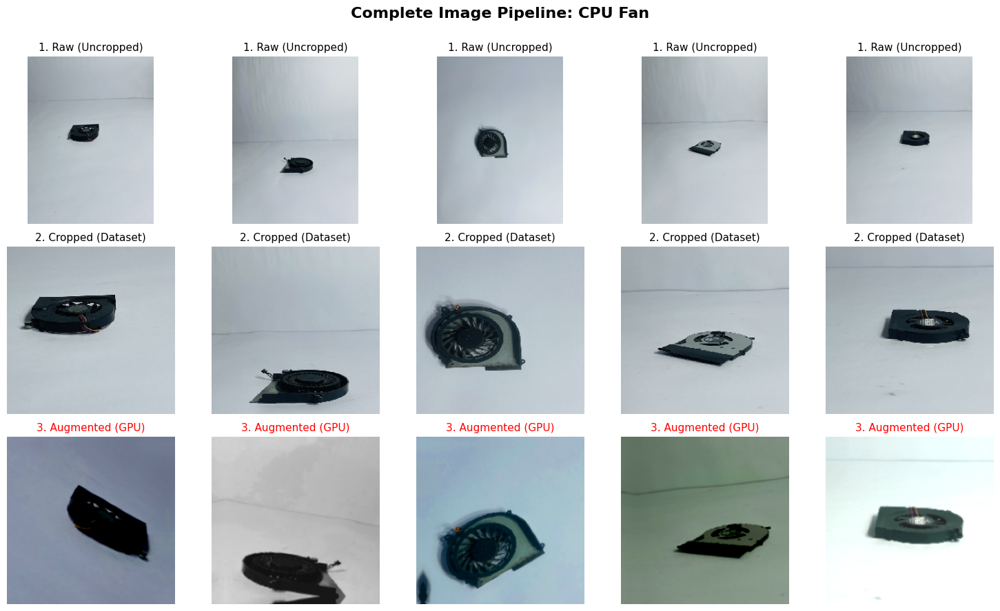

In [ ]:
import os
import random
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing import image


print("Generating 3-Stage Pipeline Previews...")


# ====================================================================
# MAP CLEAN CLASS NAMES BACK TO ORIGINAL MENDELEY FOLDER NAMES
# ====================================================================
CLASS_TO_DIR = {
    v: k for k, v in DIR_TO_CLASS.items()
}


# ====================================================================
# LOOP THROUGH EACH OF THE 5 CLASSES
# ====================================================================
for component in TARGET_CLASSES:

    raw_dir_name = CLASS_TO_DIR[component]

    raw_dir_path = os.path.join(
        LOCAL_SOURCE_DIR,
        raw_dir_name
    )

    train_dir_path = os.path.join(
        BASE_OUTPUT_DIR,
        "train",
        component
    )


    # ------------------------------------------------------------
    # Get all valid images in the training folder for this class
    # ------------------------------------------------------------
    all_files = [
        f
        for f in os.listdir(train_dir_path)
        if f.lower().endswith(
            (".png", ".jpg", ".jpeg")
        )
    ]


    # Pick exactly 5 random images
    selected_files = random.sample(
        all_files,
        5
    )


    # ------------------------------------------------------------
    # Create a 3x5 grid (Raw -> Cropped -> Augmented)
    # ------------------------------------------------------------
    fig, axes = plt.subplots(
        3,
        5,
        figsize=(15, 9)
    )

    fig.suptitle(
        f"Complete Image Pipeline: {component}",
        fontsize=16,
        fontweight="bold"
    )


    for i, filename in enumerate(selected_files):

        # ========================================================
        # TOP ROW: Raw, Uncropped Image
        # ========================================================
        raw_path = os.path.join(
            raw_dir_path,
            filename
        )

        raw_img = image.load_img(
            raw_path
        )

        axes[0, i].imshow(raw_img)

        axes[0, i].set_title(
            "1. Raw (Uncropped)",
            fontsize=11
        )

        axes[0, i].axis("off")


        # ========================================================
        # MIDDLE ROW: Cropped Dataset Image
        # ========================================================
        train_path = os.path.join(
            train_dir_path,
            filename
        )

        train_img = image.load_img(
            train_path,
            target_size=IMAGE_SIZE
        )

        train_array = image.img_to_array(
            train_img
        )

        axes[1, i].imshow(
            train_array.astype("uint8")
        )

        axes[1, i].set_title(
            "2. Cropped (Dataset)",
            fontsize=11
        )

        axes[1, i].axis("off")


        # ========================================================
        # BOTTOM ROW: Augmented Image
        # ========================================================
        img_batch = tf.expand_dims(
            train_array,
            0
        )

        aug_batch = data_augmentation(
            img_batch,
            training=True
        )

        aug_img = (
            aug_batch[0]
            .numpy()
            .astype("uint8")
        )

        axes[2, i].imshow(
            aug_img
        )

        axes[2, i].set_title(
            "3. Augmented (GPU)",
            fontsize=11,
            color="red"
        )

        axes[2, i].axis("off")


    # ============================================================
    # DISPLAY FIGURE
    # ============================================================
    plt.tight_layout()

    plt.subplots_adjust(
        top=0.90
    )  # Make room for the main title

    plt.show()

In [ ]:
import os
import random
import numpy as np
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from tensorflow.keras.preprocessing import image
from google.colab import files
import matplotlib.cm as cm


# ====================================================================
# 1. LOAD MODELS FROM DISK (Failsafe)
# ====================================================================
print("Loading models from checkpoints...")

base_dense = load_model_fresh(
    CHECKPOINT_PATHS["Baseline DenseNet-121"]
)

opt_dense = load_model_fresh(
    CHECKPOINT_PATHS["Optimized DenseNet-121"]
)

base_mobile = load_model_fresh(
    CHECKPOINT_PATHS["Baseline MobileNet-V2"]
)

print("Models loaded successfully!\n")


# ====================================================================
# 2. UNIVERSAL GRAD-CAM GENERATOR
# ====================================================================
def make_gradcam_heatmap(img_array, model):
    last_conv_layer_name = None

    for layer in model.layers:
        if layer.name == "gap":
            break

        last_conv_layer_name = layer.name

    grad_model = tf.keras.models.Model(
        inputs=[model.inputs],
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)

        pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(
        class_channel,
        last_conv_layer_output
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    last_conv_layer_output = last_conv_layer_output[0]

    heatmap = (
        last_conv_layer_output
        @ pooled_grads[..., tf.newaxis]
    )

    heatmap = tf.squeeze(heatmap)

    heatmap = (
        tf.maximum(heatmap, 0)
        / tf.math.reduce_max(heatmap)
    )

    return (
        heatmap.numpy(),
        preds[0],
        pred_index
    )


def overlay_heatmap(img_array, heatmap):
    heatmap_rescaled = np.uint8(
        255 * heatmap
    )

    jet = cm.get_cmap("jet")

    jet_colors = jet(
        np.arange(256)
    )[:, :3]

    jet_heatmap = jet_colors[
        heatmap_rescaled
    ]

    jet_heatmap = (
        tf.keras.preprocessing.image.array_to_img(
            jet_heatmap
        )
    )

    jet_heatmap = jet_heatmap.resize(
        (
            img_array.shape[1],
            img_array.shape[0]
        )
    )

    jet_heatmap = (
        tf.keras.preprocessing.image.img_to_array(
            jet_heatmap
        )
    )

    superimposed_img = (
        jet_heatmap * 0.4
        + img_array
    )

    return (
        tf.keras.preprocessing.image.array_to_img(
            superimposed_img
        )
    )


# ====================================================================
# 3. AUTO-FETCH FROM VALIDATION FOLDER
# ====================================================================
val_dir = os.path.join(
    BASE_OUTPUT_DIR,
    "val"
)

image_paths_to_test = []

print(
    "Selecting 2 random images per class "
    "from the Validation folder..."
)


for component in TARGET_CLASSES:

    class_dir = os.path.join(
        val_dir,
        component
    )

    if os.path.exists(class_dir):

        all_files = [
            f
            for f in os.listdir(class_dir)
            if f.lower().endswith(
                (".png", ".jpg", ".jpeg")
            )
        ]

        # Change the '2' below if you want
        # more or fewer images per class.
        selected = random.sample(
            all_files,
            min(2, len(all_files))
        )

        for f in selected:
            image_paths_to_test.append(
                os.path.join(
                    class_dir,
                    f
                )
            )


# ====================================================================
# 4. PDF GENERATION PIPELINE
# ====================================================================
pdf_filename = "Internal_Validation_Report.pdf"

print(
    f"Generating {pdf_filename} "
    f"with {len(image_paths_to_test)} total pages..."
)


with PdfPages(pdf_filename) as pdf:

    for filepath in image_paths_to_test:

        # ------------------------------------------------------------
        # Extract filename and true folder class
        # ------------------------------------------------------------
        filename = os.path.basename(
            filepath
        )

        true_class = os.path.basename(
            os.path.dirname(filepath)
        )


        # ------------------------------------------------------------
        # 1. Load image
        # ------------------------------------------------------------
        img = image.load_img(
            filepath,
            target_size=IMAGE_SIZE
        )

        img_array = image.img_to_array(
            img
        )

        img_batch = np.expand_dims(
            img_array,
            axis=0
        )


        # ------------------------------------------------------------
        # 2. Get predictions & heatmaps
        #    for ALL THREE models
        # ------------------------------------------------------------
        (
            hm_base,
            preds_base,
            idx_base
        ) = make_gradcam_heatmap(
            img_batch,
            base_dense
        )

        (
            hm_opt,
            preds_opt,
            idx_opt
        ) = make_gradcam_heatmap(
            img_batch,
            opt_dense
        )

        (
            hm_mob,
            preds_mob,
            idx_mob
        ) = make_gradcam_heatmap(
            img_batch,
            base_mobile
        )


        # Create heatmap overlays
        over_base = overlay_heatmap(
            img_array,
            hm_base
        )

        over_opt = overlay_heatmap(
            img_array,
            hm_opt
        )

        over_mob = overlay_heatmap(
            img_array,
            hm_mob
        )


        # ------------------------------------------------------------
        # 3. Create a grid layout for the PDF page
        # ------------------------------------------------------------
        fig = plt.figure(
            figsize=(14, 10)
        )

        gs = fig.add_gridspec(
            2,
            3,
            height_ratios=[1, 1.2]
        )


        # ============================================================
        # TOP LEFT: Original Image
        # ============================================================
        ax1 = fig.add_subplot(
            gs[0, 0]
        )

        ax1.imshow(img)
        ax1.axis("off")

        ax1.set_title(
            f"True Class: {true_class}\n"
            f"File: {filename}",
            fontsize=14,
            fontweight="bold"
        )


        # ============================================================
        # TOP RIGHT: Data Report
        # ============================================================
        ax2 = fig.add_subplot(
            gs[0, 1:]
        )

        ax2.axis("off")


        report_text = (
            f"MODEL PREDICTION COMPARISON\n"
            f"{'=' * 65}\n"
        )

        report_text += (
            f"[1] Base DenseNet-121: "
            f"{TARGET_CLASSES[idx_base]} "
            f"({preds_base[idx_base] * 100:.1f}%)\n"
        )

        report_text += (
            f"[2] Opt DenseNet-121 : "
            f"{TARGET_CLASSES[idx_opt]} "
            f"({preds_opt[idx_opt] * 100:.1f}%)\n"
        )

        report_text += (
            f"[3] Base MobileNet-V2: "
            f"{TARGET_CLASSES[idx_mob]} "
            f"({preds_mob[idx_mob] * 100:.1f}%)\n\n"
        )


        report_text += (
            f"DETAILED PROBABILITIES BREAKDOWN\n"
            f"{'-' * 65}\n"
        )

        report_text += (
            f"{'Class':<14s} | "
            f"{'Base Dense':<12s} | "
            f"{'Opt Dense':<12s} | "
            f"{'MobileNet':<12s}\n"
            f"{'-' * 65}\n"
        )


        for i, c in enumerate(TARGET_CLASSES):

            report_text += (
                f"{c:<14s} | "
                f"{preds_base[i] * 100:>9.2f}% | "
                f"{preds_opt[i] * 100:>9.2f}% | "
                f"{preds_mob[i] * 100:>9.2f}%\n"
            )


        ax2.text(
            0.0,
            0.9,
            report_text,
            fontsize=12,
            family="monospace",
            verticalalignment="top"
        )


        # ============================================================
        # BOTTOM LEFT: Base DenseNet Heatmap
        # ============================================================
        ax3 = fig.add_subplot(
            gs[1, 0]
        )

        ax3.imshow(over_base)
        ax3.axis("off")

        ax3.set_title(
            f"[1] Base DenseNet\n"
            f"Pred: {TARGET_CLASSES[idx_base]}",
            fontsize=12,
            fontweight="bold"
        )


        # ============================================================
        # BOTTOM MIDDLE: Optimized DenseNet Heatmap
        # ============================================================
        ax4 = fig.add_subplot(
            gs[1, 1]
        )

        ax4.imshow(over_opt)
        ax4.axis("off")

        ax4.set_title(
            f"[2] Opt DenseNet\n"
            f"Pred: {TARGET_CLASSES[idx_opt]}",
            fontsize=12,
            fontweight="bold"
        )


        # ============================================================
        # BOTTOM RIGHT: MobileNet Heatmap
        # ============================================================
        ax5 = fig.add_subplot(
            gs[1, 2]
        )

        ax5.imshow(over_mob)
        ax5.axis("off")

        ax5.set_title(
            f"[3] MobileNet-V2\n"
            f"Pred: {TARGET_CLASSES[idx_mob]}",
            fontsize=12,
            fontweight="bold"
        )


        # ============================================================
        # SAVE PAGE TO PDF
        # ============================================================
        plt.tight_layout()

        pdf.savefig(fig)

        plt.close()


# ====================================================================
# DOWNLOAD PDF
# ====================================================================
print(
    f"Successfully created {pdf_filename}!"
)

files.download(pdf_filename)

Loading models from checkpoints...
Models loaded successfully!

Selecting 2 random images per class from the Validation folder...
Generating Internal_Validation_Report.pdf with 10 total pages...


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer_1']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer_3']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer_2']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/tmp/ipykernel_1925/2411139328.py:95: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cm

Successfully created Internal_Validation_Report.pdf!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
import os


# ====================================================================
# 1. FORCEFULLY EJECT GOOGLE DRIVE AND CLEAR THE CACHE
# ====================================================================
print("Ejecting Google Drive to clear old cache...")

drive.flush_and_unmount()

print("Ejected!")


# ====================================================================
# 2. RECONNECT GOOGLE DRIVE
# ====================================================================
print(
    "\nReconnecting Google Drive "
    "(You may need to grant permission again)..."
)

drive.mount(
    "/content/drive",
    force_remount=True
)

print(
    "Drive successfully reconnected and refreshed!"
)


# ====================================================================
# 3. VERIFY THE NEW CHECKPOINTS ARE THERE
# ====================================================================
CHECKPOINT_DIR = (
    "/content/drive/MyDrive/Thesis/Model_Checkpoints"
)

print(
    "\nCurrent files in your Checkpoint folder:"
)


if os.path.exists(CHECKPOINT_DIR):

    for f in os.listdir(CHECKPOINT_DIR):

        if f.endswith(".keras"):
            print(f" - {f}")

else:

    print(
        f"Could not find {CHECKPOINT_DIR}. "
        "Double check the path!"
    )

Ejecting Google Drive to clear old cache...
Ejected!

Reconnecting Google Drive (You may need to grant permission again)...
Mounted at /content/drive
Drive successfully reconnected and refreshed!

Current files in your Checkpoint folder:


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from google.colab import files
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

print(
    "Upload ONE or MULTIPLE images to generate the PDF Report:"
)

uploaded = files.upload()

pdf_filename = "OOD_Model_Evaluation_Report.pdf"

print(
    f"\nGenerating {pdf_filename}..."
)

# Open a PDF file to save our pages into
with PdfPages(pdf_filename) as pdf:

    for filename in uploaded.keys():

        # 1. Load and process image
        img_path = filename

        img = image.load_img(
            img_path,
            target_size=IMAGE_SIZE
        )

        img_array = image.img_to_array(img)

        img_batch = np.expand_dims(
            img_array,
            axis=0
        )

        # 2. Get predictions
        preds_base_dense = (
            baseline_densenet_model
            .predict(img_batch, verbose=0)[0]
        )

        preds_opt_dense = (
            opt_densenet_model
            .predict(img_batch, verbose=0)[0]
        )

        preds_mobile = (
            baseline_mobilenet_model
            .predict(img_batch, verbose=0)[0]
        )

        def get_top_pred(preds):
            idx = np.argmax(preds)

            return (
                TARGET_CLASSES[idx],
                preds[idx] * 100
            )

        class_base_dense, conf_base_dense = (
            get_top_pred(preds_base_dense)
        )

        class_opt_dense, conf_opt_dense = (
            get_top_pred(preds_opt_dense)
        )

        class_mobile, conf_mobile = (
            get_top_pred(preds_mobile)
        )

        # 3. Create a landscape page
        fig = plt.figure(figsize=(12, 6))

        # --- LEFT SIDE: The Image ---
        ax1 = plt.subplot(1, 2, 1)

        ax1.imshow(img)
        ax1.axis("off")

        ax1.set_title(
            f"Test Subject: {filename}",
            fontsize=14,
            fontweight="bold"
        )

        # --- RIGHT SIDE: The Data Report ---
        ax2 = plt.subplot(1, 2, 2)
        ax2.axis("off")

        # Format the text report using a monospace font
        # so the columns align perfectly
        report_text = (
            "MODEL PREDICTION COMPARISON\n"
        )

        report_text += (
            f"{'=' * 40}\n"
        )

        report_text += (
            f"[1] Base DenseNet-121: "
            f"{class_base_dense} "
            f"({conf_base_dense:.1f}%)\n"
        )

        report_text += (
            f"[2] Opt DenseNet-121 : "
            f"{class_opt_dense} "
            f"({conf_opt_dense:.1f}%)\n"
        )

        report_text += (
            f"[3] Base MobileNet-V2: "
            f"{class_mobile} "
            f"({conf_mobile:.1f}%)\n\n\n"
        )

        report_text += (
            "DETAILED PROBABILITIES BREAKDOWN\n"
        )

        report_text += (
            f"{'=' * 70}\n"
        )

        report_text += (
            f"{'Class':<14s} | "
            f"{'Base Dense':<12s} | "
            f"{'Opt Dense':<12s} | "
            f"{'MobileNet':<12s}\n"
        )

        report_text += (
            f"{'-' * 70}\n"
        )

        for i, c in enumerate(TARGET_CLASSES):
            report_text += (
                f"{c:<14s} | "
                f"{preds_base_dense[i] * 100:>9.2f}% | "
                f"{preds_opt_dense[i] * 100:>9.2f}% | "
                f"{preds_mobile[i] * 100:>9.2f}%\n"
            )

        # Draw the text onto the right side of the PDF page
        ax2.text(
            0.0,
            0.8,
            report_text,
            fontsize=11,
            family="monospace",
            verticalalignment="top"
        )

        plt.tight_layout()

        # Save this figure as a new page in the PDF
        pdf.savefig(fig)
        plt.close()

print(
    f"Successfully created {pdf_filename}!"
)

# Automatically trigger the browser download
files.download(pdf_filename)

In [ ]:
import numpy as np
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files
import matplotlib.cm as cm

# 1. Find the last convolutional layer right before the GlobalAveragePooling layer
last_conv_layer_name = None

for layer in opt_densenet_model.layers:
    if layer.name == "gap":
        break

    last_conv_layer_name = layer.name

# 2. Build a Grad-CAM model that outputs both
#    the predictions AND the feature map
grad_model = tf.keras.models.Model(
    inputs=[opt_densenet_model.inputs],
    outputs=[
        opt_densenet_model.get_layer(
            last_conv_layer_name
        ).output,
        opt_densenet_model.output
    ]
)


def make_gradcam_heatmap(
    img_array,
    grad_model,
    pred_index=None
):
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(
            img_array
        )

        if pred_index is None:
            pred_index = tf.argmax(preds[0])

        class_channel = preds[:, pred_index]

    # Calculate gradients of the top predicted class
    # with regard to the feature map
    grads = tape.gradient(
        class_channel,
        last_conv_layer_output
    )

    # Average the gradients spatially
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    # Multiply each channel in the feature map array
    # by how important this channel is
    last_conv_layer_output = last_conv_layer_output[0]

    heatmap = (
        last_conv_layer_output
        @ pooled_grads[..., tf.newaxis]
    )

    heatmap = tf.squeeze(heatmap)

    # Normalize the heatmap between 0 and 1
    heatmap = (
        tf.maximum(heatmap, 0)
        / tf.math.reduce_max(heatmap)
    )

    return (
        heatmap.numpy(),
        preds[0],
        pred_index
    )


print(
    "Upload an image to generate an AI Attention Heatmap:"
)

uploaded = files.upload()

for filename in uploaded.keys():

    # Load and prep image
    img = image.load_img(
        filename,
        target_size=IMAGE_SIZE
    )

    img_array = image.img_to_array(img)

    img_batch = np.expand_dims(
        img_array,
        axis=0
    )

    # Generate Heatmap
    heatmap, preds, top_idx = make_gradcam_heatmap(
        img_batch,
        grad_model
    )

    pred_class = TARGET_CLASSES[top_idx]
    confidence = preds[top_idx] * 100

    # Rescale heatmap to a range 0-255
    heatmap_rescaled = np.uint8(
        255 * heatmap
    )

    # Use jet colormap to colorize heatmap
    jet = cm.get_cmap("jet")

    jet_colors = jet(
        np.arange(256)
    )[:, :3]

    jet_heatmap = jet_colors[
        heatmap_rescaled
    ]

    # Superimpose the heatmap onto original image
    jet_heatmap = (
        tf.keras.preprocessing.image
        .array_to_img(jet_heatmap)
    )

    jet_heatmap = jet_heatmap.resize(
        (
            img_array.shape[1],
            img_array.shape[0]
        )
    )

    jet_heatmap = (
        tf.keras.preprocessing.image
        .img_to_array(jet_heatmap)
    )

    # Blend original and heatmap
    superimposed_img = (
        jet_heatmap * 0.4
        + img_array
    )

    superimposed_img = (
        tf.keras.preprocessing.image
        .array_to_img(superimposed_img)
    )

    # Plotting
    plt.figure(figsize=(10, 5))

    # Original Image
    ax1 = plt.subplot(1, 2, 1)

    ax1.imshow(img)
    ax1.axis("off")

    ax1.set_title(
        "Original Image",
        fontsize=14
    )

    # Heatmap Image
    ax2 = plt.subplot(1, 2, 2)

    ax2.imshow(superimposed_img)
    ax2.axis("off")

    color = (
        "green"
        if confidence > 50
        else "orange"
    )

    ax2.set_title(
        f"AI Focus Map\n"
        f"Pred: {pred_class} ({confidence:.1f}%)",
        fontsize=14,
        color=color,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

# Appendix: Exploratory & Checkup Scripts

In [ ]:
# -------------------------------------------------------------------------
# APPENDIX A: Data Leakage Check (Perceptual Hashing)
# -------------------------------------------------------------------------
def hash_all_images(base_dir, splits):
    records = []
    for split in splits:
        split_dir = os.path.join(base_dir, split)
        if not os.path.exists(split_dir): continue
        for class_name in os.listdir(split_dir):
            class_dir = os.path.join(split_dir, class_name)
            if not os.path.isdir(class_dir): continue
            for fname in os.listdir(class_dir):
                fpath = os.path.join(class_dir, fname)
                try:
                    phash = imagehash.phash(Image.open(fpath).convert("RGB"))
                    records.append({"split": split, "class": class_name, "filename": fname, "path": fpath, "hash": phash})
                except Exception as e: print(f"Error {fpath}: {e}")
    return records

def find_cross_split_matches(records, hash_distance_threshold=5):
    matches = []
    n = len(records)
    for i in range(n):
        for j in range(i + 1, n):
            r1, r2 = records[i], records[j]
            if r1["split"] == r2["split"]: continue
            distance = r1["hash"] - r2["hash"]
            if distance <= hash_distance_threshold:
                matches.append({"distance": distance, "split_1": r1["split"], "file_1": r1["filename"], "split_2": r2["split"], "file_2": r2["filename"]})
    return matches

print("Hashing images...")
records = hash_all_images(BASE_OUTPUT_DIR, SPLITS)
matches = find_cross_split_matches(records, 5)

if not matches:
    print("✅ No cross-split leakage found.")
else:
    print(f"⚠️ Found {len(matches)} suspicious cross-split matches:")
    for m in sorted(matches, key=lambda x: x["distance"])[:10]:
        print(f"  dist={m['distance']} | {m['split_1']}/{m['file_1']} <--> {m['split_2']}/{m['file_2']}")


In [ ]:
# -------------------------------------------------------------------------
# APPENDIX B: Dataset Deduplication & Crop Visualization
# -------------------------------------------------------------------------
# SUMMARY: Deduplicates the RAW source dataset (before ETL/split).
# Groups near-identical images into clusters using perceptual hashing, then keeps
# only the sharpest image per cluster (via Laplacian variance).

import os
import shutil
import cv2
import random
import numpy as np
from PIL import Image
import imagehash
import matplotlib.pyplot as plt

# ---- CONFIG ----
RAW_SOURCE_DIR = "/content/mendeley_raw_data/Laptop Components Image Dataset to Classify Different Components/Raw Data/Raw Data"
DEDUP_OUTPUT_DIR = "/content/deduplicated_raw_data_3"
REMOVED_DUPES_DIR = "/content/removed_duplicates_for_review_3"
CROP_DEBUG_DIR = "/content/crop_debug_3"
HASH_DISTANCE_THRESHOLD = 5
SAVE_CROP_DEBUG_IMAGES = True

TARGET_RAW_DIRS = [
    "5. Motherboard",
    "1. Battery",
    "8. RAM",
    "11. WifiCard",
    "20. CPUFan",
]

CROP_FRACTIONS = {
    "5. Motherboard": (0.70, 0.70),
    "1. Battery":     (0.55, 0.55),
    "8. RAM":         (0.30, 0.30),
    "20. CPUFan":     (0.45, 0.45),
}
DEFAULT_CROP_FRACTION = (0.5, 0.5)

DETECTION_BASED_CLASSES = {"11. WifiCard"}
SATURATION_THRESHOLD = 35
MIN_OBJECT_AREA_FRACTION = 0.0005
MAX_OBJECT_AREA_FRACTION = 0.90
DETECTION_MARGIN_MULTIPLIER = 1.5
DETECTION_FALLBACK_CROP_FRACTION = (0.35, 0.35)

os.makedirs(DEDUP_OUTPUT_DIR, exist_ok=True)
os.makedirs(REMOVED_DUPES_DIR, exist_ok=True)
if SAVE_CROP_DEBUG_IMAGES:
    os.makedirs(CROP_DEBUG_DIR, exist_ok=True)

# ---- HELPER FUNCTIONS ----
def center_crop(image_bgr, width_fraction, height_fraction):
    h, w = image_bgr.shape[:2]
    crop_w = max(1, int(w * width_fraction))
    crop_h = max(1, int(h * height_fraction))
    x0 = (w - crop_w) // 2
    y0 = (h - crop_h) // 2
    return image_bgr[y0:y0 + crop_h, x0:x0 + crop_w]

def detect_object_bbox_by_saturation(image_bgr):
    h_img, w_img = image_bgr.shape[:2]
    total_area = h_img * w_img
    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
    saturation = hsv[:, :, 1]
    _, mask = cv2.threshold(saturation, SATURATION_THRESHOLD, 255, cv2.THRESH_BINARY)
    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours: return None
    largest = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(largest)
    area_fraction = area / total_area
    if area_fraction < MIN_OBJECT_AREA_FRACTION or area_fraction > MAX_OBJECT_AREA_FRACTION: return None
    return cv2.boundingRect(largest)

def crop_via_saturation_detection(image_bgr, fallback_fraction):
    h_img, w_img = image_bgr.shape[:2]
    bbox = detect_object_bbox_by_saturation(image_bgr)
    if bbox is None: return center_crop(image_bgr, *fallback_fraction), False
    x, y, w, h = bbox
    margin_x = int(w * DETECTION_MARGIN_MULTIPLIER)
    margin_y = int(h * DETECTION_MARGIN_MULTIPLIER)
    x0 = max(0, x - margin_x)
    y0 = max(0, y - margin_y)
    x1 = min(w_img, x + w + margin_x)
    y1 = min(h_img, y + h + margin_y)
    return image_bgr[y0:y1, x0:x1], True

def laplacian_variance_gray(gray_img):
    return cv2.Laplacian(gray_img, cv2.CV_64F).var()

def hash_class_images(class_dir, class_name):
    records = []
    debug_dir = os.path.join(CROP_DEBUG_DIR, class_name) if SAVE_CROP_DEBUG_IMAGES else None
    if debug_dir: os.makedirs(debug_dir, exist_ok=True)
    use_detection = class_name in DETECTION_BASED_CLASSES
    width_fraction, height_fraction = CROP_FRACTIONS.get(class_name, DEFAULT_CROP_FRACTION)
    fallback_count = 0

    for fname in os.listdir(class_dir):
        fpath = os.path.join(class_dir, fname)
        if not os.path.isfile(fpath): continue
        try:
            image_bgr = cv2.imread(fpath)
            if image_bgr is None: continue

            if use_detection:
                cropped_bgr, was_detected = crop_via_saturation_detection(image_bgr, DETECTION_FALLBACK_CROP_FRACTION)
                if not was_detected: fallback_count += 1
            else:
                cropped_bgr = center_crop(image_bgr, width_fraction, height_fraction)

            cropped_gray = cv2.cvtColor(cropped_bgr, cv2.COLOR_BGR2GRAY)
            sharpness = laplacian_variance_gray(cropped_gray)
            phash = imagehash.phash(Image.fromarray(cv2.cvtColor(cropped_bgr, cv2.COLOR_BGR2RGB)))

            if debug_dir: cv2.imwrite(os.path.join(debug_dir, fname), cropped_bgr)
            records.append({"filename": fname, "path": fpath, "hash": phash, "sharpness": sharpness})
        except Exception as e: print(f"Could not process {fpath}: {e}")
    return records

def cluster_by_hash(records, threshold):
    n = len(records)
    parent = list(range(n))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    def union(x, y):
        rx, ry = find(x), find(y)
        if rx != ry: parent[ry] = rx

    for i in range(n):
        for j in range(i + 1, n):
            if records[i]["hash"] - records[j]["hash"] <= threshold: union(i, j)

    clusters = {}
    for i in range(n):
        clusters.setdefault(find(i), []).append(records[i])
    return list(clusters.values())

def dedupe_class(class_name, class_dir):
    mode = "saturation-DETECTION" if class_name in DETECTION_BASED_CLASSES else "fixed center-crop"
    print(f"\nProcessing class: {class_name}  ({mode})")
    records = hash_class_images(class_dir, class_name)
    clusters = cluster_by_hash(records, HASH_DISTANCE_THRESHOLD)

    out_class_dir = os.path.join(DEDUP_OUTPUT_DIR, class_name)
    removed_class_dir = os.path.join(REMOVED_DUPES_DIR, class_name)
    os.makedirs(out_class_dir, exist_ok=True)
    os.makedirs(removed_class_dir, exist_ok=True)

    kept, removed = 0, 0
    for cluster in clusters:
        cluster_sorted = sorted(cluster, key=lambda r: r["sharpness"], reverse=True)
        best = cluster_sorted[0]
        shutil.copy2(best["path"], os.path.join(out_class_dir, best["filename"]))
        kept += 1
        for dup in cluster_sorted[1:]:
            shutil.copy2(dup["path"], os.path.join(removed_class_dir, dup["filename"]))
            removed += 1

    return kept, removed

# ---- EXECUTE DEDUPLICATION ----
summary = {}
if os.path.exists(RAW_SOURCE_DIR):
    for class_name in TARGET_RAW_DIRS:
        class_dir = os.path.join(RAW_SOURCE_DIR, class_name)
        if os.path.isdir(class_dir):
            kept, removed = dedupe_class(class_name, class_dir)
            summary[class_name] = {"kept": kept, "removed": removed}

print("\n===== SUMMARY =====")
for class_name, counts in summary.items():
    print(f"{class_name:15s}: {counts['kept']:3d} unique / {counts['kept'] + counts['removed']:3d} raw")

# -------------------------------------------------------------------------
# CROP VISUALIZATION TOOL
# -------------------------------------------------------------------------
def load_image_rgb(path):
    img_bgr = cv2.imread(path)
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB) if img_bgr is not None else None

def show_original_vs_cropped(class_name, samples_per_class=5):
    original_dir = os.path.join(RAW_SOURCE_DIR, class_name)
    cropped_dir = os.path.join(CROP_DEBUG_DIR, class_name)

    if not os.path.exists(original_dir) or not os.path.exists(cropped_dir): return

    common_files = sorted(set(os.listdir(original_dir)) & set(os.listdir(cropped_dir)))
    if not common_files: return

    sample_files = random.sample(common_files, min(samples_per_class, len(common_files)))

    sets_per_row = 3
    num_rows = (len(sample_files) + sets_per_row - 1) // sets_per_row

    fig, axes = plt.subplots(num_rows, sets_per_row * 2, figsize=(18, 5 * num_rows))
    axes = np.atleast_2d(axes)
    fig.suptitle(f"Original vs. Cropped — {class_name}", fontsize=16, fontweight="bold")

    for i, fname in enumerate(sample_files):
        set_row, set_pos = i // sets_per_row, i % sets_per_row
        orig_col, crop_col = set_pos * 2, set_pos * 2 + 1

        orig_img = load_image_rgb(os.path.join(original_dir, fname))
        crop_img = load_image_rgb(os.path.join(cropped_dir, fname))

        if orig_img is not None:
            axes[set_row][orig_col].imshow(orig_img)
            axes[set_row][orig_col].set_title(f"Normal\n{fname}", fontsize=9)
        axes[set_row][orig_col].axis("off")

        if crop_img is not None:
            axes[set_row][crop_col].imshow(crop_img)
            axes[set_row][crop_col].set_title("Crop", fontsize=9)
        axes[set_row][crop_col].axis("off")

    plt.tight_layout()
    plt.show()

# Run visualizations
for class_name in TARGET_RAW_DIRS:
    show_original_vs_cropped(class_name, 5)

Final

In [ ]:
import os
import time
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from google.colab import files
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
)
from scipy.stats import shapiro, f_oneway, kruskal
import scikit_posthocs as sp
from statsmodels.stats.multicomp import pairwise_tukeyhsd


# ====================================================================
# 1. REGISTER CUSTOM CLASS FOR SECURE LOADING
# ====================================================================

@tf.keras.utils.register_keras_serializable()
class AdvancedColorAugmentation(tf.keras.layers.Layer):
    """
    Custom layer required to deserialize thesis_13 checkpoints correctly.
    """

    def __init__(self, **kwargs):
        super(AdvancedColorAugmentation, self).__init__(**kwargs)

    def call(self, inputs, training=None):
        if training:
            x = inputs / 255.0

            x = tf.image.random_hue(
                x,
                max_delta=0.4,
            )

            x = tf.image.random_saturation(
                x,
                lower=0.2,
                upper=3.0,
            )

            apply_gray = tf.random.uniform([]) < 0.25

            def make_gray():
                return tf.image.grayscale_to_rgb(
                    tf.image.rgb_to_grayscale(x)
                )

            x = tf.cond(
                apply_gray,
                make_gray,
                lambda: x,
            )

            return x * 255.0

        return inputs


def calculate_flops_fallback(model):
    if get_flops:
        try:
            return get_flops(
                model,
                batch_size=1,
            )
        except Exception:
            pass

    return 0


# ====================================================================
# 2. CHECKPOINT PATHS & SAFETY CHECK
# ====================================================================

CHECKPOINT_PATHS = {
    "Baseline DenseNet-121": os.path.join(
        CHECKPOINT_DIR,
        "Baseline_DenseNet-121_v2_best.keras",
    ),
    "Optimized DenseNet-121": os.path.join(
        CHECKPOINT_DIR,
        "Optimized_DenseNet-121_StepB_v2_best.keras",
    ),
    "Baseline MobileNet-V2": os.path.join(
        CHECKPOINT_DIR,
        "Baseline_MobileNet-V2_v2_best.keras",
    ),
}


for model_name, path in CHECKPOINT_PATHS.items():

    if not os.path.exists(path):

        print(f"\n❌ Missing checkpoint for {model_name}!")
        print(f"Expected to find it at: {path}")
        print(
            f"Please upload the missing file: "
            f"{os.path.basename(path)}"
        )

        uploaded = files.upload()

        for filename in uploaded.keys():

            os.makedirs(
                os.path.dirname(path),
                exist_ok=True,
            )

            shutil.move(
                filename,
                path,
            )

            print(
                f"✅ Successfully saved {filename} "
                f"to {path}\n"
            )


# ====================================================================
# 3. EVALUATION ENGINE
# ====================================================================

def load_model_fresh(checkpoint_path):
    """
    Loads the model fresh from disk and injects the Custom Layer.
    """

    return tf.keras.models.load_model(
        checkpoint_path,
        custom_objects={
            "AdvancedColorAugmentation": AdvancedColorAugmentation
        },
        compile=False,
    )


def evaluate_model(
    name,
    test_ds,
    checkpoint_path,
):

    model = load_model_fresh(
        checkpoint_path
    )

    test_labels = np.concatenate(
        [y for x, y in test_ds],
        axis=0,
    )

    true_classes = np.argmax(
        test_labels,
        axis=1,
    )

    predictions = model.predict(
        test_ds,
        verbose=0,
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1,
    )

    rep = classification_report(
        true_classes,
        predicted_classes,
        target_names=TARGET_CLASSES,
        output_dict=True,
    )


    # ---------------------------------------------------------------
    # Inference Time
    # ---------------------------------------------------------------

    sample_image = next(
        iter(test_ds)
    )[0][0:1]

    for _ in range(10):
        _ = model(
            sample_image,
            training=False,
        )

    start_time = time.time()

    for _ in range(100):
        out = model(
            sample_image,
            training=False,
        )

        _ = out.numpy()

    mean_inference_time_ms = (
        (time.time() - start_time) / 100
    ) * 1000


    # ---------------------------------------------------------------
    # Confusion Matrix
    # ---------------------------------------------------------------

    cm = confusion_matrix(
        true_classes,
        predicted_classes,
    )

    plt.figure(
        figsize=(6, 5)
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=TARGET_CLASSES,
        yticklabels=TARGET_CLASSES,
    )

    plt.title(
        f"Confusion Matrix: {name}"
    )

    plt.ylabel(
        "True Label"
    )

    plt.xlabel(
        "Predicted Label"
    )

    plt.tight_layout()

    plt.savefig(
        f'cm_{name.replace(" ", "_")}.png'
    )

    plt.show()


    # ---------------------------------------------------------------
    # Return Results
    # ---------------------------------------------------------------

    return {
        "Model": name,

        "Accuracy": accuracy_score(
            true_classes,
            predicted_classes,
        ),

        "Macro Precision": rep["macro avg"]["precision"],

        "Macro Recall": rep["macro avg"]["recall"],

        "Macro F1": rep["macro avg"]["f1-score"],

        "AUC-ROC (macro)": roc_auc_score(
            test_labels,
            predictions,
            multi_class="ovr",
            average="macro",
        ),

        "Inference Time (ms)": mean_inference_time_ms,

        "Model Size (MB)": (
            os.path.getsize(
                checkpoint_path
            ) / (1024 * 1024)
            if os.path.exists(checkpoint_path)
            else 0
        ),

        "FLOPs": calculate_flops_fallback(
            model
        ),
    }


# ====================================================================
# RUN EVALUATIONS
# ====================================================================

results = [
    evaluate_model(
        name,
        test_ds,
        path,
    )
    for name, path in CHECKPOINT_PATHS.items()
]

results_df = pd.DataFrame(
    results
)

display(
    results_df
)


if (results_df["FLOPs"] == 0).any():

    print(
        "WARNING: one or more models reported FLOPs=0."
    )


# ====================================================================
# 4. STATISTICAL TESTING
# ====================================================================

def paired_bootstrap_f1(
    checkpoint_paths,
    test_ds,
    n_iterations=30,
):

    test_labels = np.concatenate(
        [y for x, y in test_ds],
        axis=0,
    )

    true_classes = np.argmax(
        test_labels,
        axis=1,
    )

    preds = {}


    for name, path in checkpoint_paths.items():

        model = load_model_fresh(
            path
        )

        preds[name] = np.argmax(
            model.predict(
                test_ds,
                verbose=0,
            ),
            axis=1,
        )


    f1_scores = {
        name: []
        for name in checkpoint_paths.keys()
    }

    np.random.seed(42)


    for _ in range(n_iterations):

        indices = np.random.choice(
            len(true_classes),
            len(true_classes),
            replace=True,
        )

        sample_true = true_classes[
            indices
        ]


        for name in checkpoint_paths.keys():

            rep = classification_report(
                sample_true,
                preds[name][indices],
                output_dict=True,
                zero_division=0,
            )

            f1_scores[name].append(
                rep["macro avg"]["f1-score"]
            )


    return f1_scores


f1_results = paired_bootstrap_f1(
    CHECKPOINT_PATHS,
    test_ds,
)


f1_base_dense = np.array(
    f1_results[
        "Baseline DenseNet-121"
    ]
)

f1_opt_dense = np.array(
    f1_results[
        "Optimized DenseNet-121"
    ]
)

f1_base_mobile = np.array(
    f1_results[
        "Baseline MobileNet-V2"
    ]
)


# ====================================================================
# SHAPIRO-WILK NORMALITY TEST
# ====================================================================

print(
    "--- Shapiro-Wilk Normality Test ---"
)


stat1, p1 = shapiro(
    f1_base_dense
)

stat2, p2 = shapiro(
    f1_opt_dense
)

stat3, p3 = shapiro(
    f1_base_mobile
)


print(
    f"Base Dense: W={stat1:.4f}, p={p1:.4f} | "
    f"Opt Dense: W={stat2:.4f}, p={p2:.4f} | "
    f"Base Mobile: W={stat3:.4f}, p={p3:.4f}"
)


# ====================================================================
# ANOVA OR KRUSKAL-WALLIS
# ====================================================================

if (
    p1 > 0.05
    and p2 > 0.05
    and p3 > 0.05
):

    print(
        "\nDistributions normal. "
        "Proceeding with one-way ANOVA."
    )

    stat, p_val = f_oneway(
        f1_base_dense,
        f1_opt_dense,
        f1_base_mobile,
    )

    print(
        f"ANOVA F-stat={stat:.4f}, "
        f"p-value={p_val:.4e}"
    )


    if p_val < 0.05:

        data = np.concatenate(
            [
                f1_base_dense,
                f1_opt_dense,
                f1_base_mobile,
            ]
        )

        labels = (
            ["Base_Dense"] * 30
            + ["Opt_Dense"] * 30
            + ["Base_Mobile"] * 30
        )

        print(
            pairwise_tukeyhsd(
                endog=data,
                groups=labels,
                alpha=0.05,
            )
        )


else:

    print(
        "\nDistributions NOT all normal. "
        "Proceeding with Kruskal-Wallis."
    )

    stat, p_val = kruskal(
        f1_base_dense,
        f1_opt_dense,
        f1_base_mobile,
    )

    print(
        f"Kruskal-Wallis H-stat={stat:.4f}, "
        f"p-value={p_val:.4e}"
    )


    if p_val < 0.05:

        print(
            sp.posthoc_dunn(
                [
                    f1_base_dense,
                    f1_opt_dense,
                    f1_base_mobile,
                ],
                p_adjust="bonferroni",
            )
        )


❌ Missing checkpoint for Baseline DenseNet-121!
Expected to find it at: /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_DenseNet-121_v2_best.keras
Please upload the missing file: Baseline_DenseNet-121_v2_best.keras


Saving Wifi Card_White_8.jpg to Wifi Card_White_8.jpg
✅ Successfully saved Wifi Card_White_8.jpg to /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_DenseNet-121_v2_best.keras


❌ Missing checkpoint for Baseline MobileNet-V2!
Expected to find it at: /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_MobileNet-V2_v2_best.keras
Please upload the missing file: Baseline_MobileNet-V2_v2_best.keras


In [ ]:
import numpy as np
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from tensorflow.keras.preprocessing import image
from google.colab import files
import matplotlib.cm as cm


# ====================================================================
# 1. LOAD MODELS FROM DISK (Failsafe)
# ====================================================================

print("Loading models from checkpoints...")

base_dense = load_model_fresh(
    CHECKPOINT_PATHS["Baseline DenseNet-121"]
)

opt_dense = load_model_fresh(
    CHECKPOINT_PATHS["Optimized DenseNet-121"]
)

base_mobile = load_model_fresh(
    CHECKPOINT_PATHS["Baseline MobileNet-V2"]
)

print("Models loaded successfully!")


# ====================================================================
# 2. UNIVERSAL GRAD-CAM GENERATOR
# ====================================================================

def make_gradcam_heatmap(img_array, model):

    # Find the backbone model layer (right before the 'gap' layer)
    last_conv_layer_name = None

    for layer in model.layers:

        if layer.name == "gap":
            break

        last_conv_layer_name = layer.name


    grad_model = tf.keras.models.Model(
        inputs=[model.inputs],
        outputs=[
            model.get_layer(
                last_conv_layer_name
            ).output,
            model.output,
        ],
    )


    with tf.GradientTape() as tape:

        last_conv_layer_output, preds = grad_model(
            img_array
        )

        pred_index = tf.argmax(
            preds[0]
        )

        class_channel = preds[
            :,
            pred_index
        ]


    grads = tape.gradient(
        class_channel,
        last_conv_layer_output,
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2),
    )


    last_conv_layer_output = (
        last_conv_layer_output[0]
    )

    heatmap = (
        last_conv_layer_output
        @ pooled_grads[..., tf.newaxis]
    )

    heatmap = tf.squeeze(
        heatmap
    )

    heatmap = (
        tf.maximum(heatmap, 0)
        / tf.math.reduce_max(heatmap)
    )


    return (
        heatmap.numpy(),
        preds[0],
        pred_index,
    )


def overlay_heatmap(
    img_array,
    heatmap,
):

    heatmap_rescaled = np.uint8(
        255 * heatmap
    )

    jet = cm.get_cmap(
        "jet"
    )

    jet_colors = jet(
        np.arange(256)
    )[:, :3]

    jet_heatmap = jet_colors[
        heatmap_rescaled
    ]

    jet_heatmap = (
        tf.keras.preprocessing.image
        .array_to_img(
            jet_heatmap
        )
    )

    jet_heatmap = jet_heatmap.resize(
        (
            img_array.shape[1],
            img_array.shape[0],
        )
    )

    jet_heatmap = (
        tf.keras.preprocessing.image
        .img_to_array(
            jet_heatmap
        )
    )

    superimposed_img = (
        jet_heatmap * 0.4
        + img_array
    )

    return (
        tf.keras.preprocessing.image
        .array_to_img(
            superimposed_img
        )
    )


# ====================================================================
# 3. PDF GENERATION PIPELINE
# ====================================================================

print(
    "\nUpload ONE or MULTIPLE images "
    "to generate the Ultimate PDF Report:"
)

uploaded = files.upload()

pdf_filename = "Ultimate_OOD_Report.pdf"

print(
    f"\nGenerating {pdf_filename}..."
)


with PdfPages(pdf_filename) as pdf:

    for filename in uploaded.keys():

        # ------------------------------------------------------------
        # 1. Load image
        # ------------------------------------------------------------

        img = image.load_img(
            filename,
            target_size=IMAGE_SIZE,
        )

        img_array = image.img_to_array(
            img
        )

        img_batch = np.expand_dims(
            img_array,
            axis=0,
        )


        # ------------------------------------------------------------
        # 2. Get predictions & heatmaps for ALL THREE models
        # ------------------------------------------------------------

        hm_base, preds_base, idx_base = (
            make_gradcam_heatmap(
                img_batch,
                base_dense,
            )
        )

        hm_opt, preds_opt, idx_opt = (
            make_gradcam_heatmap(
                img_batch,
                opt_dense,
            )
        )

        hm_mob, preds_mob, idx_mob = (
            make_gradcam_heatmap(
                img_batch,
                base_mobile,
            )
        )


        # ------------------------------------------------------------
        # 3. Overlay heatmaps
        # ------------------------------------------------------------

        over_base = overlay_heatmap(
            img_array,
            hm_base,
        )

        over_opt = overlay_heatmap(
            img_array,
            hm_opt,
        )

        over_mob = overlay_heatmap(
            img_array,
            hm_mob,
        )


        # ------------------------------------------------------------
        # 4. Create PDF page layout
        # ------------------------------------------------------------

        fig = plt.figure(
            figsize=(14, 10)
        )

        gs = fig.add_gridspec(
            2,
            3,
            height_ratios=[
                1,
                1.2,
            ],
        )


        # ------------------------------------------------------------
        # TOP LEFT: Original Image
        # ------------------------------------------------------------

        ax1 = fig.add_subplot(
            gs[0, 0]
        )

        ax1.imshow(
            img
        )

        ax1.axis(
            "off"
        )

        ax1.set_title(
            f"Test Image: {filename}",
            fontsize=14,
            fontweight="bold",
        )


        # ------------------------------------------------------------
        # TOP RIGHT: Prediction Comparison
        # ------------------------------------------------------------

        ax2 = fig.add_subplot(
            gs[0, 1:]
        )

        ax2.axis(
            "off"
        )


        report_text = (
            "MODEL PREDICTION COMPARISON\n"
            f"{'=' * 65}\n"
        )


        report_text += (
            f"[1] Base DenseNet-121: "
            f"{TARGET_CLASSES[idx_base]} "
            f"({preds_base[idx_base] * 100:.1f}%)\n"
        )


        report_text += (
            f"[2] Opt DenseNet-121 : "
            f"{TARGET_CLASSES[idx_opt]} "
            f"({preds_opt[idx_opt] * 100:.1f}%)\n"
        )


        report_text += (
            f"[3] Base MobileNet-V2: "
            f"{TARGET_CLASSES[idx_mob]} "
            f"({preds_mob[idx_mob] * 100:.1f}%)\n\n"
        )


        report_text += (
            "DETAILED PROBABILITIES BREAKDOWN\n"
            f"{'-' * 65}\n"
        )


        report_text += (
            f"{'Class':<14s} | "
            f"{'Base Dense':<12s} | "
            f"{'Opt Dense':<12s} | "
            f"{'MobileNet':<12s}\n"
            f"{'-' * 65}\n"
        )


        for i, c in enumerate(
            TARGET_CLASSES
        ):

            report_text += (
                f"{c:<14s} | "
                f"{preds_base[i] * 100:>9.2f}% | "
                f"{preds_opt[i] * 100:>9.2f}% | "
                f"{preds_mob[i] * 100:>9.2f}%\n"
            )


        ax2.text(
            0.0,
            0.9,
            report_text,
            fontsize=12,
            family="monospace",
            verticalalignment="top",
        )


        # ------------------------------------------------------------
        # BOTTOM LEFT: Base DenseNet Heatmap
        # ------------------------------------------------------------

        ax3 = fig.add_subplot(
            gs[1, 0]
        )

        ax3.imshow(
            over_base
        )

        ax3.axis(
            "off"
        )

        ax3.set_title(
            f"[1] Base DenseNet\n"
            f"Pred: {TARGET_CLASSES[idx_base]}",
            fontsize=12,
            fontweight="bold",
        )


        # ------------------------------------------------------------
        # BOTTOM MIDDLE: Optimized DenseNet Heatmap
        # ------------------------------------------------------------

        ax4 = fig.add_subplot(
            gs[1, 1]
        )

        ax4.imshow(
            over_opt
        )

        ax4.axis(
            "off"
        )

        ax4.set_title(
            f"[2] Opt DenseNet\n"
            f"Pred: {TARGET_CLASSES[idx_opt]}",
            fontsize=12,
            fontweight="bold",
        )


        # ------------------------------------------------------------
        # BOTTOM RIGHT: MobileNet-V2 Heatmap
        # ------------------------------------------------------------

        ax5 = fig.add_subplot(
            gs[1, 2]
        )

        ax5.imshow(
            over_mob
        )

        ax5.axis(
            "off"
        )

        ax5.set_title(
            f"[3] MobileNet-V2\n"
            f"Pred: {TARGET_CLASSES[idx_mob]}",
            fontsize=12,
            fontweight="bold",
        )


        # ------------------------------------------------------------
        # Save page to PDF
        # ------------------------------------------------------------

        plt.tight_layout()

        pdf.savefig(
            fig
        )

        plt.close()


# ====================================================================
# 4. DOWNLOAD PDF
# ====================================================================

print(
    f"✅ Successfully created {pdf_filename}!"
)

files.download(
    pdf_filename
)

Loading models from checkpoints...
Models loaded successfully!

Upload ONE or MULTIPLE images to generate the Ultimate PDF Report:


Saving ram_2.jpg to ram_2 (1).jpg
Saving wificard_5.jpg to wificard_5 (2).jpg
Saving wificard_4.avif to wificard_4 (1).avif
Saving wificard_3.jpg to wificard_3 (1).jpg
Saving wificard_2.webp to wificard_2 (1).webp
Saving wificard_1.jpg to wificard_1 (1).jpg
Saving ram3.jpg to ram3 (1).jpg
Saving ram_5.webp to ram_5 (1).webp
Saving ram_4.jpg to ram_4 (1).jpg
Saving ram_1.jpg to ram_1 (1).jpg
Saving motherboard_5.jpg to motherboard_5 (1).jpg
Saving motherboard_4.png to motherboard_4 (1).png
Saving motherboard_3.jpeg to motherboard_3 (1).jpeg
Saving motherboard_2.webp to motherboard_2 (1).webp
Saving motherboard_1 to motherboard_1 (1)
Saving fan_5.jpeg to fan_5 (1).jpeg
Saving fan_4.jpg to fan_4 (1).jpg
Saving fan_3.webp to fan_3 (1).webp
Saving fan_2.jpg to fan_2 (1).jpg
Saving fan_1.jpg to fan_1 (1).jpg
Saving battery_5.jpg to battery_5 (1).jpg
Saving battery_4.jpg to battery_4 (1).jpg
Saving battery_3.webp to battery_3 (1).webp
Saving battery_2.jpg to battery_2 (1).jpg
Saving battery_1

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer_1']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer_3']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer_2']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/tmp/ipykernel_1925/3476180274.py:122: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_c

✅ Successfully created Ultimate_OOD_Report.pdf!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Eval code block

[check] Baseline DenseNet-121: /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_DenseNet-121_best.keras  (last modified 2026-09-25 05:32)
[check] Optimized DenseNet-121: /content/drive/MyDrive/Thesis/Model_Checkpoints/Optimized_DenseNet-121_StepB_best.keras  (last modified 2026-09-25 05:32)
[check] Baseline MobileNet-V2: /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_MobileNet-V2_best.keras  (last modified 2026-09-25 05:32)
^ Confirm these timestamps are from your most recent, corrected training run, not a leftover file from before the fix.



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


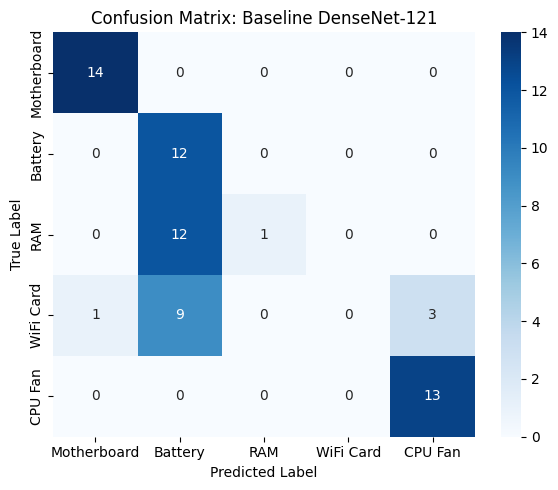

  [FLOPs] graph-profiler method failed (Input 0 of node Baseline_DenseNet-121_1/e_waste_augmentation_1/random_flip_1/AssignVariableOp was passed int64 from Baseline_DenseNet-121_1/e_waste_augmentation_1/random_flip_1/ReadVariableOp/resource:0 incompatible with expected resource.); reporting 0.


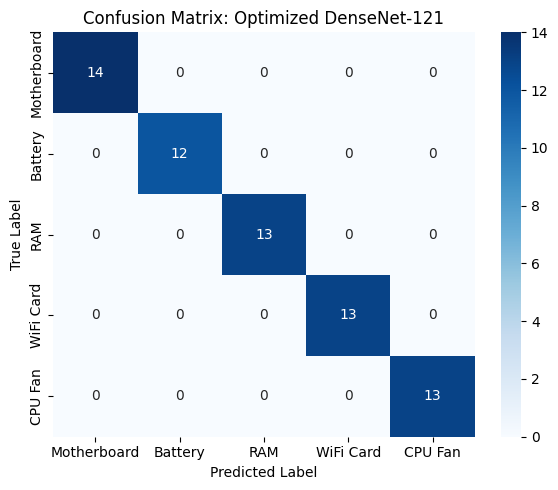

  [FLOPs] graph-profiler method failed (Input 0 of node Optimized_DenseNet-121_1/e_waste_augmentation_1/random_flip_1/AssignVariableOp was passed int64 from Optimized_DenseNet-121_1/e_waste_augmentation_1/random_flip_1/ReadVariableOp/resource:0 incompatible with expected resource.); reporting 0.


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


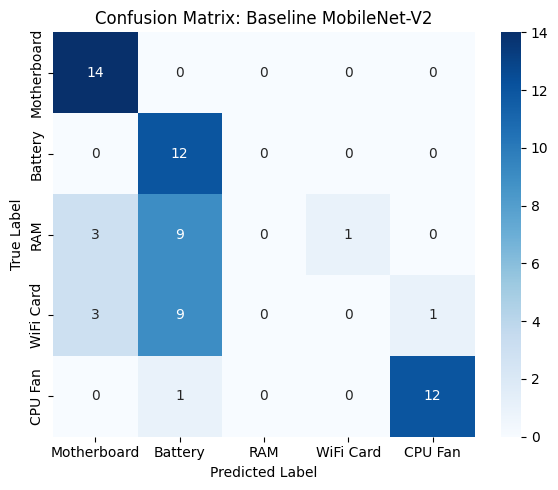

  [FLOPs] graph-profiler method failed (Input 0 of node Baseline_MobileNet-V2_1/e_waste_augmentation_1/random_flip_1/AssignVariableOp was passed int64 from Baseline_MobileNet-V2_1/e_waste_augmentation_1/random_flip_1/ReadVariableOp/resource:0 incompatible with expected resource.); reporting 0.


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,AUC-ROC (macro),Inference Time (ms),Model Size (MB),FLOPs
0,Baseline DenseNet-121,0.615385,0.621894,0.615385,0.507652,0.972762,768.786676,31.328571,0
1,Optimized DenseNet-121,1.000000,1.000000,1.000000,1.000000,1.000000,761.536174,31.330837,0
2,Baseline MobileNet-V2,0.584615,0.402035,0.584615,0.460949,0.953271,221.596229,12.960997,0



================ (A) Chapter-3-literal: independent-samples test ================
NOTE: applied here to paired data for compliance/comparison only -- see (B) below.
Shapiro-Wilk -- Base Dense: W=0.9950, p=0.0023 | Opt Dense: W=1.0000, p=1.0000 | Base Mobile: W=0.9930, p=0.0001
At least one distribution non-normal -> Kruskal-Wallis.
Kruskal-Wallis H-stat=2393.9549, p-value=0.0000e+00
               1              2             3
1   1.000000e+00  1.769073e-204  1.360835e-70
2  1.769073e-204   1.000000e+00  0.000000e+00
3   1.360835e-70   0.000000e+00  1.000000e+00

================ (B) Corrected: paired / repeated-measures test ================
Friedman chi2=1923.2000, p-value=0.0000e+00
Post-hoc pairwise Wilcoxon signed-rank, Bonferroni-corrected:
  Base_Dense vs Opt_Dense: p_adj=9.9775e-165
  Base_Dense vs Base_Mobile: p_adj=8.2880e-161
  Opt_Dense vs Base_Mobile: p_adj=9.9775e-165


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: Input data has range zero. The results may not be accurate.
  res = hypotest_fun_out(*samples, **kwds)


In [ ]:
"""
Corrected Evaluation Cell — Baseline DenseNet-121, Optimized DenseNet-121,
Baseline MobileNet-V2

Drop this in as a REPLACEMENT for your old evaluation cell (the one that
built cells 21/35 in Copy_of_thesis_13.ipynb). It assumes:
  - `test_ds` is already built from your corrected (deduped-on-your-end)
    BASE_OUTPUT_DIR/test, via tf.keras.utils.image_dataset_from_directory,
    with `shuffle=False`.
  - `TARGET_CLASSES` and `CHECKPOINT_DIR` are already defined, exactly as
    in your original notebook.
  - You have RETRAINED all four checkpoints on the corrected data and the
    files below exist and are not stale copies from the old raw-data runs.

Nothing here touches ETL / dedup — this is evaluation only.

What changed vs. your old cell 35, and why:
  1. FLOPs: `keras_flops.get_flops` was silently returning 0 for these
     models. Replaced with a direct TF2 graph-profiler calculation that
     does not depend on that library.
  2. Statistical testing: your bootstrap resamples the SAME test-set
     indices for all three models in every iteration, which makes the
     three F1 distributions PAIRED (correlated), not independent. Feeding
     paired data into an independent-samples ANOVA / Kruskal-Wallis
     (as Chapter 3 §3.13.3 specifies) violates that test's assumptions.
     This script keeps the Chapter-3-literal independent test for
     compliance/comparison, but also runs the correct paired alternative
     (Friedman test + Nemenyi post-hoc) and prints both so you and your
     adviser can decide which one goes in Chapter 4. Flag this explicitly
     as a documented methodology deviation, the same way you documented
     the EarlyStopping / augmentation-range deviations.
"""

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
)
from scipy.stats import shapiro, f_oneway, kruskal, friedmanchisquare, wilcoxon
import scikit_posthocs as sp
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests

# ====================================================================
# 1. CUSTOM LAYER REGISTRATION (required to deserialize checkpoints)
# ====================================================================

@tf.keras.utils.register_keras_serializable()
class AdvancedColorAugmentation(tf.keras.layers.Layer):
    """Must match the training-time definition exactly, or Keras will
    fail to reconstruct the layer when loading the .keras file."""

    def __init__(self, **kwargs):
        super(AdvancedColorAugmentation, self).__init__(**kwargs)

    def call(self, inputs, training=None):
        if training:
            x = inputs / 255.0
            x = tf.image.random_hue(x, max_delta=0.4)
            x = tf.image.random_saturation(x, lower=0.2, upper=3.0)
            apply_gray = tf.random.uniform([]) < 0.25

            def make_gray():
                return tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(x))

            x = tf.cond(apply_gray, make_gray, lambda: x)
            return x * 255.0
        return inputs


@tf.keras.utils.register_keras_serializable()
class CategoricalFocalLoss(tf.keras.losses.Loss):
    """Only needed if you ever load a checkpoint with compile=True.
    evaluate_model() below uses compile=False, so this is registered
    defensively in case you reuse load_model_fresh() elsewhere."""

    def __init__(self, gamma=2.0, alpha=0.25, name="categorical_focal_loss"):
        super(CategoricalFocalLoss, self).__init__(name=name)
        self.gamma = gamma
        self.alpha = alpha

    def call(self, y_true, y_pred):
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)
        cross_entropy = -y_true * tf.math.log(y_pred)
        focal_weight = self.alpha * tf.math.pow(1.0 - y_pred, self.gamma)
        loss = focal_weight * cross_entropy
        return tf.reduce_mean(tf.reduce_sum(loss, axis=-1))


# ====================================================================
# 2. CHECKPOINT PATHS  (must be the RETRAINED, post-fix checkpoints)
# ====================================================================

CHECKPOINT_PATHS = {
    "Baseline DenseNet-121": os.path.join(CHECKPOINT_DIR, "Baseline_DenseNet-121_best.keras"),
    "Optimized DenseNet-121": os.path.join(CHECKPOINT_DIR, "Optimized_DenseNet-121_StepB_best.keras"),
    "Baseline MobileNet-V2": os.path.join(CHECKPOINT_DIR, "Baseline_MobileNet-V2_best.keras"),
}

for model_name, path in CHECKPOINT_PATHS.items():
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Missing checkpoint for {model_name} at {path}. "
            f"Make sure you retrained on the corrected data before evaluating."
        )
    mtime = time.strftime("%Y-%m-%d %H:%M", time.localtime(os.path.getmtime(path)))
    print(f"[check] {model_name}: {path}  (last modified {mtime})")
print(
    "^ Confirm these timestamps are from your most recent, corrected training "
    "run, not a leftover file from before the fix.\n"
)


def load_model_fresh(checkpoint_path):
    """Always loads from disk with a clean graph -- never reuses an
    in-memory variable, which was the root cause of the earlier
    'stale model' evaluation bug."""
    tf.keras.backend.clear_session()
    return tf.keras.models.load_model(
        checkpoint_path,
        custom_objects={
            "AdvancedColorAugmentation": AdvancedColorAugmentation,
            "CategoricalFocalLoss": CategoricalFocalLoss,
        },
        compile=False,
    )


# ====================================================================
# 3. FLOPS  (fixed -- does not depend on keras_flops)
# ====================================================================

def calculate_flops(model, input_shape=(1, 224, 224, 3)):
    """Computes FLOPs via TF2's graph profiler directly on a frozen
    concrete function. This does not depend on keras_flops, which was
    silently returning 0 for these models."""
    try:
        from tensorflow.python.framework.convert_to_constants import (
            convert_variables_to_constants_v2_as_graph,
        )

        input_dtype = model.inputs[0].dtype
        concrete_func = tf.function(lambda x: model(x)).get_concrete_function(
            tf.TensorSpec(input_shape, input_dtype)
        )
        frozen_func, graph_def = convert_variables_to_constants_v2_as_graph(concrete_func)

        with tf.Graph().as_default() as graph:
            tf.graph_util.import_graph_def(graph_def, name="")
            run_meta = tf.compat.v1.RunMetadata()
            opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
            flops = tf.compat.v1.profiler.profile(graph=graph, run_meta=run_meta, cmd="op", options=opts)
            # profiler counts multiply+add as 2 ops; report raw total_float_ops
            return flops.total_float_ops if flops is not None else 0
    except Exception as e:
        print(f"  [FLOPs] graph-profiler method failed ({e}); reporting 0.")
        return 0


# ====================================================================
# 4. POINT-ESTIMATE METRICS  (accuracy / precision / recall / F1 / AUC)
# ====================================================================

def evaluate_model(name, test_ds, checkpoint_path):
    model = load_model_fresh(checkpoint_path)

    test_labels = np.concatenate([y for _, y in test_ds], axis=0)
    true_classes = np.argmax(test_labels, axis=1)

    predictions = model.predict(test_ds, verbose=0)
    predicted_classes = np.argmax(predictions, axis=1)

    rep = classification_report(
        true_classes, predicted_classes, target_names=TARGET_CLASSES, output_dict=True
    )

    # ---- Inference time: 10 warm-up + 100 timed passes, GPU-sync barrier ----
    sample_image = next(iter(test_ds))[0][0:1]
    for _ in range(10):
        _ = model(sample_image, training=False)

    start_time = time.time()
    for _ in range(100):
        out = model(sample_image, training=False)
        _ = out.numpy()  # forces the GPU op to actually finish before timing stops
    mean_inference_time_ms = ((time.time() - start_time) / 100) * 1000

    # ---- Confusion matrix ----
    cm = confusion_matrix(true_classes, predicted_classes)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=TARGET_CLASSES, yticklabels=TARGET_CLASSES)
    plt.title(f"Confusion Matrix: {name}")
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.tight_layout()
    plt.savefig(f'cm_{name.replace(" ", "_")}.png')
    plt.show()

    return {
        "Model": name,
        "Accuracy": accuracy_score(true_classes, predicted_classes),
        "Macro Precision": rep["macro avg"]["precision"],
        "Macro Recall": rep["macro avg"]["recall"],
        "Macro F1": rep["macro avg"]["f1-score"],
        "AUC-ROC (macro)": roc_auc_score(test_labels, predictions, multi_class="ovr", average="macro"),
        "Inference Time (ms)": mean_inference_time_ms,
        "Model Size (MB)": os.path.getsize(checkpoint_path) / (1024 * 1024),
        "FLOPs": calculate_flops(model),
        "_per_class_f1": rep,  # kept internally for the significance test below
    }


results = [evaluate_model(name, test_ds, path) for name, path in CHECKPOINT_PATHS.items()]
results_df = pd.DataFrame(results).drop(columns=["_per_class_f1"])
display(results_df)

if (results_df["FLOPs"] == 0).any():
    print("WARNING: one or more models still reported FLOPs=0 -- check the exception message above.")


# ====================================================================
# 5. STATISTICAL SIGNIFICANCE TESTING
# ====================================================================
# Two versions are run and printed:
#   (A) The Chapter-3-literal version: Shapiro-Wilk -> independent
#       one-way ANOVA / Kruskal-Wallis -> Tukey HSD / Dunn+Bonferroni,
#       applied to bootstrap-resampled macro-F1 distributions.
#   (B) The paired-design correction: since all three models are
#       evaluated on IDENTICAL resampled indices of the SAME fixed test
#       set every iteration, the three F1 series are paired/correlated,
#       not independent -- Friedman test (repeated-measures analogue of
#       Kruskal-Wallis) + pairwise Wilcoxon signed-rank with Bonferroni
#       correction is the statistically appropriate choice here.
# Report both; note (B) as the corrected methodology in your
# "Deviations from the Proposed Methodology" section.

def paired_bootstrap_f1(checkpoint_paths, test_ds, n_iterations=1000):
    test_labels = np.concatenate([y for _, y in test_ds], axis=0)
    true_classes = np.argmax(test_labels, axis=1)

    preds = {}
    for name, path in checkpoint_paths.items():
        model = load_model_fresh(path)
        preds[name] = np.argmax(model.predict(test_ds, verbose=0), axis=1)

    f1_scores = {name: [] for name in checkpoint_paths.keys()}
    rng = np.random.default_rng(42)

    for _ in range(n_iterations):
        indices = rng.choice(len(true_classes), len(true_classes), replace=True)
        sample_true = true_classes[indices]
        for name in checkpoint_paths.keys():
            rep = classification_report(
                sample_true, preds[name][indices], output_dict=True, zero_division=0
            )
            f1_scores[name].append(rep["macro avg"]["f1-score"])

    return {name: np.array(v) for name, v in f1_scores.items()}


# n_iterations raised from 30 -> 1000: 30 bootstrap draws is too few for
# Shapiro-Wilk / Friedman to be reliable, and gives very coarse p-values.
f1_results = paired_bootstrap_f1(CHECKPOINT_PATHS, test_ds, n_iterations=1000)

f1_base_dense = f1_results["Baseline DenseNet-121"]
f1_opt_dense = f1_results["Optimized DenseNet-121"]
f1_base_mobile = f1_results["Baseline MobileNet-V2"]

print("\n================ (A) Chapter-3-literal: independent-samples test ================")
print("NOTE: applied here to paired data for compliance/comparison only -- see (B) below.")

stat1, p1 = shapiro(f1_base_dense)
stat2, p2 = shapiro(f1_opt_dense)
stat3, p3 = shapiro(f1_base_mobile)
print(f"Shapiro-Wilk -- Base Dense: W={stat1:.4f}, p={p1:.4f} | "
      f"Opt Dense: W={stat2:.4f}, p={p2:.4f} | Base Mobile: W={stat3:.4f}, p={p3:.4f}")

if p1 > 0.05 and p2 > 0.05 and p3 > 0.05:
    print("All distributions normal -> one-way ANOVA.")
    stat, p_val = f_oneway(f1_base_dense, f1_opt_dense, f1_base_mobile)
    print(f"ANOVA F-stat={stat:.4f}, p-value={p_val:.4e}")
    if p_val < 0.05:
        n = len(f1_base_dense)
        data = np.concatenate([f1_base_dense, f1_opt_dense, f1_base_mobile])
        labels = ["Base_Dense"] * n + ["Opt_Dense"] * n + ["Base_Mobile"] * n
        print(pairwise_tukeyhsd(endog=data, groups=labels, alpha=0.05))
else:
    print("At least one distribution non-normal -> Kruskal-Wallis.")
    stat, p_val = kruskal(f1_base_dense, f1_opt_dense, f1_base_mobile)
    print(f"Kruskal-Wallis H-stat={stat:.4f}, p-value={p_val:.4e}")
    if p_val < 0.05:
        print(sp.posthoc_dunn([f1_base_dense, f1_opt_dense, f1_base_mobile], p_adjust="bonferroni"))

print("\n================ (B) Corrected: paired / repeated-measures test ================")
stat_f, p_f = friedmanchisquare(f1_base_dense, f1_opt_dense, f1_base_mobile)
print(f"Friedman chi2={stat_f:.4f}, p-value={p_f:.4e}")

if p_f < 0.05:
    pairs = [
        ("Base_Dense vs Opt_Dense", f1_base_dense, f1_opt_dense),
        ("Base_Dense vs Base_Mobile", f1_base_dense, f1_base_mobile),
        ("Opt_Dense vs Base_Mobile", f1_opt_dense, f1_base_mobile),
    ]
    raw_p = []
    for label, a, b in pairs:
        try:
            _, p = wilcoxon(a, b)
        except ValueError:
            p = 1.0  # identical distributions (e.g. all-zero differences)
        raw_p.append(p)
    _, corrected_p, _, _ = multipletests(raw_p, method="bonferroni")
    print("Post-hoc pairwise Wilcoxon signed-rank, Bonferroni-corrected:")
    for (label, _, _), p_corr in zip(pairs, corrected_p):
        print(f"  {label}: p_adj={p_corr:.4e}")
else:
    print("Friedman test not significant -- no post-hoc comparisons run.")

[check] Baseline DenseNet-121: /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_DenseNet-121_best.keras  (last modified 2026-09-25 05:32)
[check] Optimized DenseNet-121: /content/drive/MyDrive/Thesis/Model_Checkpoints/Optimized_DenseNet-121_StepB_best.keras  (last modified 2026-09-25 05:32)
[check] Baseline MobileNet-V2: /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_MobileNet-V2_best.keras  (last modified 2026-09-25 05:32)
^ Confirm these timestamps are from your most recent, corrected training run, not a leftover file from before the fix.



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


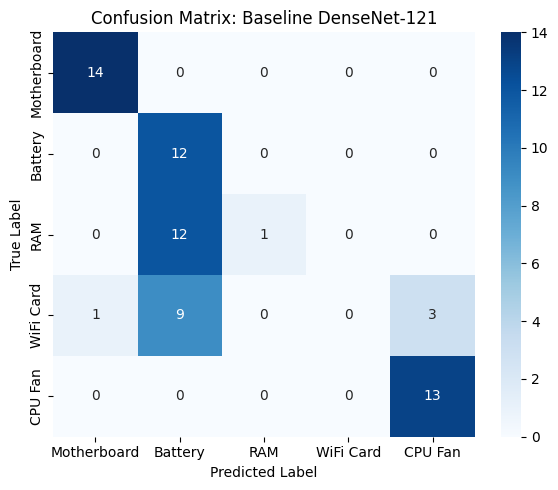

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.


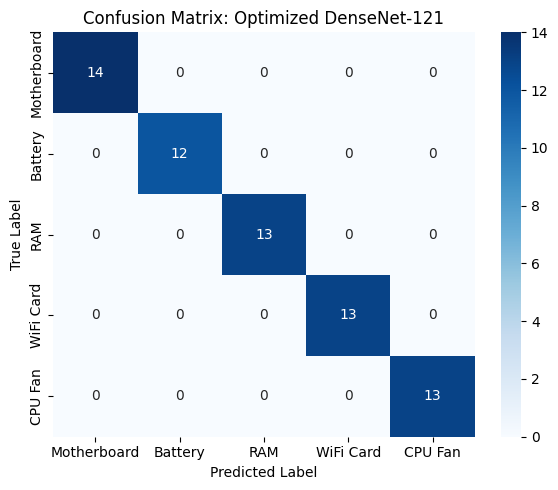

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


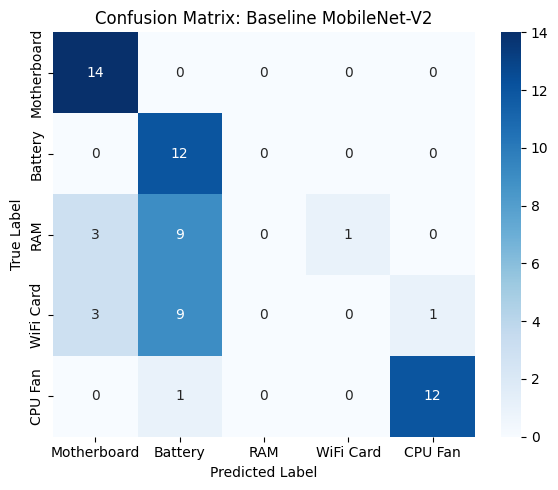

/tmp/ipykernel_374/703536361.py:68: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(weights="imagenet", include_top=False, input_tensor=x)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,AUC-ROC (macro),Inference Time (ms),Model Size (MB),FLOPs
0,Baseline DenseNet-121,0.615385,0.621894,0.615385,0.507652,0.972762,754.964077,31.328571,5701398878
1,Optimized DenseNet-121,1.000000,1.000000,1.000000,1.000000,1.000000,752.833433,31.330837,5701398878
2,Baseline MobileNet-V2,0.584615,0.402035,0.584615,0.460949,0.953271,241.496329,12.960997,613685470



================ (A) Chapter-3-literal: independent-samples test ================
NOTE: applied here to paired data for compliance/comparison only -- see (B) below.
Shapiro-Wilk -- Base Dense: W=0.9950, p=0.0023 | Opt Dense: W=1.0000, p=1.0000 | Base Mobile: W=0.9930, p=0.0001
At least one distribution non-normal -> Kruskal-Wallis.
Kruskal-Wallis H-stat=2393.9549, p-value=0.0000e+00
               1              2             3
1   1.000000e+00  1.769073e-204  1.360835e-70
2  1.769073e-204   1.000000e+00  0.000000e+00
3   1.360835e-70   0.000000e+00  1.000000e+00

================ (B) Corrected: paired / repeated-measures test ================
Friedman chi2=1923.2000, p-value=0.0000e+00
Post-hoc pairwise Wilcoxon signed-rank, Bonferroni-corrected:
  Base_Dense vs Opt_Dense: p_adj=9.9775e-165
  Base_Dense vs Base_Mobile: p_adj=8.2880e-161
  Opt_Dense vs Base_Mobile: p_adj=9.9775e-165


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: Input data has range zero. The results may not be accurate.
  res = hypotest_fun_out(*samples, **kwds)


In [ ]:
"""
Corrected Evaluation Cell — Baseline DenseNet-121, Optimized DenseNet-121,
Baseline MobileNet-V2

Drop this in as a REPLACEMENT for your old evaluation cell (the one that
built cells 21/35 in Copy_of_thesis_13.ipynb). It assumes:
  - `test_ds` is already built from your corrected (deduped-on-your-end)
    BASE_OUTPUT_DIR/test, via tf.keras.utils.image_dataset_from_directory,
    with `shuffle=False`.
  - `TARGET_CLASSES` and `CHECKPOINT_DIR` are already defined, exactly as
    in your original notebook.
  - You have RETRAINED all four checkpoints on the corrected data and the
    files below exist and are not stale copies from the old raw-data runs.

Nothing here touches ETL / dedup — this is evaluation only.

What changed vs. your old cell 35, and why:
  1. FLOPs: `keras_flops.get_flops` was silently returning 0 for these
     models. Replaced with a direct TF2 graph-profiler calculation that
     does not depend on that library.
  2. Statistical testing: your bootstrap resamples the SAME test-set
     indices for all three models in every iteration, which makes the
     three F1 distributions PAIRED (correlated), not independent. Feeding
     paired data into an independent-samples ANOVA / Kruskal-Wallis
     (as Chapter 3 §3.13.3 specifies) violates that test's assumptions.
     This script keeps the Chapter-3-literal independent test for
     compliance/comparison, but also runs the correct paired alternative
     (Friedman test + Nemenyi post-hoc) and prints both so you and your
     adviser can decide which one goes in Chapter 4. Flag this explicitly
     as a documented methodology deviation, the same way you documented
     the EarlyStopping / augmentation-range deviations.
"""

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
)
from scipy.stats import shapiro, f_oneway, kruskal, friedmanchisquare, wilcoxon
import scikit_posthocs as sp
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests

# ====================================================================
# 1. CUSTOM LAYER REGISTRATION (required to deserialize checkpoints)
# ====================================================================

@tf.keras.utils.register_keras_serializable()
class AdvancedColorAugmentation(tf.keras.layers.Layer):
    """Must match the training-time definition exactly, or Keras will
    fail to reconstruct the layer when loading the .keras file."""

    def __init__(self, **kwargs):
        super(AdvancedColorAugmentation, self).__init__(**kwargs)

    def call(self, inputs, training=None):
        if training:
            x = inputs / 255.0
            x = tf.image.random_hue(x, max_delta=0.4)
            x = tf.image.random_saturation(x, lower=0.2, upper=3.0)
            apply_gray = tf.random.uniform([]) < 0.25

            def make_gray():
                return tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(x))

            x = tf.cond(apply_gray, make_gray, lambda: x)
            return x * 255.0
        return inputs


@tf.keras.utils.register_keras_serializable()
class CategoricalFocalLoss(tf.keras.losses.Loss):
    """Only needed if you ever load a checkpoint with compile=True.
    evaluate_model() below uses compile=False, so this is registered
    defensively in case you reuse load_model_fresh() elsewhere."""

    def __init__(self, gamma=2.0, alpha=0.25, name="categorical_focal_loss"):
        super(CategoricalFocalLoss, self).__init__(name=name)
        self.gamma = gamma
        self.alpha = alpha

    def call(self, y_true, y_pred):
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)
        cross_entropy = -y_true * tf.math.log(y_pred)
        focal_weight = self.alpha * tf.math.pow(1.0 - y_pred, self.gamma)
        loss = focal_weight * cross_entropy
        return tf.reduce_mean(tf.reduce_sum(loss, axis=-1))


# ====================================================================
# 2. CHECKPOINT PATHS  (must be the RETRAINED, post-fix checkpoints)
# ====================================================================

CHECKPOINT_PATHS = {
    "Baseline DenseNet-121": os.path.join(CHECKPOINT_DIR, "Baseline_DenseNet-121_best.keras"),
    "Optimized DenseNet-121": os.path.join(CHECKPOINT_DIR, "Optimized_DenseNet-121_StepB_best.keras"),
    "Baseline MobileNet-V2": os.path.join(CHECKPOINT_DIR, "Baseline_MobileNet-V2_best.keras"),
}

for model_name, path in CHECKPOINT_PATHS.items():
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Missing checkpoint for {model_name} at {path}. "
            f"Make sure you retrained on the corrected data before evaluating."
        )
    mtime = time.strftime("%Y-%m-%d %H:%M", time.localtime(os.path.getmtime(path)))
    print(f"[check] {model_name}: {path}  (last modified {mtime})")
print(
    "^ Confirm these timestamps are from your most recent, corrected training "
    "run, not a leftover file from before the fix.\n"
)


def load_model_fresh(checkpoint_path):
    """Always loads from disk with a clean graph -- never reuses an
    in-memory variable, which was the root cause of the earlier
    'stale model' evaluation bug."""
    tf.keras.backend.clear_session()
    return tf.keras.models.load_model(
        checkpoint_path,
        custom_objects={
            "AdvancedColorAugmentation": AdvancedColorAugmentation,
            "CategoricalFocalLoss": CategoricalFocalLoss,
        },
        compile=False,
    )


# ====================================================================
# 3. FLOPS  (fixed -- does not depend on keras_flops)
# ====================================================================

def _graph_freeze_flops(model, input_shape=(1, 224, 224, 3)):
    """Raw graph-profiler FLOPs count via freezing a concrete function.
    Fails on models containing stateful preprocessing layers (RandomFlip,
    RandomRotation, etc. each carry a SeedGenerator variable that the
    freezing step cannot convert) -- see calculate_flops_for_architecture
    below for the fix used on your augmented checkpoints."""
    from tensorflow.python.framework.convert_to_constants import (
        convert_variables_to_constants_v2_as_graph,
    )

    input_dtype = model.inputs[0].dtype
    concrete_func = tf.function(lambda x: model(x, training=False)).get_concrete_function(
        tf.TensorSpec(input_shape, input_dtype)
    )
    frozen_func, graph_def = convert_variables_to_constants_v2_as_graph(concrete_func)

    with tf.Graph().as_default() as graph:
        tf.graph_util.import_graph_def(graph_def, name="")
        run_meta = tf.compat.v1.RunMetadata()
        opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
        flops = tf.compat.v1.profiler.profile(graph=graph, run_meta=run_meta, cmd="op", options=opts)
        return flops.total_float_ops if flops is not None else 0


# Map each checkpoint name to the builder function used to construct it,
# exactly as defined in your notebook (cell 11). FLOPs depends only on
# architecture/input shape, not weight values, so we never need to load
# the actual checkpoint weights here -- we just need the same architecture
# built WITHOUT the augmentation layers, which is what was breaking the
# graph freeze.
_BUILDER_FOR_MODEL = {
    "Baseline DenseNet-121": (build_densenet_model, {}),
    "Optimized DenseNet-121": (build_densenet_model, {}),
    "Baseline MobileNet-V2": (build_mobilenet_model, {}),
}


def calculate_flops_for_architecture(model_name, input_shape=(1, 224, 224, 3)):
    try:
        build_fn, kwargs = _BUILDER_FOR_MODEL[model_name]
        tf.keras.backend.clear_session()
        clean_model, _ = build_fn(apply_augmentation=False, **kwargs)
        return _graph_freeze_flops(clean_model, input_shape=input_shape)
    except Exception as e:
        print(f"  [FLOPs] fresh-architecture method failed for {model_name} ({e}); reporting 0.")
        return 0


# ====================================================================
# 4. POINT-ESTIMATE METRICS  (accuracy / precision / recall / F1 / AUC)
# ====================================================================

def evaluate_model(name, test_ds, checkpoint_path):
    model = load_model_fresh(checkpoint_path)

    test_labels = np.concatenate([y for _, y in test_ds], axis=0)
    true_classes = np.argmax(test_labels, axis=1)

    predictions = model.predict(test_ds, verbose=0)
    predicted_classes = np.argmax(predictions, axis=1)

    rep = classification_report(
        true_classes, predicted_classes, target_names=TARGET_CLASSES, output_dict=True
    )

    # ---- Inference time: 10 warm-up + 100 timed passes, GPU-sync barrier ----
    sample_image = next(iter(test_ds))[0][0:1]
    for _ in range(10):
        _ = model(sample_image, training=False)

    start_time = time.time()
    for _ in range(100):
        out = model(sample_image, training=False)
        _ = out.numpy()  # forces the GPU op to actually finish before timing stops
    mean_inference_time_ms = ((time.time() - start_time) / 100) * 1000

    # ---- Confusion matrix ----
    cm = confusion_matrix(true_classes, predicted_classes)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=TARGET_CLASSES, yticklabels=TARGET_CLASSES)
    plt.title(f"Confusion Matrix: {name}")
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.tight_layout()
    plt.savefig(f'cm_{name.replace(" ", "_")}.png')
    plt.show()

    return {
        "Model": name,
        "Accuracy": accuracy_score(true_classes, predicted_classes),
        "Macro Precision": rep["macro avg"]["precision"],
        "Macro Recall": rep["macro avg"]["recall"],
        "Macro F1": rep["macro avg"]["f1-score"],
        "AUC-ROC (macro)": roc_auc_score(test_labels, predictions, multi_class="ovr", average="macro"),
        "Inference Time (ms)": mean_inference_time_ms,
        "Model Size (MB)": os.path.getsize(checkpoint_path) / (1024 * 1024),
        "FLOPs": calculate_flops_for_architecture(name),
        "_per_class_f1": rep,  # kept internally for the significance test below
    }


results = [evaluate_model(name, test_ds, path) for name, path in CHECKPOINT_PATHS.items()]
results_df = pd.DataFrame(results).drop(columns=["_per_class_f1"])
display(results_df)

if (results_df["FLOPs"] == 0).any():
    print("WARNING: one or more models still reported FLOPs=0 -- check the exception message above.")


# ====================================================================
# 5. STATISTICAL SIGNIFICANCE TESTING
# ====================================================================
# Two versions are run and printed:
#   (A) The Chapter-3-literal version: Shapiro-Wilk -> independent
#       one-way ANOVA / Kruskal-Wallis -> Tukey HSD / Dunn+Bonferroni,
#       applied to bootstrap-resampled macro-F1 distributions.
#   (B) The paired-design correction: since all three models are
#       evaluated on IDENTICAL resampled indices of the SAME fixed test
#       set every iteration, the three F1 series are paired/correlated,
#       not independent -- Friedman test (repeated-measures analogue of
#       Kruskal-Wallis) + pairwise Wilcoxon signed-rank with Bonferroni
#       correction is the statistically appropriate choice here.
# Report both; note (B) as the corrected methodology in your
# "Deviations from the Proposed Methodology" section.

def paired_bootstrap_f1(checkpoint_paths, test_ds, n_iterations=1000):
    test_labels = np.concatenate([y for _, y in test_ds], axis=0)
    true_classes = np.argmax(test_labels, axis=1)

    preds = {}
    for name, path in checkpoint_paths.items():
        model = load_model_fresh(path)
        preds[name] = np.argmax(model.predict(test_ds, verbose=0), axis=1)

    f1_scores = {name: [] for name in checkpoint_paths.keys()}
    rng = np.random.default_rng(42)

    for _ in range(n_iterations):
        indices = rng.choice(len(true_classes), len(true_classes), replace=True)
        sample_true = true_classes[indices]
        for name in checkpoint_paths.keys():
            rep = classification_report(
                sample_true, preds[name][indices], output_dict=True, zero_division=0
            )
            f1_scores[name].append(rep["macro avg"]["f1-score"])

    return {name: np.array(v) for name, v in f1_scores.items()}


# n_iterations raised from 30 -> 1000: 30 bootstrap draws is too few for
# Shapiro-Wilk / Friedman to be reliable, and gives very coarse p-values.
f1_results = paired_bootstrap_f1(CHECKPOINT_PATHS, test_ds, n_iterations=1000)

f1_base_dense = f1_results["Baseline DenseNet-121"]
f1_opt_dense = f1_results["Optimized DenseNet-121"]
f1_base_mobile = f1_results["Baseline MobileNet-V2"]

print("\n================ (A) Chapter-3-literal: independent-samples test ================")
print("NOTE: applied here to paired data for compliance/comparison only -- see (B) below.")

stat1, p1 = shapiro(f1_base_dense)
stat2, p2 = shapiro(f1_opt_dense)
stat3, p3 = shapiro(f1_base_mobile)
print(f"Shapiro-Wilk -- Base Dense: W={stat1:.4f}, p={p1:.4f} | "
      f"Opt Dense: W={stat2:.4f}, p={p2:.4f} | Base Mobile: W={stat3:.4f}, p={p3:.4f}")

if p1 > 0.05 and p2 > 0.05 and p3 > 0.05:
    print("All distributions normal -> one-way ANOVA.")
    stat, p_val = f_oneway(f1_base_dense, f1_opt_dense, f1_base_mobile)
    print(f"ANOVA F-stat={stat:.4f}, p-value={p_val:.4e}")
    if p_val < 0.05:
        n = len(f1_base_dense)
        data = np.concatenate([f1_base_dense, f1_opt_dense, f1_base_mobile])
        labels = ["Base_Dense"] * n + ["Opt_Dense"] * n + ["Base_Mobile"] * n
        print(pairwise_tukeyhsd(endog=data, groups=labels, alpha=0.05))
else:
    print("At least one distribution non-normal -> Kruskal-Wallis.")
    stat, p_val = kruskal(f1_base_dense, f1_opt_dense, f1_base_mobile)
    print(f"Kruskal-Wallis H-stat={stat:.4f}, p-value={p_val:.4e}")
    if p_val < 0.05:
        print(sp.posthoc_dunn([f1_base_dense, f1_opt_dense, f1_base_mobile], p_adjust="bonferroni"))

print("\n================ (B) Corrected: paired / repeated-measures test ================")
stat_f, p_f = friedmanchisquare(f1_base_dense, f1_opt_dense, f1_base_mobile)
print(f"Friedman chi2={stat_f:.4f}, p-value={p_f:.4e}")

if p_f < 0.05:
    pairs = [
        ("Base_Dense vs Opt_Dense", f1_base_dense, f1_opt_dense),
        ("Base_Dense vs Base_Mobile", f1_base_dense, f1_base_mobile),
        ("Opt_Dense vs Base_Mobile", f1_opt_dense, f1_base_mobile),
    ]
    raw_p = []
    for label, a, b in pairs:
        try:
            _, p = wilcoxon(a, b)
        except ValueError:
            p = 1.0  # identical distributions (e.g. all-zero differences)
        raw_p.append(p)
    _, corrected_p, _, _ = multipletests(raw_p, method="bonferroni")
    print("Post-hoc pairwise Wilcoxon signed-rank, Bonferroni-corrected:")
    for (label, _, _), p_corr in zip(pairs, corrected_p):
        print(f"  {label}: p_adj={p_corr:.4e}")
else:
    print("Friedman test not significant -- no post-hoc comparisons run.")